<html>
  <body>
    <header></header>
        <CENTER>
          <img src="https://professor.uvv.br/Content/img/logo-uvv.png" alt="UVV-LOGO" style = width="100px"; height="100px">
        </CENTER>
        <CENTER><b>DATA SCIENCE PROJECT</b></CENTER><br/>
        <CENTER><b>WORKFLOW PARTE 2 DO PROJETO</b></CENTER><br/>

# BIBLIOTECAS E FUNÇÕES E CÓDIGOS

## Load dos Datasets:

In [ ]:
# =====================================================================
# BIBLIOTECAS
# =====================================================================
import warnings

warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.diagnostic import normal_ad, het_breuschpagan
import statsmodels.api as sm

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score,
    adjusted_rand_score,
)

# Regressores
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor,
)

# Clusterizador
from sklearn.cluster import KMeans

# Classificadores (lista do enunciado – A3.3)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# =====================================================================
# PARÂMETROS GLOBAIS DO PROJETO (os mesmos da Parte 1)
# =====================================================================
SEED = 42  # semente: reprodutibilidade
ALPHA = 0.05  # nível de significância
CONFIANCA = 0.95  # nível de confiança dos intervalos
N_BOOT = 1000  # reamostragens bootstrap
K_FOLDS = 10  # folds da validação cruzada
TARGET_REG = "TOTAL (R$)"  # y do REGRESSOR
TARGET_CLF = "TIPO DA CONTA"  # y do CLASSIFICADOR
ESTRATO = "TIPO DA CONTA"  # variável de estratificação (Parte 1)
ORDEM_CONTA = ["ESSENTIAL", "VIP", "PRIME"]
CORES_CONTA = {"ESSENTIAL": "#2a78d6", "VIP": "#eb6834", "PRIME": "#1baf7a"}
CORES_CONJ = {
    "TRAIN": "#2a78d6",
    "VALIDATION": "#eb6834",
    "TEST": "#1baf7a",
    "SAMPLE": "#6250d6",
}
QUIMICAS = None  # definido após o load (colunas MEAN:*)
RESULTADOS = {}  # todos os números dos relatórios saem daqui


# =====================================================================
# FUNÇÕES AUXILIARES
# =====================================================================
def br(x, casas=2):
    """Formata número no padrão brasileiro (1.234,56)."""
    return (
        f"{x:,.{casas}f}".replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )


def br_p(p):
    """Formata p-valor (padrão brasileiro)."""
    return "< 0,0001" if p < 1e-4 else br(p, 4)


def decisao(p, alpha=ALPHA):
    """
    Texto da decisão de um teste de hipóteses (sem afirmar H0 como verdade).
    """
    return "Rejeita-se H0" if p <= alpha else "Não se rejeitou H0"


def checar_finitos(obj, nome):
    """
    Garante que não há NaN/infinito numa saída numérica (correção da Parte
    1).
    """
    arr = np.asarray(pd.DataFrame(obj).select_dtypes("number"), dtype=float)
    if not np.isfinite(arr).all():
        raise ValueError(
            f"{nome}: existem valores NaN/infinitos – revisar antes de"
            " seguir."
        )
    return True


def bootstrap_media(valores, n_boot=N_BOOT, conf=CONFIANCA, seed=SEED):
    """Bootstrap (percentil) da MÉDIA de um vetor: retorna média, IC e EP."""
    valores = np.asarray(valores, dtype=float)
    rng = np.random.default_rng(seed)
    medias = rng.choice(
        valores, size=(n_boot, len(valores)), replace=True
    ).mean(axis=1)
    a = (1 - conf) / 2
    return {
        "estimativa": valores.mean(),
        "ic_inf": np.quantile(medias, a),
        "ic_sup": np.quantile(medias, 1 - a),
        "ep": medias.std(ddof=1),
        "dist": medias,
    }


def bootstrap_metrica(
    y_true, y_pred, metrica, n_boot=N_BOOT, conf=CONFIANCA, seed=SEED
):
    """
    Bootstrap (percentil) de uma MÉTRICA (R², acurácia...) reamostrando as
    linhas.
    """
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    dist = np.empty(n_boot)
    for b in range(n_boot):
        i = rng.integers(0, n, n)
        dist[b] = metrica(y_true[i], y_pred[i])
    a = (1 - conf) / 2
    return {
        "estimativa": metrica(y_true, y_pred),
        "ic_inf": np.quantile(dist, a),
        "ic_sup": np.quantile(dist, 1 - a),
        "ep": dist.std(ddof=1),
        "dist": dist,
    }


def plot_bootstrap(boot, titulo, xlabel, cor="#2a78d6", ax=None):
    """Histograma da distribuição bootstrap com o IC (linhas tracejadas)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.hist(boot["dist"], bins=40, color=cor, alpha=0.85, edgecolor="white")
    for v in (boot["ic_inf"], boot["ic_sup"]):
        ax.axvline(v, color="#52514e", ls="--", lw=1.5)
    ax.axvline(boot["estimativa"], color="#0b0b0b", lw=2)
    ax.set_title(titulo, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequência")
    return ax


# ---------------------------------------------------------------------
# Discretização da OPINIÃO DO CLIENTE (mesma escala da Parte 1 – A3.1)
# ---------------------------------------------------------------------
ESCALA_SATISFACAO = [
    "Muito insatisfeito",
    "Insatisfeito",
    "Indiferente",
    "Satisfeito",
    "Muito satisfeito",
]
FRASE_PRODUTO_PERFEITO = (
    "Produto perfeito, chegou antes do prazo de "
    "previsão. Top demais a UVVine"
)
MAPA_OPINIAO = {
    # Muito satisfeito
    "Serviço impecável, adorei o clube: UVVine": "Muito satisfeito",
    "Superou expectativas o atendimento na UVVine": "Muito satisfeito",
    "Ótimo! Tudo ocorreu maravilhosamente bem com a UVVine": (
        "Muito satisfeito"
    ),
    FRASE_PRODUTO_PERFEITO: "Muito satisfeito",
    "Excelente experiência, recomendo muito a UVVine": "Muito satisfeito",
    # Satisfeito
    "Entrega foi boa e rápida na UVVine": "Satisfeito",
    "Funcionou bem e me atendeu no prazo certo a UVVine": "Satisfeito",
    "Fiquei satisfeito com o serviço da UVVine": "Satisfeito",
    "Serviço eficiente, recomendo o clube: UVVine": "Satisfeito",
    "Gostei do atendimento prestado pela UVVine": "Satisfeito",
    # Indiferente
    "Nada digno de nota com a UVVine": "Indiferente",
    "Foi indiferente minha experiência com a UVVine": "Indiferente",
    "Não tenho muito a dizer sobre a UVVine": "Indiferente",
    "Sem opinião formada sobre a UVVine": "Indiferente",
    "Compro exponenciamente, opinião neutra sobre UVVine": "Indiferente",
    # Insatisfeito
    "Atendimento comum, poderia melhorar em cordialidade a UVVine": (
        "Insatisfeito"
    ),
    "Nada demais, serviço regular na UVVine": "Insatisfeito",
    "Experiência regular, não atendeu a política de cashback da UVVine": (
        "Insatisfeito"
    ),
    "Foi aceitável, esperava mais da UVVine": "Insatisfeito",
    "Razoável, com margem de melhora no preço médio da UVVine": (
        "Insatisfeito"
    ),
    # Muito insatisfeito
    "Senti que faltou qualidade no atendimento da UVVine": (
        "Muito insatisfeito"
    ),
    "Tive uma experiência ruim com a UVVine": "Muito insatisfeito",
    "Não gostei do atendimento na UVVine": "Muito insatisfeito",
    "Serviço deixou a desejar na UVVine": "Muito insatisfeito",
    "Produto chegou atrasado na UVVine": "Muito insatisfeito",
}

REGIOES = ["CENTRO-OESTE", "NORDESTE", "NORTE", "SUDESTE", "SUL"]
ESTADOS_CIVIS = ["CASADO", "SOLTEIRO", "DESQUITADO(A) / VIÚVO(A)"]


def preparar_base(df, medianas_quimicas):
    """
    MAPEAR – DISCRETIZAR – TRATAR (sem normalizar).

    1) Variáveis químicas MEAN:*: valores negativos (fisicamente impossíveis,
       Parte 1 – A1.2) viram NaN e são preenchidos com a MEDIANA DO TRAIN
       (a mediana é robusta e, por vir só do TRAIN, não há vazamento de
       informação dos conjuntos de validação/teste).
    2) Mapeamento das qualitativas:
       SEXO -> SEXO_FEMININO (0/1); REGIÃO e ESTADO CIVIL -> one-hot com
       categorias fixas (a 1ª é a referência, evitando colinearidade);
       TIPO DA CONTA -> ordinal (ESSENTIAL=0 < VIP=1 < PRIME=2).
    3) Discretização: OPINIÃO DO CLIENTE -> SATISFAÇÃO (1-5) (escala da
        Parte 1).

    Returns
    -------
    pandas.DataFrame com as variáveis numéricas prontas para a modelagem.
    """
    out = pd.DataFrame(index=df.index)
    out["RENDA BRUTO (R$)"] = df["RENDA BRUTO (R$)"]
    out["TOTAL (R$)"] = df["TOTAL (R$)"]
    out["DEPENDENTES"] = df["DEPENDENTES"]
    out["NOTA DE SATISFAÇÃO (%)"] = df["NOTA DE SATISFAÇÃO (%)"]
    texto = df["OPINIÃO DO CLIENTE"].str.split().str.join(" ")
    nivel = pd.Categorical(
        texto.map(MAPA_OPINIAO), categories=ESCALA_SATISFACAO, ordered=True
    )
    if pd.isna(nivel).any():
        raise ValueError("Há frases de OPINIÃO DO CLIENTE não mapeadas.")
    out["SATISFAÇÃO (1-5)"] = nivel.codes + 1
    out["SEXO_FEMININO"] = (df["SEXO"] == "FEMININO").astype(int)
    for r in REGIOES[1:]:
        out[f"REGIÃO_{r}"] = (df["REGIÃO"] == r).astype(int)
    for e in ESTADOS_CIVIS[1:]:
        out[f"ESTADO CIVIL_{e}"] = (df["ESTADO CIVIL"] == e).astype(int)
    out["TIPO DA CONTA (ordinal)"] = df["TIPO DA CONTA"].map(
        {c: i for i, c in enumerate(ORDEM_CONTA)}
    )
    for c in QUIMICAS:
        out[c] = (
            df[c].where(df[c] >= 0, np.nan).fillna(medianas_quimicas[c])
        )
    checar_finitos(out, "preparar_base")
    return out


# Variáveis ORIGINAIS candidatas e as colunas codificadas que cada uma gera
GRUPOS_VARIAVEIS = {
    "RENDA BRUTO (R$)": ("numérica", ["RENDA BRUTO (R$)"]),
    "TOTAL (R$)": ("numérica", ["TOTAL (R$)"]),
    "DEPENDENTES": ("numérica", ["DEPENDENTES"]),
    "NOTA DE SATISFAÇÃO (%)": ("numérica", ["NOTA DE SATISFAÇÃO (%)"]),
    "SATISFAÇÃO (1-5)": ("ordinal", ["SATISFAÇÃO (1-5)"]),
    "TIPO DA CONTA": ("ordinal", ["TIPO DA CONTA (ordinal)"]),
    "SEXO": ("nominal", ["SEXO_FEMININO"]),
    "REGIÃO": ("nominal", [f"REGIÃO_{r}" for r in REGIOES[1:]]),
    "ESTADO CIVIL": (
        "nominal",
        [f"ESTADO CIVIL_{e}" for e in ESTADOS_CIVIS[1:]],
    ),
}


def cramers_v(tabela):
    """V de Cramér (força de associação entre duas qualitativas)."""
    chi2 = stats.chi2_contingency(tabela)[0]
    n = tabela.to_numpy().sum()
    return np.sqrt(chi2 / (n * (min(tabela.shape) - 1)))


def selecionar_variaveis(
    df_original, alvo, tipo_alvo, candidatas, alpha=ALPHA
):
    """
    Seleção de variáveis de entrada (X) feita SOMENTE no TRAIN.

    Critério (dupla exigência, para não selecionar efeitos desprezíveis só
    porque n é grande):
      (1) significância estatística com correção de Bonferroni: p < α / m;
      (2) tamanho de efeito pelo menos PEQUENO (Cohen):
          |ρ de Spearman| >= 0,10 | ε² de Kruskal-Wallis >= 0,01 | V de
              Cramér >= 0,10.

    Medida usada conforme o tipo de variável:
      alvo numérico  x candidata numérica/ordinal -> Spearman
      alvo numérico  x candidata nominal          -> Kruskal-Wallis (ε²)
      alvo nominal   x candidata numérica/ordinal -> Kruskal-Wallis (ε²)
      alvo nominal   x candidata nominal          -> Qui-quadrado (V de
          Cramér)
    """
    m = len(candidatas)
    linhas = []
    for var in candidatas:
        tipo_var = (
            GRUPOS_VARIAVEIS[var][0]
            if var in GRUPOS_VARIAVEIS
            else "numérica"
        )
        x, y = df_original[var], df_original[alvo]
        if tipo_alvo == "numérico" and tipo_var in ("numérica", "ordinal"):
            if var == "TIPO DA CONTA":
                x = x.map({c: i for i, c in enumerate(ORDEM_CONTA)})
            r = stats.spearmanr(x, y)
            medida, efeito, p, limiar = (
                "|ρ| Spearman",
                abs(r.statistic),
                r.pvalue,
                0.10,
            )
        elif tipo_var == "nominal" and tipo_alvo == "nominal":
            tab = pd.crosstab(x, y)
            p = stats.chi2_contingency(tab)[1]
            medida, efeito, limiar = "V de Cramér", cramers_v(tab), 0.10
        else:
            grupos_por, valores = (
                (x, y) if tipo_alvo == "numérico" else (y, x)
            )
            grupos = [valores[grupos_por == g] for g in grupos_por.unique()]
            H, p = stats.kruskal(*grupos)
            k, n = len(grupos), len(valores)
            medida, efeito, limiar = (
                "ε² Kruskal-Wallis",
                (H - k + 1) / (n - k),
                0.01,
            )
        linhas.append({
            "Variável": var,
            "Medida": medida,
            "Efeito": efeito,
            "Limiar (efeito pequeno)": limiar,
            "p_value": p,
            "Selecionada?": bool((p < alpha / m) and (efeito >= limiar)),
        })
    tabela = (
        pd.DataFrame(linhas)
        .set_index("Variável")
        .sort_values("Efeito", ascending=False)
    )
    return tabela


# =====================================================================
# LOAD DA BASE COMPLETA (POPULAÇÃO) – table49
# =====================================================================
# Colab: faça o upload do arquivo (ou monte o Drive e ajuste o caminho)
CAMINHO_CSV = "table49.csv"
table49 = pd.read_csv(CAMINHO_CSV, index_col=0)
QUIMICAS = [c for c in table49.columns if c.startswith("MEAN:")]

# Conferência OBRIGATÓRIA da base (correção da Parte 1: a base havia sido
# carregada incompleta, com 121.642 linhas). O notebook PARA se a carga
# falhar.
LINHAS_ESPERADAS, COLUNAS_ESPERADAS = 1_120_000, 23
assert table49.shape == (LINHAS_ESPERADAS, COLUNAS_ESPERADAS), (
    f"Base incompleta: {table49.shape} (esperado"
    f" {(LINHAS_ESPERADAS, COLUNAS_ESPERADAS)}). Refaça o upload do CSV"
    " antes de continuar."
)

qualidade = pd.DataFrame(
    {
        "Linhas": [table49.shape[0]],
        "Colunas": [table49.shape[1]],
        "Valores ausentes": [int(table49.isna().sum().sum())],
        "Notas fiscais duplicadas": [
            int(table49["NOTA FISCAL"].duplicated().sum())
        ],
    },
    index=["table49 (população)"],
)
display(qualidade)
display(
    (
        table49[ESTRATO].value_counts(normalize=True).reindex(ORDEM_CONTA)
        * 100
    )
    .round(4)
    .rename("% da população")
    .to_frame()
)
print(
    f"✅ Base completa carregada: {br(table49.shape[0], 0)} notas fiscais x"
    f" {table49.shape[1]} variáveis."
)

,Linhas,Colunas,Valores ausentes,Notas fiscais duplicadas
table49 (população),1120000,23,0,0


,% da população
TIPO DA CONTA,
ESSENTIAL,58.0113
VIP,24.1092
PRIME,17.8795


✅ Base completa carregada: 1.120.000 notas fiscais x 23 variáveis.


*Load* dos dataset aqui, a saber:

*   Conjunto de Treinamento do **TAMANHO IDEAL**: ***train***
*   Conjunto de Validação do **TAMANHO IDEAL**: ***validation***
*   Conjunto de Teste do **TAMANHO IDEAL**: ***test***

Qual o "TAMANHO IDEAL" do conjunto:

*   Conjunto de Treinamento: **n = 50.300** notas fiscais
*   Conjunto de Validação: **n = 50.300** notas fiscais
*   Conjunto de Teste: **n = 50.300** notas fiscais

**Justificativa (continuidade da Parte 1):** o tamanho ideal foi definido na Atividade A1.1 da Parte 1 pelo procedimento teórico-empírico (estratificação por TIPO DA CONTA + alocação de Neyman + estabilização da redução marginal relativa do erro-padrão < 0,1% por 3 incrementos consecutivos). Na célula abaixo o mesmo procedimento é **recalculado sobre a base completa** (1.120.000 notas), e o código confere que o resultado continua sendo 50.300.

**Desenho amostral efetivamente usado (documentado conforme a correção da Parte 1):**

*   **Tamanho** de cada conjunto: n = 50.300 (critério de Neyman acima).
*   **Alocação** entre os estratos: **proporcional** ao peso de cada TIPO DA CONTA na população, com arredondamento pelo método dos maiores restos, para que a soma dos estratos seja **exatamente** 50.300. A alocação proporcional é a adequada para Machine Learning porque mantém nos três conjuntos a mesma proporção de classes da população (divisão estratificada), condição para que o modelo treinado represente a população.
*   Os três conjuntos são **disjuntos** (nenhuma nota fiscal em comum), sorteados sem reposição com `SEED = 42`: *train* = SAMPLE 1, *validation* = SAMPLE 2 e *test* = SAMPLE 3.
*   **Amostra da população (Sample)** para os passos "Testar o Modelo" (A1.5, A2.7 e A3.5): amostra aleatória simples de 50.300 notas sorteadas **somente entre as notas que não estão** em *train*, *validation* ou *test*. Ela simula notas fiscais novas, que o modelo nunca viu.

Os números conferidos (tamanhos, proporções e testes de representatividade) são exibidos pela célula abaixo.

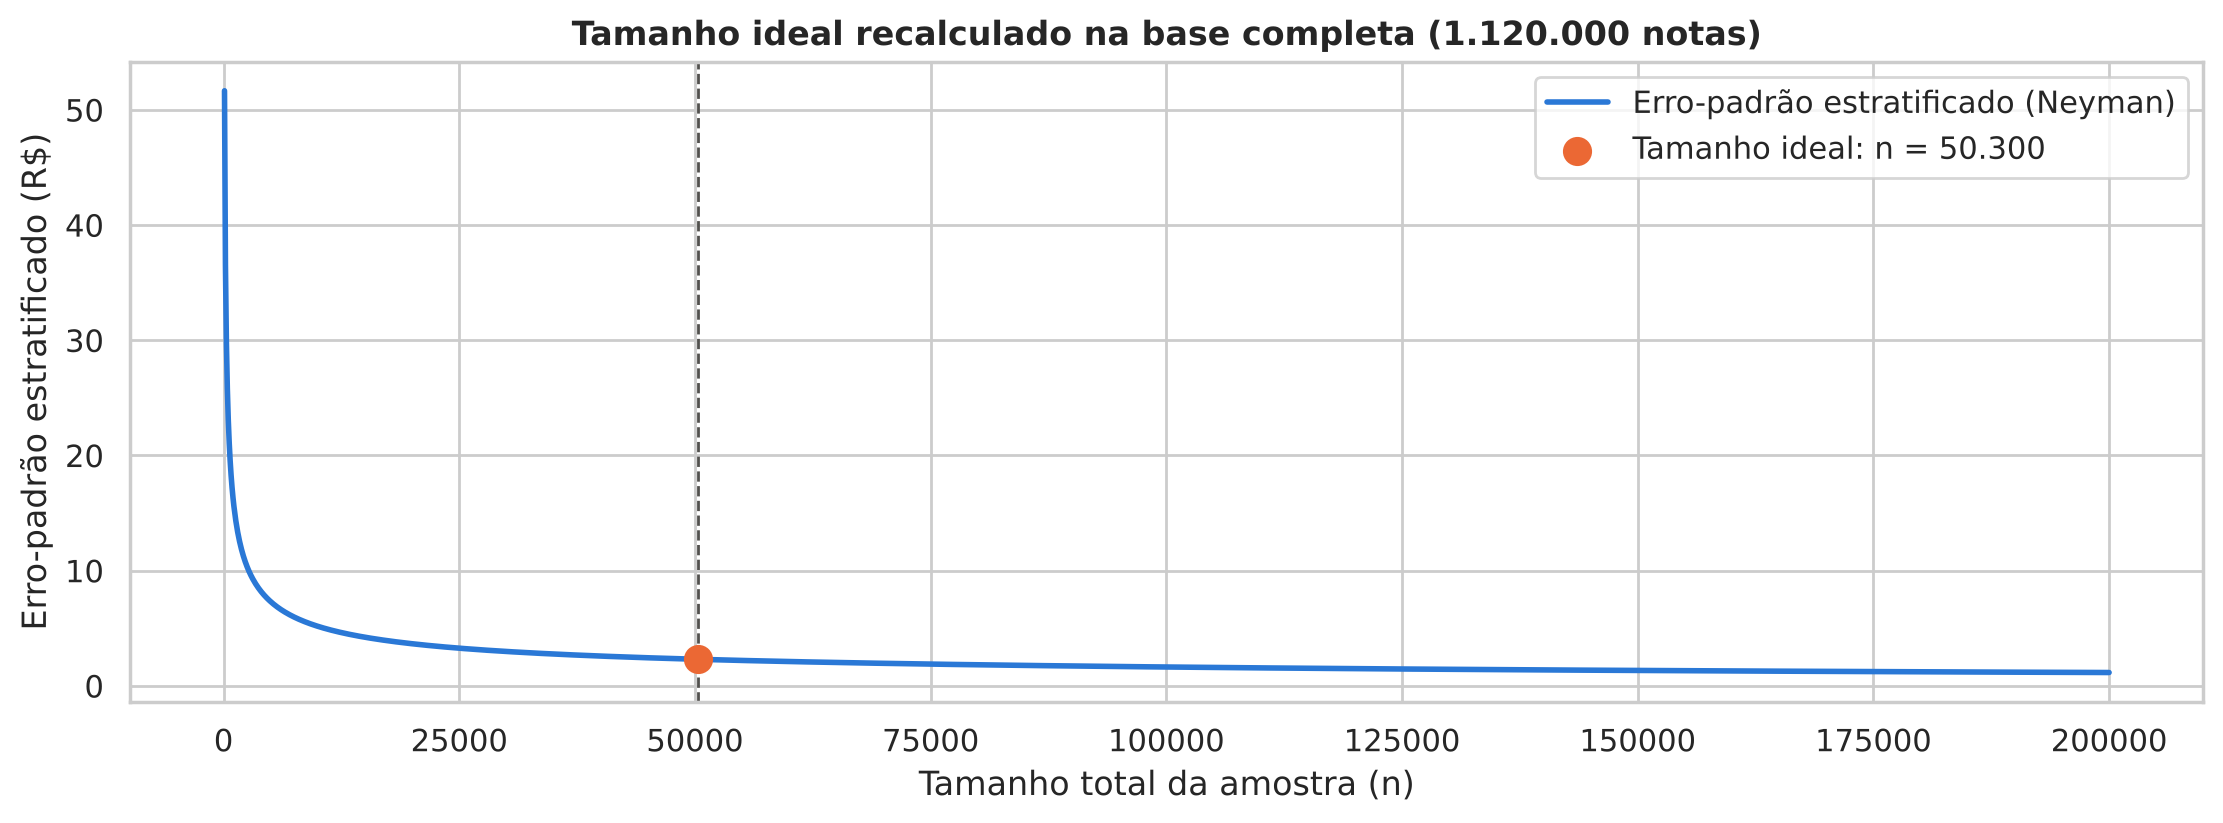

### Tamanho de cada conjunto e n por estrato

,População,TRAIN,VALIDATION,TEST,SAMPLE
n (linhas),1120000,50300,50300,50300,50300


,TRAIN,VALIDATION,TEST,SAMPLE
TIPO DA CONTA,,,,
ESSENTIAL,29180,29180,29180,29105
VIP,12127,12127,12127,12175
PRIME,8993,8993,8993,9020
SOMA,50300,50300,50300,50300


### Proporção (%) de TIPO DA CONTA em cada conjunto x população

,População,% TRAIN,% VALIDATION,% TEST,% SAMPLE
TIPO DA CONTA,,,,,
ESSENTIAL,58.0113,58.0119,58.0119,58.0119,57.8628
VIP,24.1092,24.1093,24.1093,24.1093,24.2048
PRIME,17.8795,17.8787,17.8787,17.8787,17.9324


### Média de TOTAL (R$) por estrato em cada conjunto

,População,TRAIN,VALIDATION,TEST,SAMPLE
TIPO DA CONTA,,,,,
ESSENTIAL,428.33,426.77,426.48,429.53,424.76
VIP,932.28,933.95,931.79,943.89,936.69
PRIME,2115.28,2111.80,2108.57,2114.82,2108.65
GERAL,851.45,850.31,849.04,854.85,850.63


### Testes de representatividade (H0: mesma proporção / mesma distribuição)

,p_value,Decisão (α = 5%)
Teste,,
Qui² aderência – TIPO DA CONTA (TRAIN x população),1.0000,Não se rejeitou H0
Qui² aderência – TIPO DA CONTA (VALIDATION x população),1.0000,Não se rejeitou H0
Qui² aderência – TIPO DA CONTA (TEST x população),1.0000,Não se rejeitou H0
Qui² aderência – TIPO DA CONTA (SAMPLE x população),0.7943,Não se rejeitou H0
Kolmogorov-Smirnov – TOTAL (TRAIN x VALIDATION),0.8882,Não se rejeitou H0
Kolmogorov-Smirnov – TOTAL (TRAIN x TEST),0.5208,Não se rejeitou H0
Kolmogorov-Smirnov – TOTAL (TRAIN x SAMPLE),0.2661,Não se rejeitou H0


**Conclusão:** o tamanho ideal recalculado na base completa é **n = 50.300** (EP estratificado de Neyman = R$ 2,3033). Alocação proporcional por estrato: ESSENTIAL 29.180 | VIP 12.127 | PRIME 8.993 (soma = 50.300). TRAIN, VALIDATION, TEST e SAMPLE têm 50.300 notas cada e **0 notas em comum**. A SAMPLE foi sorteada entre as 969.100 notas não usadas nos três conjuntos. Em 7 de 7 testes de representatividade **não se rejeitou H0** (proporções e distribuição de TOTAL compatíveis com a população); isso não prova igualdade, mas não há evidência de diferença.

In [ ]:
# =====================================================================
# 1) TAMANHO IDEAL – recálculo sobre a BASE COMPLETA (procedimento da Parte 1)
# =====================================================================
def optimal_stratified_sample_size(
    df,
    value_column,
    strata_column,
    n_min=100,
    n_max=200_000,
    step=100,
    stabilization_threshold=0.001,
    consecutive_points=3,
):
    """
    Tamanho ideal (população infinita estratificada) – alocação de Neyman e
    estabilização marginal consecutiva do erro-padrão estratificado
    (mesma função e mesmos parâmetros da Parte 1, A1.1).
    """
    data = df[[value_column, strata_column]].dropna()
    Wh = data[strata_column].value_counts(normalize=True).sort_index()
    Sh = data.groupby(strata_column)[value_column].std().loc[Wh.index]
    neyman = Wh.values * Sh.values
    sizes = np.arange(n_min, n_max + step, step)
    se = np.array([
        np.sqrt(
            np.sum(
                Wh.values**2 * Sh.values**2 / (n * neyman / neyman.sum())
            )
        )
        for n in sizes
    ])
    reducao = np.abs(np.diff(se)) / se[:-1]
    for i in range(len(reducao) - consecutive_points + 1):
        if np.all(
            reducao[i : i + consecutive_points] < stabilization_threshold
        ):
            idx = i + consecutive_points
            break
    else:
        raise ValueError("Não houve estabilização no intervalo avaliado.")
    return {
        "n_ideal": int(sizes[idx]),
        "ep": float(se[idx]),
        "sizes": sizes,
        "se": se,
        "Wh": Wh,
        "Sh": Sh,
    }


res_n = optimal_stratified_sample_size(table49, TARGET_REG, ESTRATO)
N_IDEAL = res_n["n_ideal"]
assert (
    N_IDEAL == 50_300
), "O tamanho ideal recalculado difere da Parte 1 – revisar."

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(
    res_n["sizes"],
    res_n["se"],
    color="#2a78d6",
    lw=2,
    label="Erro-padrão estratificado (Neyman)",
)
ax.scatter(
    N_IDEAL,
    res_n["ep"],
    s=90,
    color="#eb6834",
    zorder=5,
    label=f"Tamanho ideal: n = {br(N_IDEAL, 0)}",
)
ax.axvline(N_IDEAL, color="#52514e", ls="--", lw=1)
ax.set_xlabel("Tamanho total da amostra (n)")
ax.set_ylabel("Erro-padrão estratificado (R$)")
ax.set_title(
    "Tamanho ideal recalculado na base completa (1.120.000 notas)",
    fontweight="bold",
)
ax.legend()
plt.show()


# =====================================================================
# 2) TRAIN, VALIDATION, TEST (disjuntos, estratificados, proporcionais) +
# SAMPLE
# =====================================================================
def alocacao_proporcional(pesos, n):
    """
    Alocação proporcional com maiores restos: a soma dos estratos é
    exatamente n.
    """
    bruto = pesos * n
    nh = np.floor(bruto).astype(int)
    faltam = n - nh.sum()
    nh[(bruto - nh).sort_values(ascending=False).index[:faltam]] += 1
    return nh


def gerar_conjuntos(df, n, strata_column=ESTRATO, seed=SEED):
    """
    Sorteia TRAIN, VALIDATION e TEST disjuntos (n linhas cada) e a SAMPLE
    (AAS) do restante.
    """
    rng = np.random.default_rng(seed)
    nh = alocacao_proporcional(
        df[strata_column].value_counts(normalize=True), n
    )
    partes = {"train": [], "validation": [], "test": []}
    for estrato, n_h in nh.items():
        idx = df.index[df[strata_column] == estrato].to_numpy()
        sorteio = rng.choice(idx, size=3 * n_h, replace=False)
        for j, nome in enumerate(partes):
            partes[nome].append(sorteio[j * n_h : (j + 1) * n_h])
    conjuntos = {
        nome: df.loc[rng.permutation(np.concatenate(v))]
        for nome, v in partes.items()
    }
    usados = np.concatenate(
        [c.index.to_numpy() for c in conjuntos.values()]
    )
    restante = df.index.difference(usados)
    conjuntos["sample"] = df.loc[
        rng.choice(restante, size=n, replace=False)
    ]
    return conjuntos, nh


conjuntos, NH = gerar_conjuntos(table49, N_IDEAL)
train, validation, test, sample = (
    conjuntos[k].copy() for k in ["train", "validation", "test", "sample"]
)
NOMES = {
    "TRAIN": train,
    "VALIDATION": validation,
    "TEST": test,
    "SAMPLE": sample,
}

# Conferências: tamanhos, soma dos estratos e ausência de notas em comum
notas = {k: set(v["NOTA FISCAL"]) for k, v in NOMES.items()}
comuns = sum(
    len(notas[a] & notas[b])
    for i, a in enumerate(notas)
    for b in list(notas)[i + 1 :]
)
assert (
    all(len(v) == N_IDEAL for v in NOMES.values())
    and NH.sum() == N_IDEAL
    and comuns == 0
)

# Representatividade: proporções e médias de cada conjunto x população
tab = pd.DataFrame(
    {"População": table49[ESTRATO].value_counts(normalize=True) * 100}
)
for k, v in NOMES.items():
    tab[f"% {k}"] = v[ESTRATO].value_counts(normalize=True) * 100
tab = tab.reindex(ORDEM_CONTA)
tam = pd.DataFrame(
    {
        "População": [len(table49)],
        **{k: [len(v)] for k, v in NOMES.items()},
    },
    index=["n (linhas)"],
)
tam_estrato = pd.DataFrame(
    {k: v[ESTRATO].value_counts() for k, v in NOMES.items()}
).reindex(ORDEM_CONTA)
tam_estrato.loc["SOMA"] = tam_estrato.sum()
display(Markdown("### Tamanho de cada conjunto e n por estrato"))
display(tam)
display(tam_estrato)
display(
    Markdown(
        "### Proporção (%) de TIPO DA CONTA em cada conjunto x população"
    )
)
display(tab.round(4))

medias = pd.DataFrame(
    {"População": table49.groupby(ESTRATO)[TARGET_REG].mean()}
)
for k, v in NOMES.items():
    medias[k] = v.groupby(ESTRATO)[TARGET_REG].mean()
medias = medias.reindex(ORDEM_CONTA)
medias.loc["GERAL"] = [table49[TARGET_REG].mean()] + [
    v[TARGET_REG].mean() for v in NOMES.values()
]
display(Markdown("### Média de TOTAL (R$) por estrato em cada conjunto"))
display(medias.round(2))

# Testes de representatividade (cada conjunto x população / x TRAIN)
linhas = []
for k, v in NOMES.items():
    obs = v[ESTRATO].value_counts().reindex(ORDEM_CONTA)
    esp = table49[ESTRATO].value_counts(normalize=True).reindex(
        ORDEM_CONTA
    ) * len(v)
    p = stats.chisquare(obs, esp).pvalue
    linhas.append({
        "Teste": f"Qui² aderência – TIPO DA CONTA ({k} x população)",
        "p_value": p,
    })
for k in ["VALIDATION", "TEST", "SAMPLE"]:
    p = stats.ks_2samp(train[TARGET_REG], NOMES[k][TARGET_REG]).pvalue
    linhas.append(
        {"Teste": f"Kolmogorov-Smirnov – TOTAL (TRAIN x {k})", "p_value": p}
    )
testes_conj = pd.DataFrame(linhas).set_index("Teste")
testes_conj["Decisão (α = 5%)"] = testes_conj["p_value"].map(decisao)
display(
    Markdown(
        "### Testes de representatividade (H0: mesma proporção / mesma"
        " distribuição)"
    )
)
display(testes_conj.round(4))
checar_finitos(tab, "tamanhos")
checar_finitos(medias, "médias")

RESULTADOS["conjuntos"] = {
    "n_ideal": N_IDEAL,
    "ep_neyman": res_n["ep"],
    "nh": NH.to_dict(),
    "testes": testes_conj,
    "medias": medias,
    "restante": len(table49) - 3 * N_IDEAL,
}
n_rej = int((testes_conj["p_value"] <= ALPHA).sum())
display(
    Markdown(
        "**Conclusão:** o tamanho ideal recalculado na base completa é **n"
        f" = {br(N_IDEAL, 0)}** (EP estratificado de Neyman = R$"
        f" {br(res_n['ep'], 4)}). Alocação proporcional por estrato: "
        + " | ".join(f"{e} {br(NH[e], 0)}" for e in ORDEM_CONTA)
        + f" (soma = {br(NH.sum(), 0)}). TRAIN, VALIDATION, TEST e SAMPLE"
        f" têm {br(N_IDEAL, 0)} notas cada e **{comuns} notas em comum**."
        " A SAMPLE foi sorteada entre as"
        f" {br(len(table49) - 3 * N_IDEAL, 0)} notas não usadas nos três"
        f" conjuntos. Em {len(testes_conj) - n_rej} de {len(testes_conj)}"
        " testes de representatividade **não se rejeitou H0**"
        " (proporções e distribuição de TOTAL compatíveis com a"
        " população); isso não prova igualdade, mas não há evidência de"
        " diferença."
    )
)

# Workflow: Detalhamento das Atividades

#Atividade A1: Modelo de Regressão

##Atividade A1.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# =====================================================================
# A1.1 – NORMALIZAR – MAPEAR – DISCRETIZAR (y = TOTAL (R$))
# =====================================================================
# (a) Tratamento dos valores químicos negativos (recomendação da Parte 1):
#     a mediana é calculada SOMENTE no TRAIN (sem vazamento para
#     validation/test).
MEDIANAS_QUIM = train[QUIMICAS].where(train[QUIMICAS] >= 0).median()
negativos = pd.DataFrame(
    {k: (v[QUIMICAS] < 0).sum() for k, v in NOMES.items()}
)
negativos = negativos[negativos.sum(axis=1) > 0]
display(
    Markdown(
        "### Valores negativos (impossíveis) nas variáveis químicas – antes"
        " do tratamento"
    )
)
display(
    negativos.assign(**{
        "Mediana do TRAIN (substituto)": (
            MEDIANAS_QUIM[negativos.index].round(4)
        )
    })
)

# (b) Mapear (qualitativas -> números) e (c) Discretizar (OPINIÃO ->
# SATISFAÇÃO 1-5)
train_p, validation_p, test_p, sample_p = (
    preparar_base(d, MEDIANAS_QUIM)
    for d in (train, validation, test, sample)
)
assert all(
    (d[QUIMICAS] >= 0).all().all()
    for d in (train_p, validation_p, test_p, sample_p)
)
display(
    Markdown(
        "### Base mapeada e discretizada (TRAIN – 5 primeiras linhas,"
        " transposta)"
    )
)
display(train_p.head().T.round(4))
display(Markdown("### Discretização da OPINIÃO DO CLIENTE (TRAIN)"))
display(
    train_p["SATISFAÇÃO (1-5)"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(ESCALA_SATISFACAO, start=1)))
    .rename("Freq. TRAIN")
    .to_frame()
)

# (d) Normalizar: z-score (StandardScaler) ajustado SOMENTE no TRAIN e
# aplicado aos demais.
#     O alvo y = TOTAL (R$) NÃO é normalizado, para que R², MAE e RMSE
#     fiquem em R$.
CANDIDATAS_REG = [c for c in train_p.columns if c != TARGET_REG]
scaler_reg = StandardScaler().fit(train_p[CANDIDATAS_REG])
Z_REG = {
    k: pd.DataFrame(
        scaler_reg.transform(d[CANDIDATAS_REG]),
        columns=CANDIDATAS_REG,
        index=d.index,
    )
    for k, d in zip(NOMES, (train_p, validation_p, test_p, sample_p))
}
display(
    Markdown(
        "### Conferência da normalização (TRAIN: média ≈ 0 e desvio ≈ 1;"
        " demais conjuntos com os parâmetros do TRAIN)"
    )
)
display(
    pd.DataFrame(
        {
            k: [z.mean().abs().max(), z.std().mean()]
            for k, z in Z_REG.items()
        },
        index=["máx |média|", "desvio médio"],
    ).round(4)
)

### Valores negativos (impossíveis) nas variáveis químicas – antes do tratamento

,TRAIN,VALIDATION,TEST,SAMPLE,Mediana do TRAIN (substituto)
MEAN: malic_acid,900,933,878,865,2.3634
MEAN: total_phenols,6,5,7,8,2.2991
MEAN: flavanoids,1048,1061,1070,1033,2.0575
MEAN: nonflavanoid_phenols,98,82,88,99,0.3614
MEAN: proanthocyanins,133,141,127,145,1.5912
MEAN: color_intensity,748,764,750,696,5.1003
MEAN: hue,1,0,1,1,0.9576
MEAN: od280/od315_of_diluted_wines,2,6,3,2,2.6142
MEAN: proline,440,444,468,441,752.5812


### Base mapeada e discretizada (TRAIN – 5 primeiras linhas, transposta)

,827302,943187,1103025,959090,621263
RENDA BRUTO (R$),3201.7000,3258.7300,3093.5200,5594.4200,3158.2600
TOTAL (R$),226.1100,230.1000,187.6000,785.2100,159.9000
DEPENDENTES,0.0000,1.0000,4.0000,1.0000,0.0000
NOTA DE SATISFAÇÃO (%),68.6800,68.6800,68.6800,68.6800,68.6800
SATISFAÇÃO (1-5),4.0000,3.0000,4.0000,4.0000,4.0000
SEXO_FEMININO,0.0000,0.0000,0.0000,1.0000,0.0000
REGIÃO_NORDESTE,0.0000,0.0000,0.0000,0.0000,0.0000
REGIÃO_NORTE,0.0000,0.0000,0.0000,0.0000,0.0000
REGIÃO_SUDESTE,0.0000,1.0000,0.0000,1.0000,1.0000
REGIÃO_SUL,1.0000,0.0000,1.0000,0.0000,0.0000


### Discretização da OPINIÃO DO CLIENTE (TRAIN)

,Freq. TRAIN
SATISFAÇÃO (1-5),
Muito insatisfeito,522
Insatisfeito,2133
Indiferente,7547
Satisfeito,38585
Muito satisfeito,1513


### Conferência da normalização (TRAIN: média ≈ 0 e desvio ≈ 1; demais conjuntos com os parâmetros do TRAIN)

,TRAIN,VALIDATION,TEST,SAMPLE
máx |média|,0.0,0.0149,0.0140,0.0136
desvio médio,1.0,1.0010,1.0014,1.0008


##Atividade A1.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test

# (1) Seleção das ENTRADAS (X) com base no TRAIN (critério em
# selecionar_variaveis)
candidatas_originais = [
    "RENDA BRUTO (R$)",
    "DEPENDENTES",
    "NOTA DE SATISFAÇÃO (%)",
    "SATISFAÇÃO (1-5)",
    "TIPO DA CONTA",
    "SEXO",
    "REGIÃO",
    "ESTADO CIVIL",
] + QUIMICAS
base_sel = train.copy()
base_sel["SATISFAÇÃO (1-5)"] = train_p["SATISFAÇÃO (1-5)"]
base_sel[QUIMICAS] = train_p[QUIMICAS]
sel_reg = selecionar_variaveis(
    base_sel, TARGET_REG, "numérico", candidatas_originais
)
display(
    Markdown(
        f"### Seleção das variáveis de entrada para y = {TARGET_REG}"
        " (TRAIN, Bonferroni: α/m ="
        f" {br(ALPHA / len(candidatas_originais), 5)})"
    )
)
display(
    sel_reg.style.format({
        "Efeito": "{:.4f}",
        "p_value": "{:.4g}",
        "Limiar (efeito pequeno)": "{:.2f}",
    })
)

VARS_REG = sel_reg.index[sel_reg["Selecionada?"]].tolist()
COLS_REG = [
    c for v in VARS_REG for c in GRUPOS_VARIAVEIS.get(v, ("", [v]))[1]
]

# (2) Separar ENTRADA (X) da SAÍDA (y) -> NDARRAY
X_train_reg, X_val_reg, X_test_reg, X_sample_reg = (
    Z_REG[k][COLS_REG].to_numpy()
    for k in ["TRAIN", "VALIDATION", "TEST", "SAMPLE"]
)
y_train_reg, y_val_reg, y_test_reg, y_sample_reg = (
    d[TARGET_REG].to_numpy() for d in (train, validation, test, sample)
)
for nome, X, y in [
    ("train", X_train_reg, y_train_reg),
    ("validation", X_val_reg, y_val_reg),
    ("test", X_test_reg, y_test_reg),
    ("sample", X_sample_reg, y_sample_reg),
]:
    print(
        f"{nome:<11} X: {type(X).__name__} {X.shape} | y:"
        f" {type(y).__name__} {y.shape}"
    )

RESULTADOS["A1_selecao"] = sel_reg
display(
    Markdown(
        f"**Entradas selecionadas (X):** {', '.join(VARS_REG)} →"
        f" {len(COLS_REG)} coluna(s) numérica(s). **Saída (y):**"
        f" {TARGET_REG}. Foram descartadas"
        f" {len(candidatas_originais) - len(VARS_REG)} variáveis cuja"
        " associação com o TOTAL é desprezível (efeito abaixo do limiar de"
        " efeito pequeno), entre elas as 13 variáveis químicas MEAN:*."
    )
)

### Seleção das variáveis de entrada para y = TOTAL (R$) (TRAIN, Bonferroni: α/m = 0,00238)

,Medida,Efeito,Limiar (efeito pequeno),p_value,Selecionada?
Variável,,,,,
RENDA BRUTO (R$),|ρ| Spearman,0.7619,0.10,0,True
TIPO DA CONTA,|ρ| Spearman,0.7196,0.10,0,True
NOTA DE SATISFAÇÃO (%),|ρ| Spearman,0.3776,0.10,0,True
MEAN: flavanoids,|ρ| Spearman,0.0085,0.10,0.0571,False
MEAN: alcalinity_of_ash,|ρ| Spearman,0.0075,0.10,0.09224,False
MEAN: nonflavanoid_phenols,|ρ| Spearman,0.0072,0.10,0.1052,False
MEAN: hue,|ρ| Spearman,0.0068,0.10,0.1278,False
SATISFAÇÃO (1-5),|ρ| Spearman,0.0060,0.10,0.1818,False
MEAN: proline,|ρ| Spearman,0.0048,0.10,0.2782,False


train       X: ndarray (50300, 3) | y: ndarray (50300,)
validation  X: ndarray (50300, 3) | y: ndarray (50300,)
test        X: ndarray (50300, 3) | y: ndarray (50300,)
sample      X: ndarray (50300, 3) | y: ndarray (50300,)


**Entradas selecionadas (X):** RENDA BRUTO (R$), TIPO DA CONTA, NOTA DE SATISFAÇÃO (%) → 3 coluna(s) numérica(s). **Saída (y):** TOTAL (R$). Foram descartadas 18 variáveis cuja associação com o TOTAL é desprezível (efeito abaixo do limiar de efeito pequeno), entre elas as 13 variáveis químicas MEAN:*.

##Atividade A1.3 (3º Passo): Criar o Modelo: **Regressors**

### Comparação dos regressores

,R² CV TRAIN (média),R² CV TRAIN (desvio),R² TRAIN,R² VALIDATION,Tempo (s)
Regressor,,,,,
Linear Regression,0.7338,0.0104,0.7339,0.7321,1.3876
Ridge (α = 1),0.7338,0.0104,0.7339,0.7321,0.1742
"Random Forest (100 árvores, prof. máx. 10)",0.7292,0.0108,0.7477,0.7297,16.8227
Hist Gradient Boosting,0.7291,0.0108,0.7419,0.7292,1.1784
Decision Tree (prof. máx. 6),0.7303,0.0108,0.7377,0.7289,0.2259
KNN Regressor (k = 50),0.7275,0.0109,0.7389,0.7276,2.8349


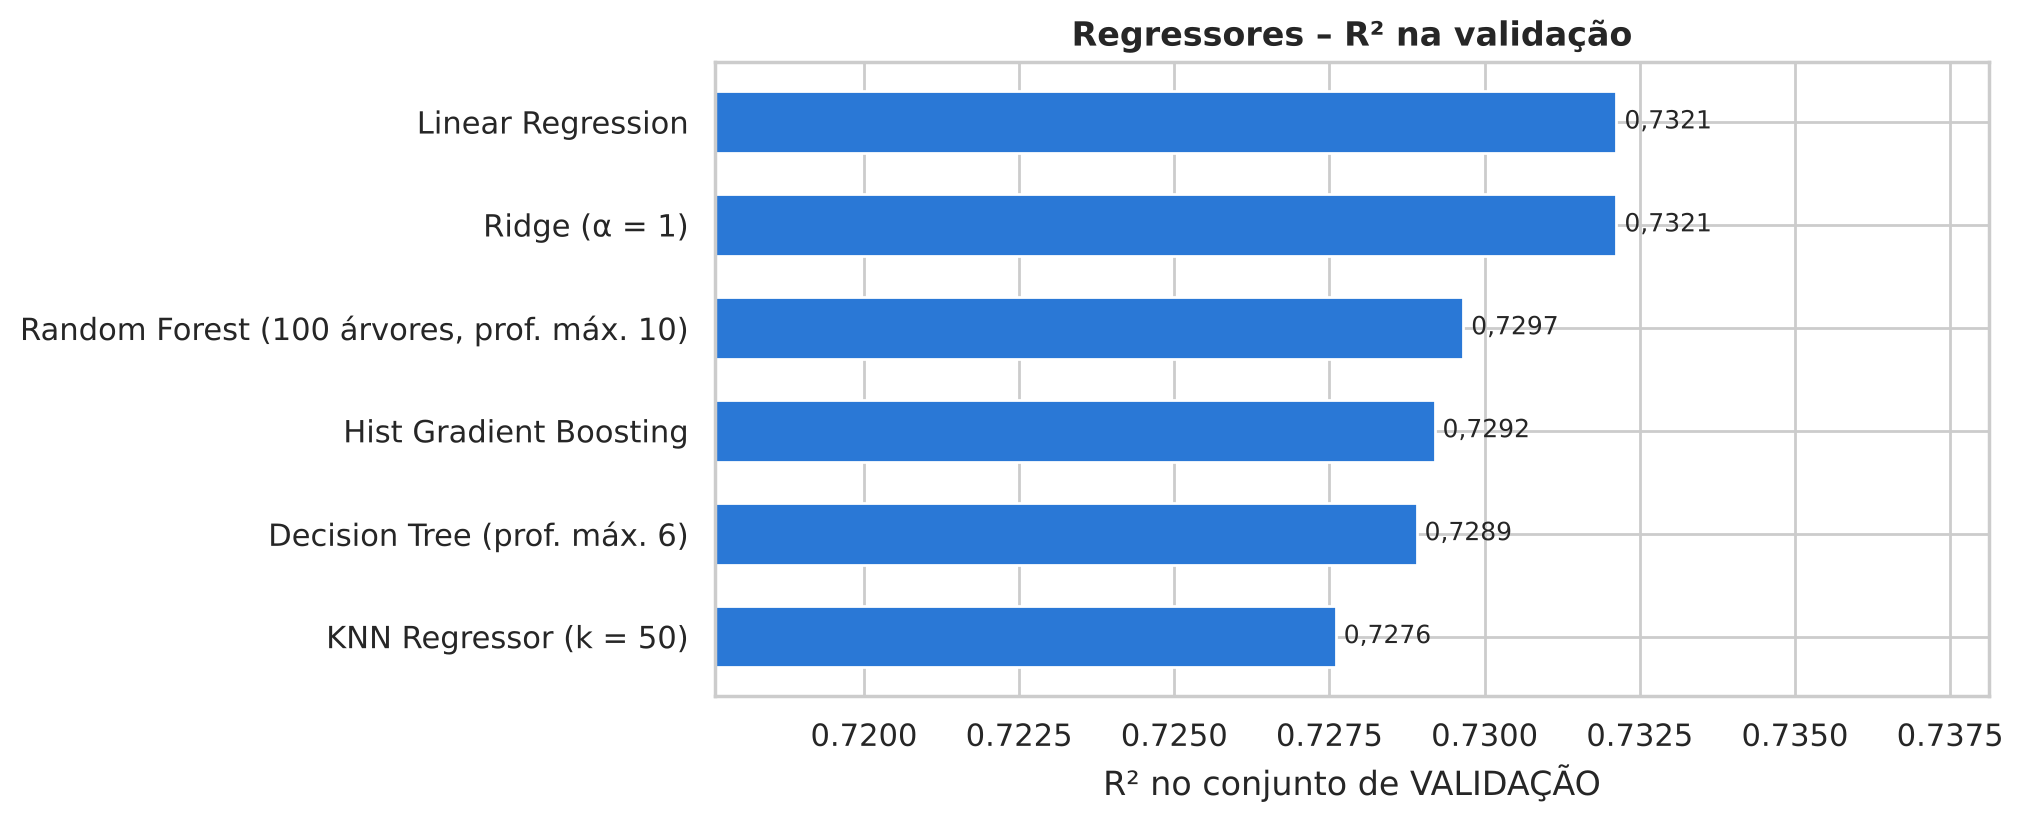

### Coeficientes do modelo (intercepto = R$ 850,31 = TOTAL médio do TRAIN)

,Coeficiente (R$ por 1 desvio-padrão),Desvio-padrão da entrada (TRAIN),Efeito de +1 unidade original (R$)
RENDA BRUTO (R$),728.1491,6642.7159,0.1096
TIPO DA CONTA (ordinal),5.4413,0.7732,7.0373
NOTA DE SATISFAÇÃO (%),-4.9084,1.3737,-3.5731


**Modelo escolhido: Linear Regression** – maior R² na validação (0,7321). A diferença para o 2º colocado (Ridge (α = 1)) é de apenas 0,0000; todos os regressores ficam entre 0,7276 e 0,7321. Modelos mais complexos (árvores e ensembles) não superam o modelo linear na validação: o ganho deles no TRAIN não se repete em dados novos, o que indica que a relação entre as entradas e o TOTAL é essencialmente linear. O efeito dominante é o da RENDA: cada R$ 1.000 a mais de renda bruta eleva o TOTAL estimado em R$ 109,62, mantidas as demais entradas.

In [ ]:
# =====================================================================
# A1.3 – CRIAR OS MODELOS: REGRESSORS
# Comparação de 6 regressores (famílias do link "Supervised learning" do
# scikit-learn):
# lineares (1.1), vizinhos (1.6), árvore (1.10) e ensembles (1.11).
# Critério de escolha: maior R² no conjunto de VALIDAÇÃO (o conjunto de
# validação
# existe justamente para escolher o modelo; o TEST fica intocado até o fim).
# =====================================================================
REGRESSORES = {
    "Linear Regression": LinearRegression(),
    "Ridge (α = 1)": Ridge(alpha=1.0),
    "KNN Regressor (k = 50)": KNeighborsRegressor(n_neighbors=50),
    "Decision Tree (prof. máx. 6)": DecisionTreeRegressor(
        max_depth=6, random_state=SEED
    ),
    "Random Forest (100 árvores, prof. máx. 10)": RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        n_jobs=-1,
        random_state=SEED,
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        random_state=SEED
    ),
}
kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
linhas = []
for nome, modelo in REGRESSORES.items():
    t0 = time.time()
    cv = cross_val_score(
        clone(modelo),
        X_train_reg,
        y_train_reg,
        cv=kf,
        scoring="r2",
        n_jobs=-1,
    )
    m = clone(modelo).fit(X_train_reg, y_train_reg)
    linhas.append({
        "Regressor": nome,
        "R² CV TRAIN (média)": cv.mean(),
        "R² CV TRAIN (desvio)": cv.std(ddof=1),
        "R² TRAIN": m.score(X_train_reg, y_train_reg),
        "R² VALIDATION": m.score(X_val_reg, y_val_reg),
        "Tempo (s)": time.time() - t0,
    })
comp_reg = (
    pd.DataFrame(linhas)
    .set_index("Regressor")
    .sort_values("R² VALIDATION", ascending=False)
)
checar_finitos(comp_reg, "comparação de regressores")
display(Markdown("### Comparação dos regressores"))
display(comp_reg.round(4))

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ordem = comp_reg.index[::-1]
ax.barh(
    ordem, comp_reg.loc[ordem, "R² VALIDATION"], color="#2a78d6", height=0.6
)
for i, v in enumerate(comp_reg.loc[ordem, "R² VALIDATION"]):
    ax.text(v, i, f" {br(v, 4)}", va="center", fontsize=9)
ax.set_xlim(
    comp_reg["R² VALIDATION"].min() - 0.01,
    comp_reg["R² VALIDATION"].max() + 0.006,
)
ax.set_xlabel("R² no conjunto de VALIDAÇÃO")
ax.set_title("Regressores – R² na validação", fontweight="bold")
plt.show()

NOME_REG = comp_reg.index[0]
MODELO_REG = clone(REGRESSORES[NOME_REG]).fit(X_train_reg, y_train_reg)
RESULTADOS["A1_comparacao"] = comp_reg
RESULTADOS["A1_modelo"] = NOME_REG

dif_2 = (
    comp_reg.iloc[0]["R² VALIDATION"] - comp_reg.iloc[1]["R² VALIDATION"]
)
texto = (
    f"**Modelo escolhido: {NOME_REG}** – maior R² na validação"
    f" ({br(comp_reg.iloc[0]['R² VALIDATION'], 4)}). A diferença para o 2º"
    f" colocado ({comp_reg.index[1]}) é de apenas {br(dif_2, 4)}; todos os"
    f" regressores ficam entre {br(comp_reg['R² VALIDATION'].min(), 4)} e"
    f" {br(comp_reg['R² VALIDATION'].max(), 4)}. "
    + (
        "Modelos mais complexos (árvores e ensembles) não superam o modelo"
        " linear na validação: o ganho deles no TRAIN não se repete em"
        " dados novos, o que indica que a relação entre as entradas e o"
        " TOTAL é essencialmente linear."
        if NOME_REG.startswith(("Linear", "Ridge"))
        else (
            "O modelo vencedor é não linear; o ganho sobre o modelo linear"
            " deve ser pesado contra a perda de interpretabilidade."
        )
    )
)
if hasattr(MODELO_REG, "coef_"):
    escala = pd.Series(scaler_reg.scale_, index=CANDIDATAS_REG)[COLS_REG]
    coefs = pd.DataFrame(
        {
            "Coeficiente (R$ por 1 desvio-padrão)": MODELO_REG.coef_,
            "Desvio-padrão da entrada (TRAIN)": escala.values,
            "Efeito de +1 unidade original (R$)": (
                MODELO_REG.coef_ / escala.values
            ),
        },
        index=COLS_REG,
    )
    display(
        Markdown(
            "### Coeficientes do modelo (intercepto = R$"
            f" {br(MODELO_REG.intercept_, 2)} = TOTAL médio do TRAIN)"
        )
    )
    display(coefs.round(4))
    texto += (
        " O efeito dominante é o da RENDA: cada R$ 1.000 a mais de renda"
        " bruta eleva o TOTAL estimado em R$"
        f" {br(coefs.iloc[0, 2] * 1000, 2)}, mantidas as demais entradas."
    )
display(Markdown(texto))

### A1.3.1: Intervalo de confiança: Train

Fold,1,2,3,4,5,6,7,8,9,10
R²,0.751,0.7392,0.7244,0.7427,0.7259,0.7438,0.7215,0.7207,0.734,0.735


,R²,IC95% inf,IC95% sup,EP
Procedimento,,,,
Validação cruzada (10 folds) – média bootstrap,0.7338,0.7276,0.7398,0.0032
Bootstrap das linhas do TRAIN,0.7339,0.7289,0.7387,0.0025


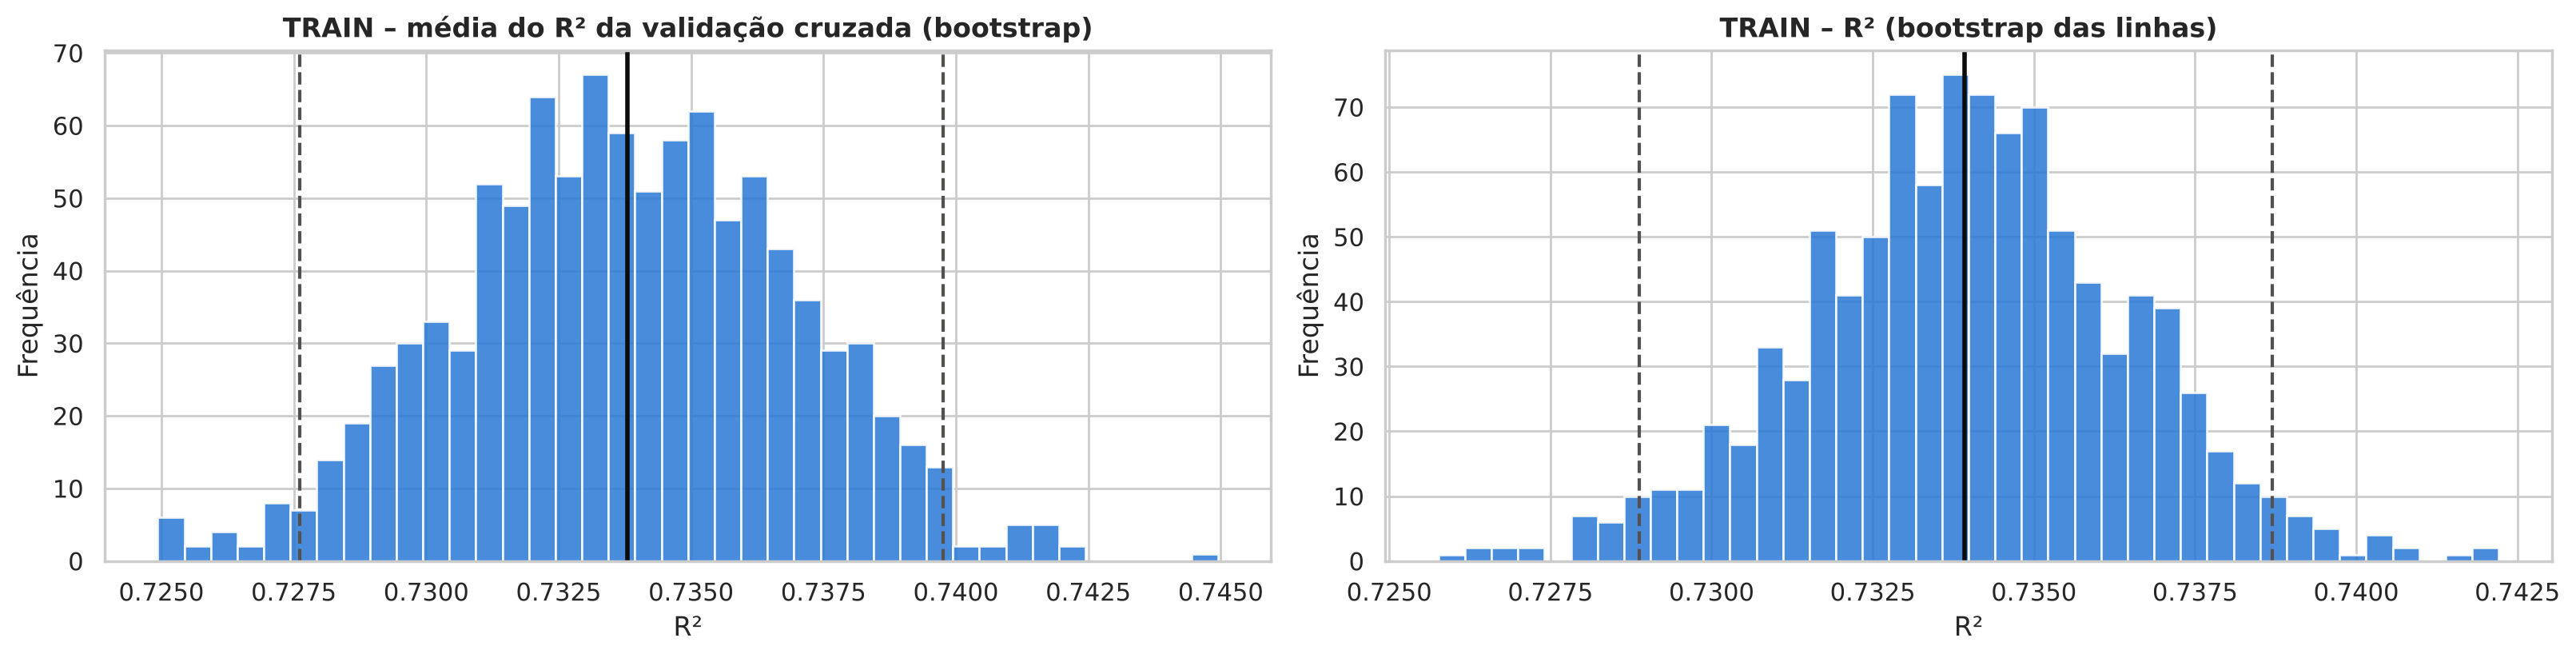

**IC 95% do R² no TRAIN:** validação cruzada 0,7338 [0,7276; 0,7398] e bootstrap 0,7339 [0,7289; 0,7387]. Os 10 folds variam de 0,7207 a 0,7510: o desempenho é estável entre partições.

In [ ]:
# Validação Cruzada e Análise Bootstrapping
# (a) Validação cruzada K = 10 no TRAIN (o modelo é reajustado em cada fold)
cv_train = cross_val_score(
    clone(REGRESSORES[NOME_REG]),
    X_train_reg,
    y_train_reg,
    cv=kf,
    scoring="r2",
)
boot_cv_train = bootstrap_media(cv_train)
# (b) Bootstrap do R² do modelo final nas linhas do TRAIN
boot_r2_train = bootstrap_metrica(
    y_train_reg, MODELO_REG.predict(X_train_reg), r2_score
)

display(
    pd.DataFrame({"Fold": range(1, K_FOLDS + 1), "R²": cv_train})
    .set_index("Fold")
    .T.round(4)
)
ic_train = pd.DataFrame([
    {
        "Procedimento": "Validação cruzada (10 folds) – média bootstrap",
        "R²": boot_cv_train["estimativa"],
        "IC95% inf": boot_cv_train["ic_inf"],
        "IC95% sup": boot_cv_train["ic_sup"],
        "EP": boot_cv_train["ep"],
    },
    {
        "Procedimento": "Bootstrap das linhas do TRAIN",
        "R²": boot_r2_train["estimativa"],
        "IC95% inf": boot_r2_train["ic_inf"],
        "IC95% sup": boot_r2_train["ic_sup"],
        "EP": boot_r2_train["ep"],
    },
]).set_index("Procedimento")
checar_finitos(ic_train, "IC train")
display(ic_train.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4), layout="constrained")
plot_bootstrap(
    boot_cv_train,
    "TRAIN – média do R² da validação cruzada (bootstrap)",
    "R²",
    ax=axes[0],
)
plot_bootstrap(
    boot_r2_train, "TRAIN – R² (bootstrap das linhas)", "R²", ax=axes[1]
)
plt.show()

RESULTADOS["A1_ic_train"] = ic_train
display(
    Markdown(
        "**IC 95% do R² no TRAIN:** validação cruzada"
        f" {br(boot_cv_train['estimativa'], 4)}"
        f" [{br(boot_cv_train['ic_inf'], 4)};"
        f" {br(boot_cv_train['ic_sup'], 4)}] e bootstrap"
        f" {br(boot_r2_train['estimativa'], 4)}"
        f" [{br(boot_r2_train['ic_inf'], 4)};"
        f" {br(boot_r2_train['ic_sup'], 4)}]. Os 10 folds variam de"
        f" {br(cv_train.min(), 4)} a {br(cv_train.max(), 4)}: o desempenho"
        " é estável entre partições."
    )
)

### A1.3.2: Intervalo de confiança: Validation

Partição,1,2,3,4,5,6,7,8,9,10
R²,0.7244,0.7226,0.7279,0.7427,0.7286,0.7403,0.7341,0.7311,0.735,0.7332


,R²,IC95% inf,IC95% sup,EP
Procedimento,,,,
10 partições do VALIDATION – média bootstrap,0.7320,0.7281,0.7358,0.0020
Bootstrap das linhas do VALIDATION,0.7321,0.7273,0.7371,0.0025


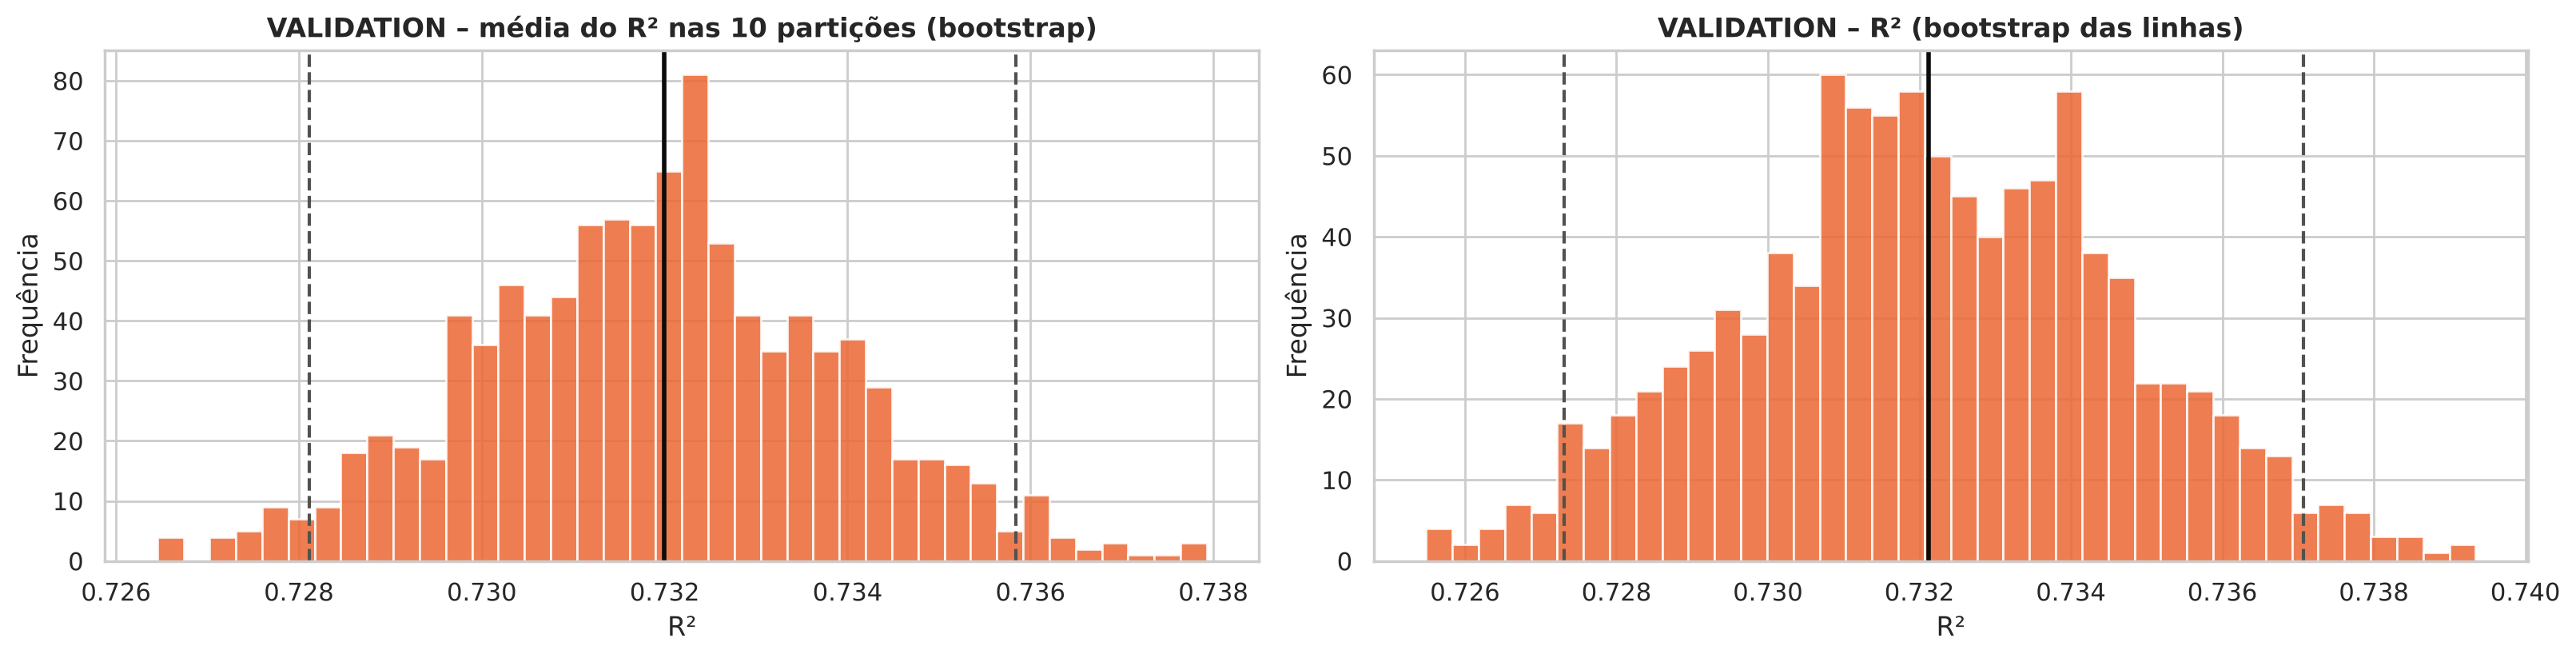

**IC 95% do R² no VALIDATION:** 0,7321 [0,7273; 0,7371]. Os intervalos do TRAIN e do VALIDATION **se sobrepõem**: não há sinal de sobreajuste (*overfitting*).

In [ ]:
# Validação Cruzada e Análise Bootstrapping
# Modelo FIXO (ajustado no TRAIN) avaliado no VALIDATION:
# (a) "validação cruzada" do conjunto: R² em 10 partições disjuntas do
# VALIDATION
cv_val = np.array([
    r2_score(y_val_reg[i], MODELO_REG.predict(X_val_reg[i]))
    for _, i in kf.split(X_val_reg)
])
boot_cv_val = bootstrap_media(cv_val)
# (b) Bootstrap do R² nas linhas do VALIDATION
boot_r2_val = bootstrap_metrica(
    y_val_reg, MODELO_REG.predict(X_val_reg), r2_score
)

display(
    pd.DataFrame({"Partição": range(1, K_FOLDS + 1), "R²": cv_val})
    .set_index("Partição")
    .T.round(4)
)
ic_val = pd.DataFrame([
    {
        "Procedimento": "10 partições do VALIDATION – média bootstrap",
        "R²": boot_cv_val["estimativa"],
        "IC95% inf": boot_cv_val["ic_inf"],
        "IC95% sup": boot_cv_val["ic_sup"],
        "EP": boot_cv_val["ep"],
    },
    {
        "Procedimento": "Bootstrap das linhas do VALIDATION",
        "R²": boot_r2_val["estimativa"],
        "IC95% inf": boot_r2_val["ic_inf"],
        "IC95% sup": boot_r2_val["ic_sup"],
        "EP": boot_r2_val["ep"],
    },
]).set_index("Procedimento")
checar_finitos(ic_val, "IC validation")
display(ic_val.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 4), layout="constrained")
plot_bootstrap(
    boot_cv_val,
    "VALIDATION – média do R² nas 10 partições (bootstrap)",
    "R²",
    cor="#eb6834",
    ax=axes[0],
)
plot_bootstrap(
    boot_r2_val,
    "VALIDATION – R² (bootstrap das linhas)",
    "R²",
    cor="#eb6834",
    ax=axes[1],
)
plt.show()

sobrepoe = (boot_r2_val["ic_inf"] <= boot_r2_train["ic_sup"]) and (
    boot_r2_train["ic_inf"] <= boot_r2_val["ic_sup"]
)
RESULTADOS["A1_ic_val"] = ic_val
display(
    Markdown(
        "**IC 95% do R² no VALIDATION:**"
        f" {br(boot_r2_val['estimativa'], 4)}"
        f" [{br(boot_r2_val['ic_inf'], 4)};"
        f" {br(boot_r2_val['ic_sup'], 4)}]. "
        + (
            "Os intervalos do TRAIN e do VALIDATION **se sobrepõem**: não"
            " há sinal de sobreajuste (*overfitting*)."
            if sobrepoe
            else (
                "Os intervalos do TRAIN e do VALIDATION **não se"
                " sobrepõem**: o desempenho cai em dados novos (atenção a"
                " sobreajuste)."
            )
        )
    )
)

##Atividade A1.4 (4º Passo): Medir a acurácia (score) dos Modelos de Regressão:

### A1.4.1: Exibir os Coeficientes de Determinação ($R^2$)

* Conjunto de Treinamento: R² do modelo nos dados usados para ajustá-lo (desempenho "dentro da amostra").

* Conjunto de Validação: R² em dados que o modelo não viu no ajuste; foi o conjunto usado para escolher o regressor (A1.3).

* Conjunto de Teste: R² em dados intocados até aqui; é a estimativa honesta do desempenho em produção.

O R² indica a fração da variância do TOTAL (R$) explicada pelo modelo (1 = perfeito; 0 = o mesmo que prever sempre a média). Também são mostrados o MAE (erro absoluto médio, em R$) e o RMSE (raiz do erro quadrático médio, em R$). Os valores estão nas saídas das três células abaixo.

In [ ]:
# Train
def metricas_reg(y, y_hat, nome):
    return pd.Series(
        {
            "R²": r2_score(y, y_hat),
            "MAE (R$)": mean_absolute_error(y, y_hat),
            "RMSE (R$)": np.sqrt(mean_squared_error(y, y_hat)),
            "n": len(y),
        },
        name=nome,
    )


yhat_train_reg = MODELO_REG.predict(X_train_reg)
met_train_reg = metricas_reg(y_train_reg, yhat_train_reg, "TRAIN")
display(met_train_reg.to_frame().T.round(4))
print(
    "Coeficiente de Determinação (R²) – TRAIN:"
    f" {br(met_train_reg['R²'], 4)}"
)

,R²,MAE (R$),RMSE (R$),n
TRAIN,0.7339,288.0865,439.7562,50300.0


Coeficiente de Determinação (R²) – TRAIN: 0,7339


In [ ]:
# Validation
yhat_val_reg = MODELO_REG.predict(X_val_reg)
met_val_reg = metricas_reg(y_val_reg, yhat_val_reg, "VALIDATION")
display(met_val_reg.to_frame().T.round(4))
print(
    "Coeficiente de Determinação (R²) – VALIDATION:"
    f" {br(met_val_reg['R²'], 4)}"
)

,R²,MAE (R$),RMSE (R$),n
VALIDATION,0.7321,289.0062,441.5471,50300.0


Coeficiente de Determinação (R²) – VALIDATION: 0,7321


In [ ]:
# Teste
yhat_test_reg = MODELO_REG.predict(X_test_reg)
met_test_reg = metricas_reg(y_test_reg, yhat_test_reg, "TEST")
display(met_test_reg.to_frame().T.round(4))
print(
    f"Coeficiente de Determinação (R²) – TEST: {br(met_test_reg['R²'], 4)}"
)

met_reg = pd.concat([met_train_reg, met_val_reg, met_test_reg], axis=1).T
checar_finitos(met_reg, "métricas de regressão")
RESULTADOS["A1_metricas"] = met_reg
display(Markdown("### Resumo – TRAIN x VALIDATION x TEST"))
display(met_reg.round(4))
gap = abs(met_reg.loc["TRAIN", "R²"] - met_reg.loc["TEST", "R²"])
display(
    Markdown(
        f"**Leitura:** R² = {br(met_reg.loc['TRAIN', 'R²'], 4)} (TRAIN),"
        f" {br(met_reg.loc['VALIDATION', 'R²'], 4)} (VALIDATION) e"
        f" {br(met_reg.loc['TEST', 'R²'], 4)} (TEST): o modelo explica"
        f" cerca de {br(met_reg.loc['TEST', 'R²'] * 100, 1)}% da variação"
        " do TOTAL em dados novos, com erro absoluto médio de R$"
        f" {br(met_reg.loc['TEST', 'MAE (R$)'], 2)}. A diferença entre"
        f" TRAIN e TEST é de {br(gap, 4)} ponto de R²: o modelo generaliza."
    )
)

,R²,MAE (R$),RMSE (R$),n
TEST,0.7324,290.3092,443.1811,50300.0


Coeficiente de Determinação (R²) – TEST: 0,7324


### Resumo – TRAIN x VALIDATION x TEST

,R²,MAE (R$),RMSE (R$),n
TRAIN,0.7339,288.0865,439.7562,50300.0
VALIDATION,0.7321,289.0062,441.5471,50300.0
TEST,0.7324,290.3092,443.1811,50300.0


**Leitura:** R² = 0,7339 (TRAIN), 0,7321 (VALIDATION) e 0,7324 (TEST): o modelo explica cerca de 73,2% da variação do TOTAL em dados novos, com erro absoluto médio de R$ 290,31. A diferença entre TRAIN e TEST é de 0,0015 ponto de R²: o modelo generaliza.

### A1.4.2: Plotagem dos Conjuntos - REAL ($y$) x ESTIMADO ($\hat{y}$):

* Conjunto de Treinamento: dispersão entre o TOTAL real ($y$) e o TOTAL estimado ($\hat{y}$).

* Conjunto de Validação: mesma comparação em dados não usados no ajuste.

* Conjunto de Teste: mesma comparação nos dados reservados para a avaliação final.

Quanto mais próximos da reta $y = \hat{y}$ (tracejada) estiverem os pontos, melhor a estimativa. Para a figura ficar legível, cada painel mostra 5.000 pontos sorteados (`SEED = 42`); as métricas usam todas as 50.300 notas.

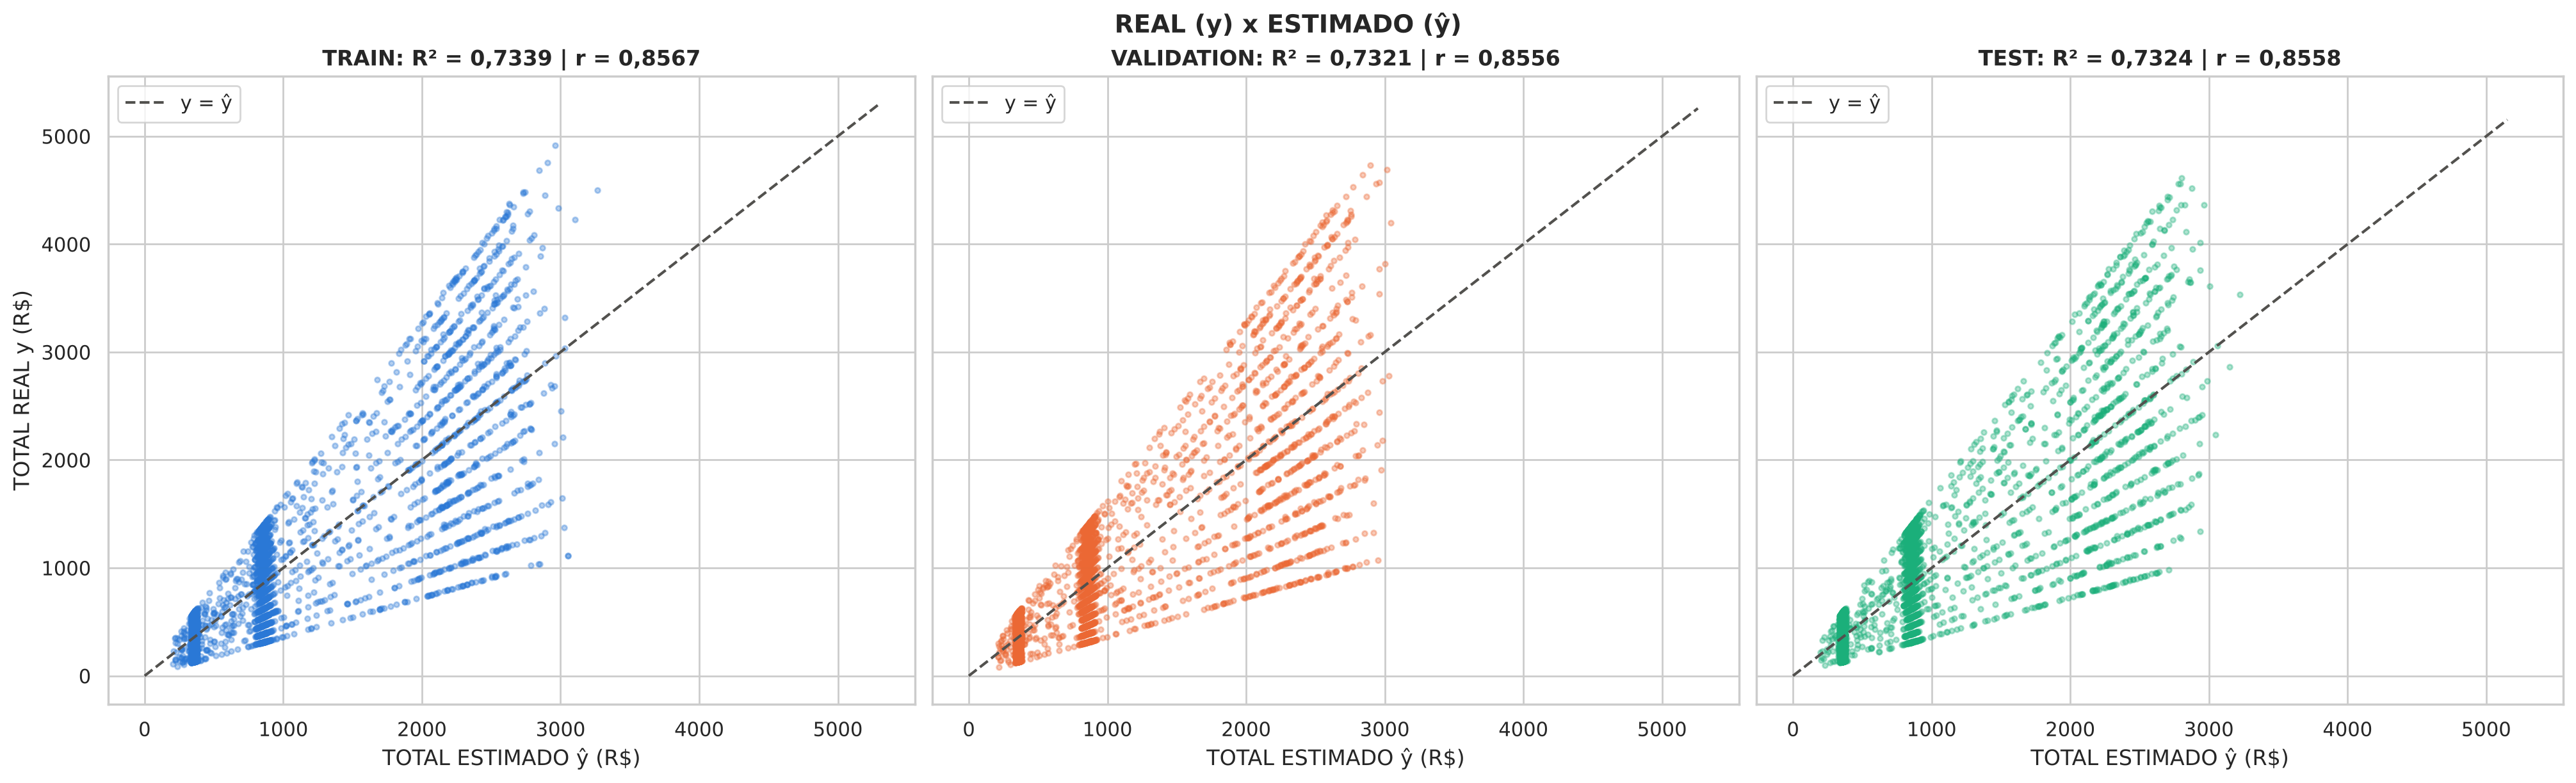

**Leitura:** os três conjuntos têm a mesma forma de nuvem: os pontos acompanham a reta y = ŷ, mas a dispersão vertical **aumenta** com o valor estimado (formato de funil). Para um mesmo valor estimado, o TOTAL real pode ser bem maior ou menor: o modelo acerta a tendência média, não o valor exato de cada nota.

In [ ]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    1, 3, figsize=(20, 6), layout="constrained", sharex=True, sharey=True
)
for ax, (nome, y, yh) in zip(
    axes,
    [
        ("TRAIN", y_train_reg, yhat_train_reg),
        ("VALIDATION", y_val_reg, yhat_val_reg),
        ("TEST", y_test_reg, yhat_test_reg),
    ],
):
    i = rng.choice(len(y), 5000, replace=False)
    ax.scatter(yh[i], y[i], s=8, alpha=0.35, color=CORES_CONJ[nome])
    lim = [0, max(y.max(), yh.max())]
    ax.plot(lim, lim, ls="--", color="#52514e", lw=1.5, label="y = ŷ")
    ax.set_title(
        f"{nome}: R² = {br(r2_score(y, yh), 4)} | r ="
        f" {br(np.corrcoef(y, yh)[0, 1], 4)}",
        fontweight="bold",
    )
    ax.set_xlabel("TOTAL ESTIMADO ŷ (R$)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("TOTAL REAL y (R$)")
fig.suptitle("REAL (y) x ESTIMADO (ŷ)", fontweight="bold", fontsize=14)
plt.show()
display(
    Markdown(
        "**Leitura:** os três conjuntos têm a mesma forma de nuvem: os"
        " pontos acompanham a reta y = ŷ, mas a dispersão vertical"
        " **aumenta** com o valor estimado (formato de funil). Para um"
        " mesmo valor estimado, o TOTAL real pode ser bem maior ou menor: o"
        " modelo acerta a tendência média, não o valor exato de cada nota."
    )
)

### A1.4.3: Análise dos Resíduos: $\epsilon = y_{real} - y_{estimado}$

* Conjunto de Treinamento: distribuição dos resíduos $\epsilon = y - \hat{y}$ no TRAIN.

* Conjunto de Validação: distribuição dos resíduos no VALIDATION.

* Conjunto de Teste: distribuição dos resíduos no TEST.

Para cada conjunto são calculados média, desvio-padrão, assimetria, curtose e o teste de normalidade de Anderson–Darling (o mesmo da Parte 1). Um bom modelo tem resíduos com média ≈ 0 (sem viés). Os valores e a decisão dos testes estão na saída da célula abaixo.

,Média (R$),Desvio-padrão (R$),Mediana (R$),Assimetria,Curtose (excesso),AD,p_value AD,Decisão (α = 5%)
Conjunto,,,,,,,,
TRAIN,0.0000,439.7606,1.8005,0.0067,3.4912,1509.3021,0.0,Rejeita-se H0
VALIDATION,-1.7521,441.5480,1.7915,0.0065,3.5079,1526.6448,0.0,Rejeita-se H0
TEST,3.9542,443.1679,1.8125,0.0240,3.4910,1508.3915,0.0,Rejeita-se H0


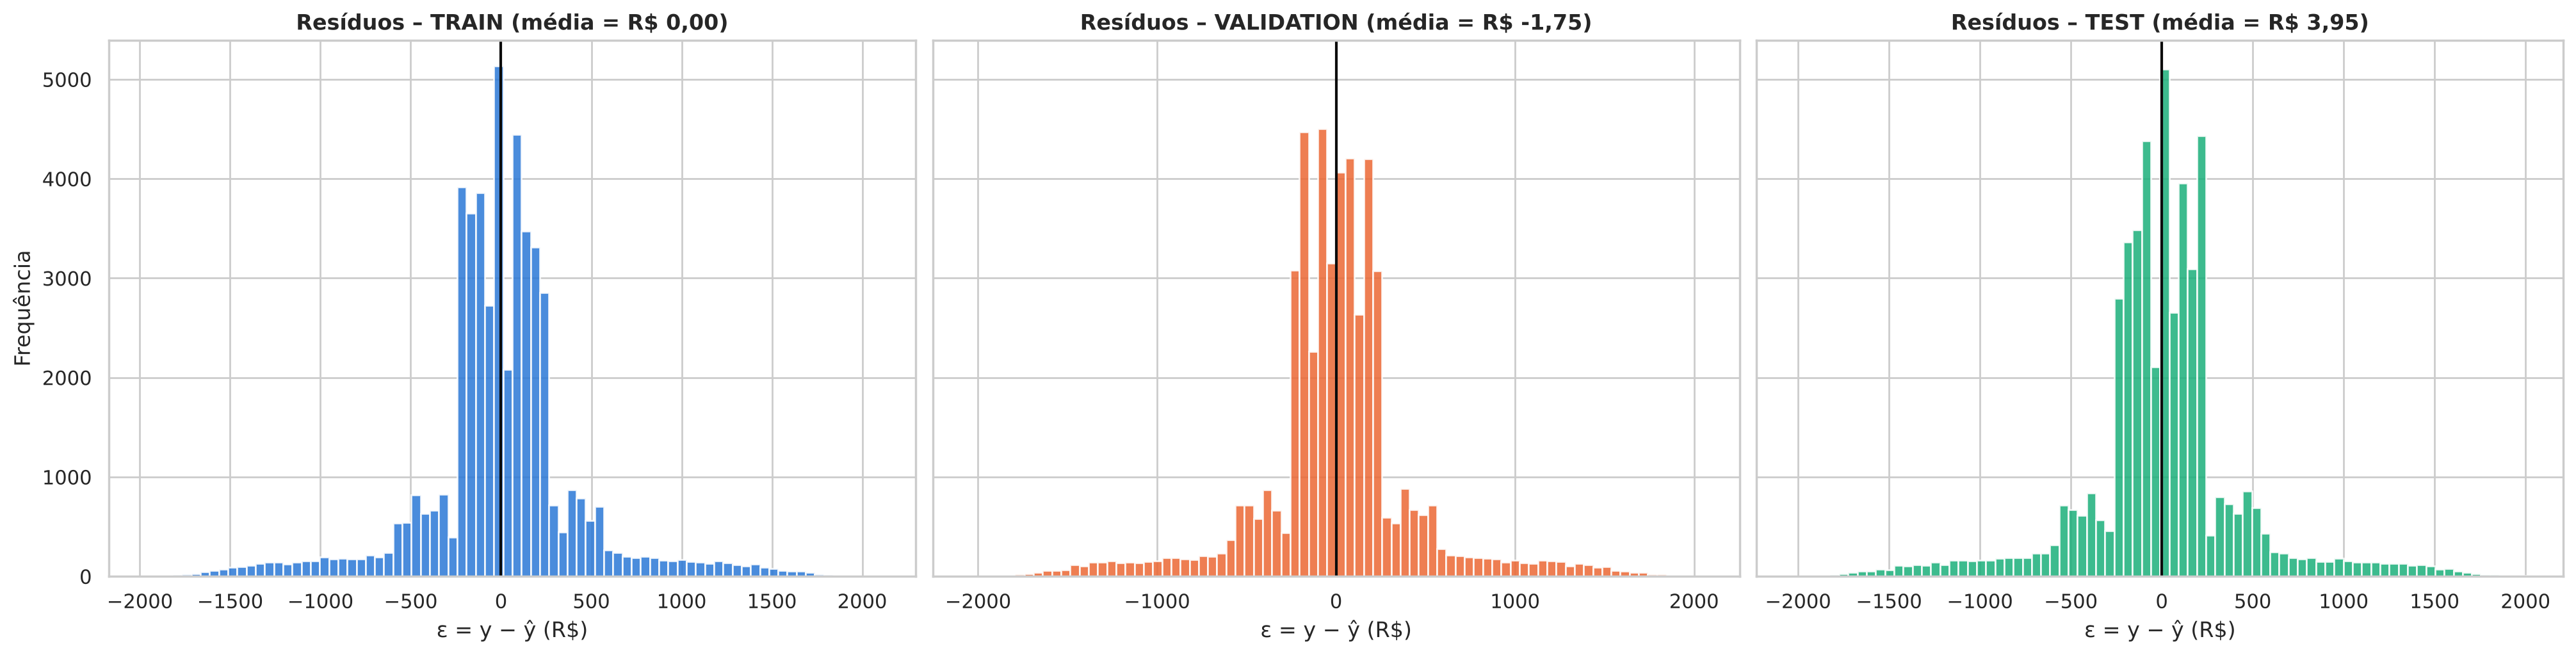

**Leitura:** a média dos resíduos é R$ 0,00 (TRAIN), R$ -1,75 (VALIDATION) e R$ 3,95 (TEST), ou seja, praticamente zero: **o modelo não tem viés sistemático**. Os resíduos são praticamente simétricos (assimetria ≤ 0,024), mas têm caudas mais pesadas que a normal (curtose em excesso ≈ 3,50); por isso o teste de Anderson–Darling **rejeita H0 de normalidade** nos três conjuntos. Isso não invalida as previsões, mas indica que intervalos de previsão baseados na normal não seriam adequados.

In [ ]:
res_train_reg = y_train_reg - yhat_train_reg
res_val_reg = y_val_reg - yhat_val_reg
res_test_reg = y_test_reg - yhat_test_reg
RESIDUOS = {
    "TRAIN": res_train_reg,
    "VALIDATION": res_val_reg,
    "TEST": res_test_reg,
}

linhas = []
for nome, e in RESIDUOS.items():
    ad, p = normal_ad(e)
    linhas.append({
        "Conjunto": nome,
        "Média (R$)": e.mean(),
        "Desvio-padrão (R$)": e.std(ddof=1),
        "Mediana (R$)": np.median(e),
        "Assimetria": stats.skew(e),
        "Curtose (excesso)": stats.kurtosis(e),
        "AD": ad,
        "p_value AD": p,
        "Decisão (α = 5%)": decisao(p),
    })
resumo_res = pd.DataFrame(linhas).set_index("Conjunto")
checar_finitos(resumo_res, "resíduos")
display(resumo_res.round(4))

fig, axes = plt.subplots(
    1, 3, figsize=(20, 5), layout="constrained", sharey=True
)
for ax, (nome, e) in zip(axes, RESIDUOS.items()):
    ax.hist(
        e, bins=80, color=CORES_CONJ[nome], alpha=0.85, edgecolor="white"
    )
    ax.axvline(0, color="#0b0b0b", lw=1.5)
    ax.set_title(
        f"Resíduos – {nome} (média = R$ {br(e.mean(), 2)})",
        fontweight="bold",
    )
    ax.set_xlabel("ε = y − ŷ (R$)")
axes[0].set_ylabel("Frequência")
plt.show()

RESULTADOS["A1_residuos"] = resumo_res
todos_rejeitam = bool((resumo_res["p_value AD"] <= ALPHA).all())
display(
    Markdown(
        "**Leitura:** a média dos resíduos é R$"
        f" {br(resumo_res.loc['TRAIN', 'Média (R$)'], 2)} (TRAIN), R$"
        f" {br(resumo_res.loc['VALIDATION', 'Média (R$)'], 2)} (VALIDATION)"
        f" e R$ {br(resumo_res.loc['TEST', 'Média (R$)'], 2)} (TEST), ou"
        " seja, praticamente zero: **o modelo não tem viés sistemático**. "
        + (
            "Os resíduos são praticamente simétricos (assimetria ≤"
            f" {br(resumo_res['Assimetria'].abs().max(), 3)}), mas têm"
            " caudas mais pesadas que a normal (curtose em excesso ≈"
            f" {br(resumo_res['Curtose (excesso)'].mean(), 2)}); por isso o"
            " teste de Anderson–Darling **rejeita H0 de normalidade** nos"
            " três conjuntos. Isso não invalida as previsões, mas indica"
            " que intervalos de previsão baseados na normal não seriam"
            " adequados."
            if todos_rejeitam
            else (
                "O teste de Anderson–Darling não rejeitou H0 de normalidade"
                " em pelo menos um conjunto (ver tabela)."
            )
        )
    )
)

### A1.4.4: JOINT: Resíduos ($\epsilon$) vs Valores Estimado ($\hat{y}$)

* Conjunto de Treinamento: gráfico conjunto (JOINT) dos resíduos $\epsilon$ contra os valores estimados $\hat{y}$, com as distribuições marginais.

* Conjunto de Validação: mesmo gráfico em dados não usados no ajuste.

* Conjunto de Teste: mesmo gráfico nos dados da avaliação final.

Num modelo bem especificado, os resíduos formam uma faixa horizontal de largura constante em torno de zero (homocedasticidade). Para medir isso é aplicado o teste de Breusch–Pagan (H0: variância dos resíduos constante). Os resultados estão na saída da célula abaixo.

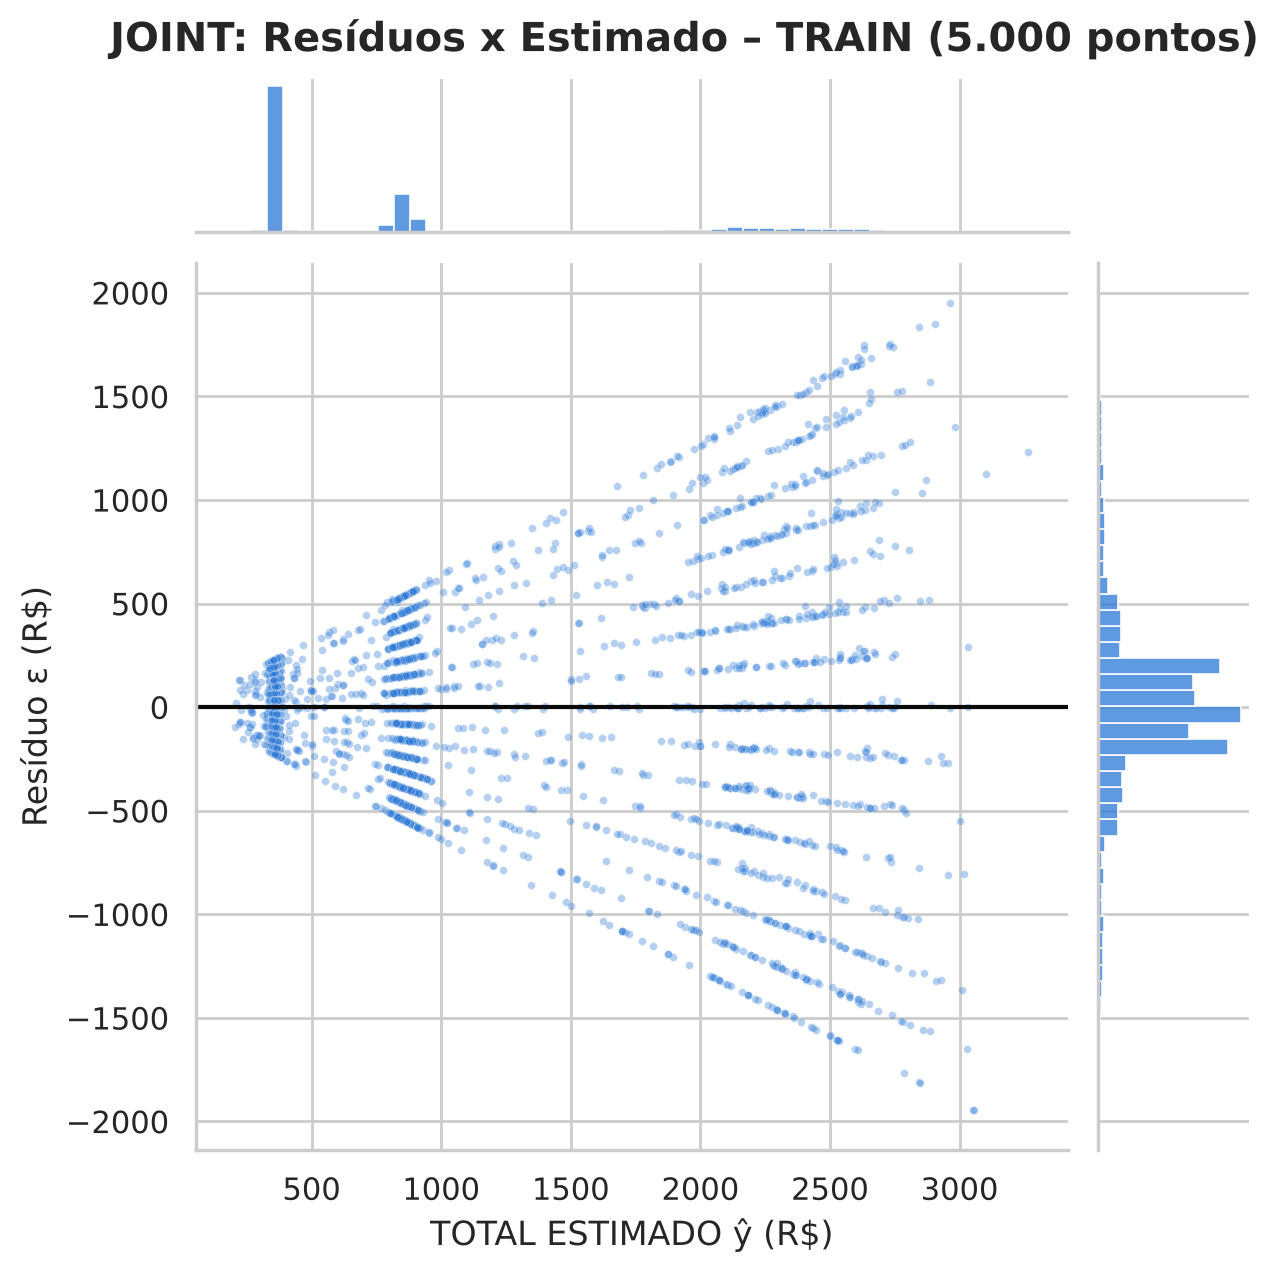

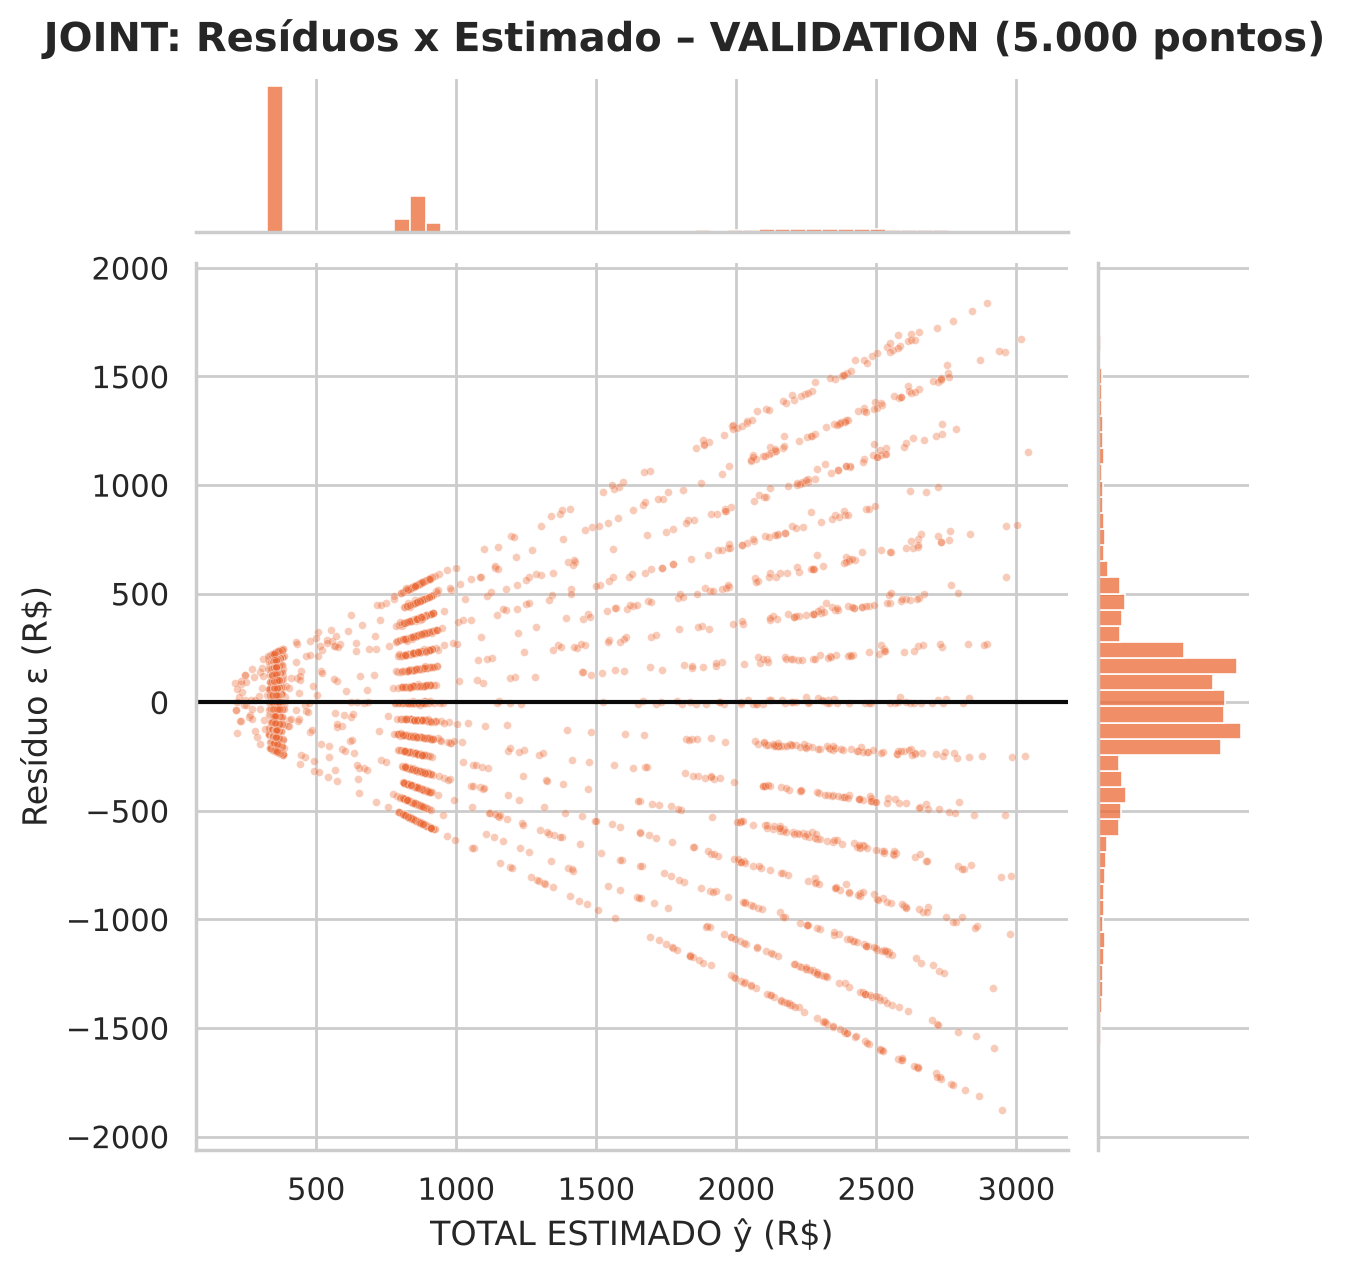

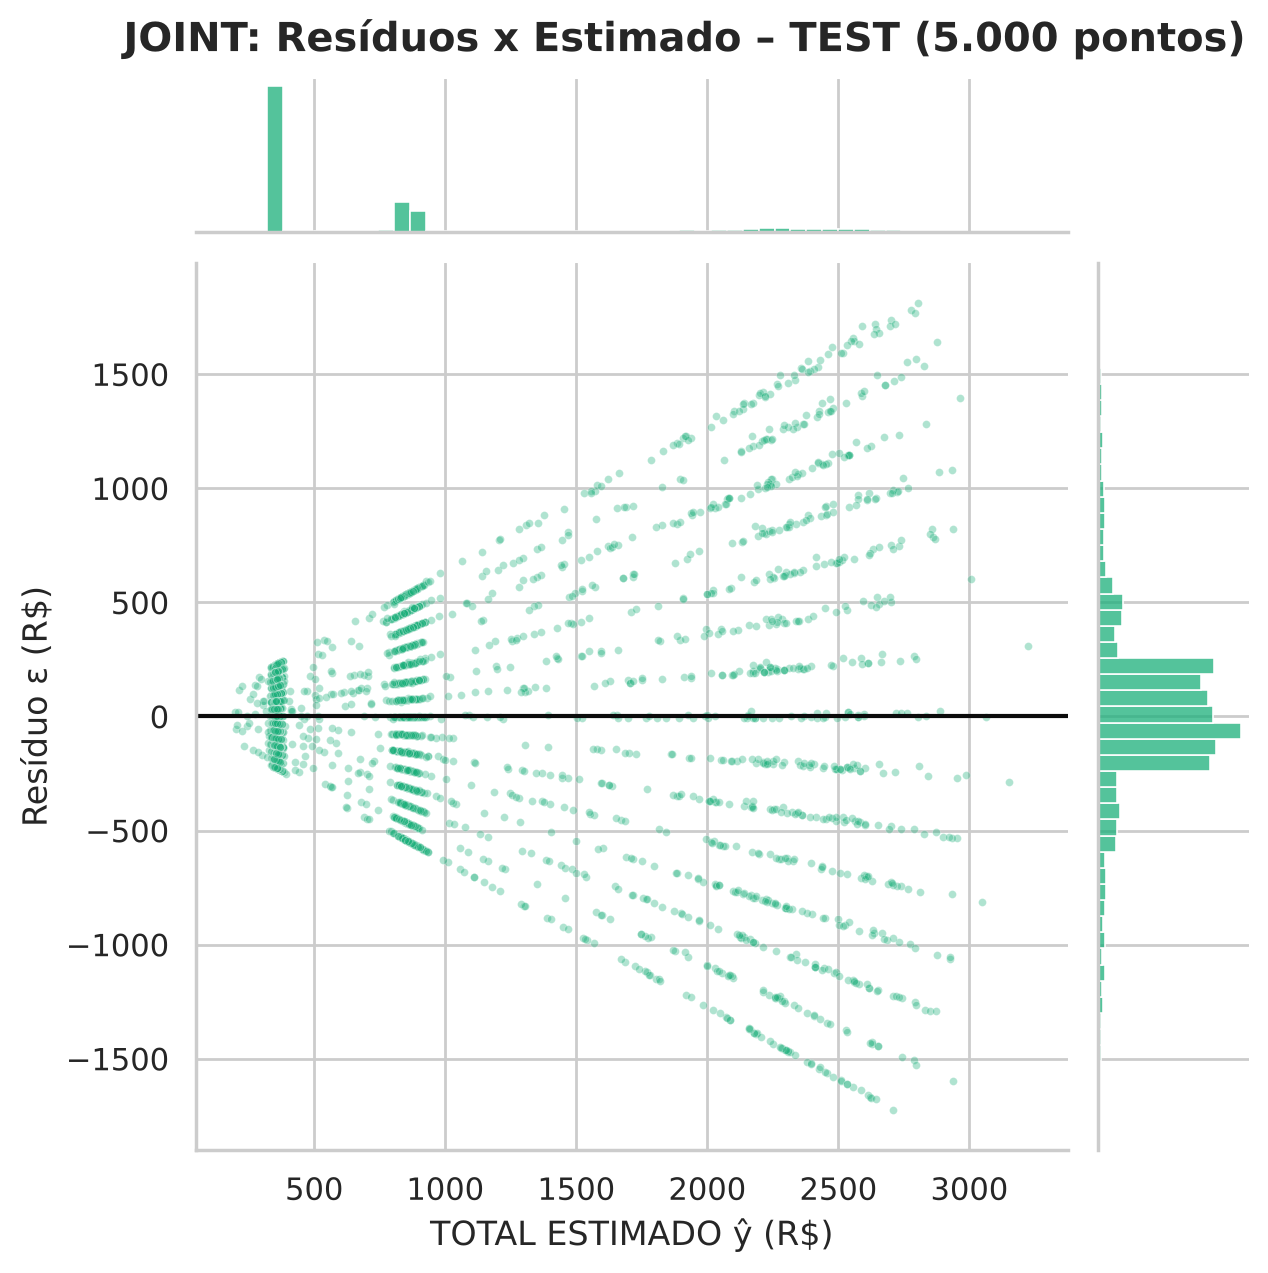

,Breusch–Pagan (LM),p_value,Decisão (α = 5%),ρ Spearman (ŷ x |ε|)
Conjunto,,,,
TRAIN,23039.8992,0.0,Rejeita-se H0,0.5985
VALIDATION,22859.0733,0.0,Rejeita-se H0,0.6027
TEST,23087.0878,0.0,Rejeita-se H0,0.6062


**Leitura:** o tamanho do erro cresce com o valor estimado (ρ de Spearman entre ŷ e |ε| = 0,6062 no TEST) e o teste de Breusch–Pagan **rejeita H0 de variância constante** nos três conjuntos: há **heterocedasticidade**. Na prática, o modelo é mais preciso, em reais, para clientes de gasto menor e menos preciso para os de gasto maior (PRIME). Isso combina com a Parte 1: o TOTAL é assimétrico à direita e o desvio-padrão cresce de ESSENTIAL para VIP e PRIME.

In [ ]:
rng = np.random.default_rng(SEED)
linhas = []
for nome, yh, e in [
    ("TRAIN", yhat_train_reg, res_train_reg),
    ("VALIDATION", yhat_val_reg, res_val_reg),
    ("TEST", yhat_test_reg, res_test_reg),
]:
    i = rng.choice(len(e), 5000, replace=False)
    g = sns.jointplot(
        x=yh[i],
        y=e[i],
        kind="scatter",
        height=6,
        color=CORES_CONJ[nome],
        joint_kws={"s": 8, "alpha": 0.35},
        marginal_kws={"bins": 50},
    )
    g.ax_joint.axhline(0, color="#0b0b0b", lw=1.5)
    g.set_axis_labels("TOTAL ESTIMADO ŷ (R$)", "Resíduo ε (R$)")
    g.figure.suptitle(
        f"JOINT: Resíduos x Estimado – {nome} (5.000 pontos)",
        fontweight="bold",
        y=1.02,
    )
    plt.show()
    bp = het_breuschpagan(e, sm.add_constant(yh))
    rho = stats.spearmanr(yh, np.abs(e)).statistic
    linhas.append({
        "Conjunto": nome,
        "Breusch–Pagan (LM)": bp[0],
        "p_value": bp[1],
        "Decisão (α = 5%)": decisao(bp[1]),
        "ρ Spearman (ŷ x |ε|)": rho,
    })
het = pd.DataFrame(linhas).set_index("Conjunto")
checar_finitos(het, "heterocedasticidade")
RESULTADOS["A1_het"] = het
display(het.round(4))
display(
    Markdown(
        "**Leitura:** o tamanho do erro cresce com o valor estimado (ρ de"
        " Spearman entre ŷ e |ε| ="
        f" {br(het.loc['TEST', 'ρ Spearman (ŷ x |ε|)'], 4)} no TEST) e o"
        " teste de Breusch–Pagan "
        + (
            "**rejeita H0 de variância constante** nos três conjuntos: há"
            " **heterocedasticidade**. "
            if (het["p_value"] <= ALPHA).all()
            else "apresenta as decisões da tabela. "
        )
        + "Na prática, o modelo é mais preciso, em reais, para clientes de"
        " gasto menor e menos preciso para os de gasto maior (PRIME)."
        " Isso combina com a Parte 1: o TOTAL é assimétrico à direita e o"
        " desvio-padrão cresce de ESSENTIAL para VIP e PRIME."
    )
)

##Atividade A1.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

### Desempenho do REGRESSOR na amostra da população

,R²,IC95% inf,IC95% sup,MAE (R$),RMSE (R$),TOTAL médio real (R$),TOTAL médio estimado (R$)
TEST,0.7324,0.7273,0.7371,290.3092,443.1811,854.8477,850.8935
SAMPLE (população),0.7338,0.7291,0.7387,288.5912,439.6209,850.6329,848.5660


### TOTAL médio real x estimado por TIPO DA CONTA (SAMPLE)

,Real (R$),Estimado (R$),Erro relativo (%)
ESSENTIAL,424.76,423.52,-0.29
VIP,936.69,935.00,-0.18
PRIME,2108.65,2103.40,-0.25


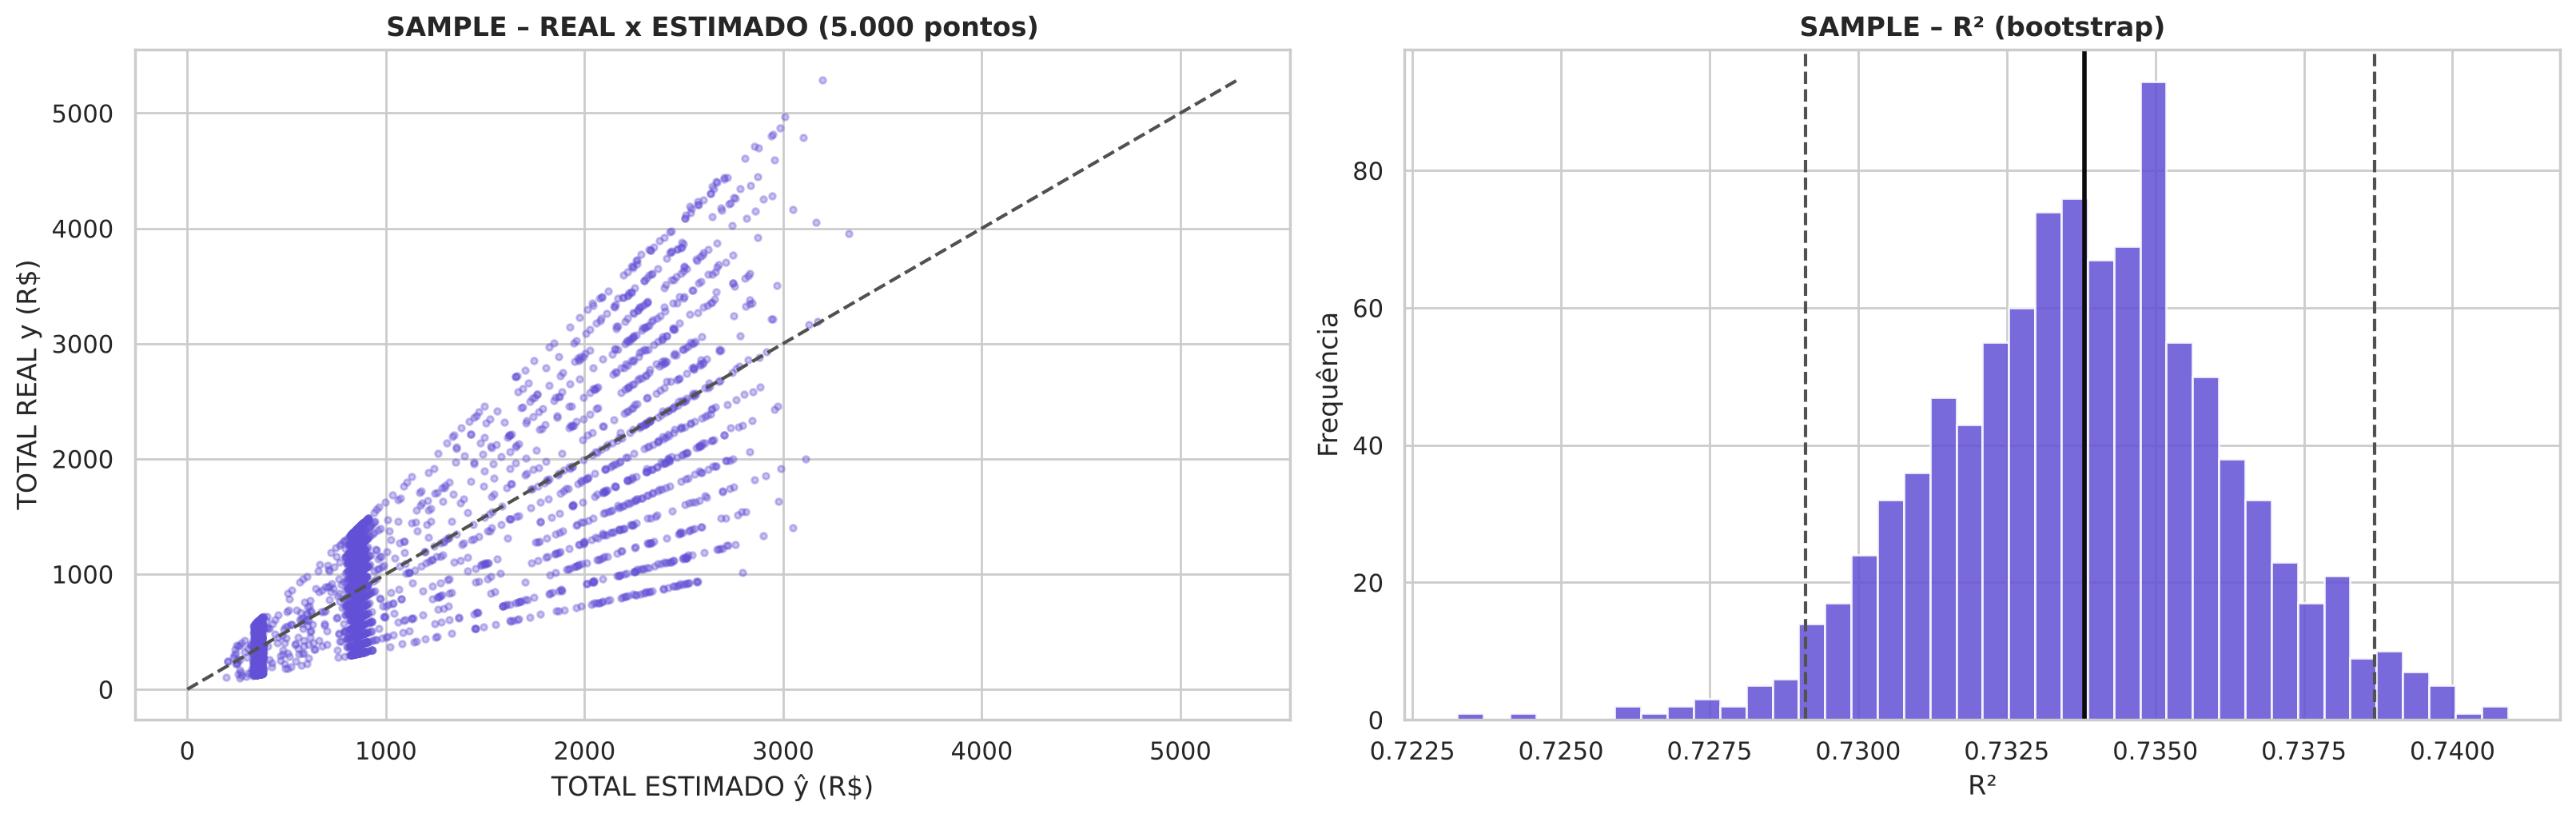

**Conclusão A1.5:** em 50.300 notas fiscais novas da população, o Linear Regression obteve R² = 0,7338 (IC 95%: 0,7291 a 0,7387) e MAE = R$ 288,59. O R² do TEST está dentro desse intervalo: o desempenho se mantém na população. O TOTAL médio estimado (R$ 848,57) fica próximo do real (R$ 850,63), e o erro relativo por tipo de conta vai de -0,29% a -0,18%.

In [ ]:
# =====================================================================
# A1.5 – TESTAR O MODELO NA POPULAÇÃO: SAMPLE (AAS de notas nunca vistas)
# =====================================================================
yhat_sample_reg = MODELO_REG.predict(X_sample_reg)
met_sample_reg = metricas_reg(y_sample_reg, yhat_sample_reg, "SAMPLE")
boot_r2_sample = bootstrap_metrica(y_sample_reg, yhat_sample_reg, r2_score)
boot_r2_test = bootstrap_metrica(y_test_reg, yhat_test_reg, r2_score)

comp = pd.DataFrame(
    {
        "R²": [boot_r2_test["estimativa"], boot_r2_sample["estimativa"]],
        "IC95% inf": [boot_r2_test["ic_inf"], boot_r2_sample["ic_inf"]],
        "IC95% sup": [boot_r2_test["ic_sup"], boot_r2_sample["ic_sup"]],
        "MAE (R$)": [met_test_reg["MAE (R$)"], met_sample_reg["MAE (R$)"]],
        "RMSE (R$)": [
            met_test_reg["RMSE (R$)"],
            met_sample_reg["RMSE (R$)"],
        ],
        "TOTAL médio real (R$)": [y_test_reg.mean(), y_sample_reg.mean()],
        "TOTAL médio estimado (R$)": [
            yhat_test_reg.mean(),
            yhat_sample_reg.mean(),
        ],
    },
    index=["TEST", "SAMPLE (população)"],
)

# TOTAL médio real x estimado por TIPO DA CONTA na SAMPLE
por_tipo = pd.DataFrame({
    "Real (R$)": (
        pd.Series(y_sample_reg).groupby(sample[ESTRATO].to_numpy()).mean()
    ),
    "Estimado (R$)": (
        pd.Series(yhat_sample_reg)
        .groupby(sample[ESTRATO].to_numpy())
        .mean()
    ),
}).reindex(ORDEM_CONTA)
por_tipo["Erro relativo (%)"] = (
    por_tipo["Estimado (R$)"] / por_tipo["Real (R$)"] - 1
) * 100
checar_finitos(comp, "teste na população")
checar_finitos(por_tipo, "por tipo")
display(Markdown("### Desempenho do REGRESSOR na amostra da população"))
display(comp.round(4))
display(
    Markdown("### TOTAL médio real x estimado por TIPO DA CONTA (SAMPLE)")
)
display(por_tipo.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
i = np.random.default_rng(SEED).choice(
    len(y_sample_reg), 5000, replace=False
)
axes[0].scatter(
    yhat_sample_reg[i],
    y_sample_reg[i],
    s=8,
    alpha=0.35,
    color=CORES_CONJ["SAMPLE"],
)
lim = [0, y_sample_reg.max()]
axes[0].plot(lim, lim, ls="--", color="#52514e")
axes[0].set_xlabel("TOTAL ESTIMADO ŷ (R$)")
axes[0].set_ylabel("TOTAL REAL y (R$)")
axes[0].set_title(
    "SAMPLE – REAL x ESTIMADO (5.000 pontos)", fontweight="bold"
)
plot_bootstrap(
    boot_r2_sample,
    "SAMPLE – R² (bootstrap)",
    "R²",
    cor=CORES_CONJ["SAMPLE"],
    ax=axes[1],
)
plt.show()

RESULTADOS["A1_sample"] = {"comp": comp, "por_tipo": por_tipo}
ic_cobre = (
    boot_r2_sample["ic_inf"]
    <= boot_r2_test["estimativa"]
    <= boot_r2_sample["ic_sup"]
)
display(
    Markdown(
        f"**Conclusão A1.5:** em {br(len(y_sample_reg), 0)} notas fiscais"
        f" novas da população, o {NOME_REG} obteve R² ="
        f" {br(boot_r2_sample['estimativa'], 4)} (IC 95%:"
        f" {br(boot_r2_sample['ic_inf'], 4)} a"
        f" {br(boot_r2_sample['ic_sup'], 4)}) e MAE = R$"
        f" {br(met_sample_reg['MAE (R$)'], 2)}. "
        + (
            "O R² do TEST está dentro desse intervalo: o desempenho se"
            " mantém na população. "
            if ic_cobre
            else "O R² do TEST fica fora desse intervalo; ver a tabela. "
        )
        + f"O TOTAL médio estimado (R$ {br(yhat_sample_reg.mean(), 2)})"
        f" fica próximo do real (R$ {br(y_sample_reg.mean(), 2)}), e o"
        " erro relativo por tipo de conta vai de"
        f" {br(por_tipo['Erro relativo (%)'].min(), 2)}% a"
        f" {br(por_tipo['Erro relativo (%)'].max(), 2)}%."
    )
)

## RELATÓRIO PARCIAL - MODELO DE REGRESSÃO

*    **Objetivo:** estimar o valor da nota fiscal, TOTAL (R$), a partir do perfil do cliente. Foram usados os conjuntos de tamanho ideal da Parte 1 (n = 50.300 cada), recalculado na base completa de 1.120.000 notas: TRAIN, VALIDATION e TEST disjuntos e estratificados por TIPO DA CONTA, com 7 de 7 testes de representatividade sem rejeição de H0.

*    **Variáveis de entrada:** pelo critério estatístico (Bonferroni + efeito pelo menos pequeno), só três variáveis têm relação relevante com o TOTAL: RENDA BRUTO (ρ = 0,7619), TIPO DA CONTA (ρ = 0,7196) e NOTA DE SATISFAÇÃO (ρ = 0,3776). Sexo, região, estado civil, dependentes, opinião e as 13 variáveis químicas foram descartadas. Os valores químicos negativos foram tratados com a mediana do TRAIN, como recomendado na Parte 1.

*    **Modelo escolhido: Regressão Linear.** Entre 6 regressores, teve o maior R² na validação (0,7321). Árvores e ensembles ganham no TRAIN, mas não em dados novos. Cada R$ 1.000  a  mais de renda eleva o TOTAL estimado em cerca de R$ 110 (ver coeficientes na A1.3).

*    **Desempenho:** R² = 0,7339 (TRAIN), 0,7321 (VALIDATION) e 0,7324 (TEST), com os IC 95% de TRAIN e VALIDATION sobrepostos, sem sinal de sobreajuste. Em 50.300 notas novas da população (SAMPLE), R² = 0,7338 (IC 95%: 0,7291 a 0,7387) e erro absoluto médio de R$ 288,59. O TOTAL médio estimado (R$ 848,57) difere do real (R$ 850,63) em menos de 0,3% em cada tipo de conta.

*    **Limitações:** os resíduos têm média ≈ 0 (sem viés), mas não são normais (Anderson–Darling rejeita H0) e são heterocedásticos (Breusch–Pagan rejeita H0; o erro cresce com o valor estimado). O modelo é muito bom para estimar médias e totais de grupos de clientes, mas tem erro individual alto (RMSE ≈ R$ 443) para clientes de gasto alto. Cerca de 27% da variação do TOTAL não é explicada por nenhuma variável disponível.

*    **Recomendação aos gestores:** usar o modelo para **projetar o faturamento** (soma ou média de muitas notas), não para prever o valor exato de uma compra. Para melhorar a previsão individual, coletar variáveis de comportamento de compra (frequência, histórico, produto), que hoje não existem na base.

#Atividade A2: Modelo de Clusterização

##Atividade A2.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# =====================================================================
# A2.1 – NORMALIZAR – MAPEAR – DISCRETIZAR (variáveis do agrupamento)
# =====================================================================
# Escolha das variáveis do agrupamento (segmentação de clientes por VALOR):
# RENDA BRUTO (R$) e TOTAL (R$). Justificativas:
#  - são as variáveis quantitativas com associação forte entre si e com o tipo
#    de conta (Parte 1 – A2.1 e seleção da A1.2);
#  - as 13 químicas MEAN:* são praticamente independentes entre si e de tudo
#    (correlações ≈ 0), portanto não formam grupos (verificado abaixo pela
#    silhueta).
VARS_CLU = ["RENDA BRUTO (R$)", "TOTAL (R$)"]

# Verificação: as químicas formam grupos? (silhueta do K-Means k = 2..4,
# TRAIN, 10.000 pontos)
Zq = StandardScaler().fit_transform(train_p[QUIMICAS])
silh_quim = {
    k: silhouette_score(
        Zq,
        KMeans(k, n_init=10, random_state=SEED).fit_predict(Zq),
        sample_size=10_000,
        random_state=SEED,
    )
    for k in range(2, 5)
}
display(
    pd.Series(silh_quim, name="Silhueta – só químicas")
    .to_frame()
    .T.round(4)
)

# (a) Transformação logarítmica: RENDA e TOTAL são fortemente assimétricas à
# direita
#     (Parte 1) e TOTAL ≈ RENDA x fração (relação multiplicativa); o log as
#     torna mais
#     simétricas e deixa as distâncias euclidianas do K-Means proporcionais
#     (R$ 100 a mais
#     pesa diferente para quem gasta R$ 200 e para quem gasta R$ 4.000).
assimetria = pd.DataFrame({
    "Antes (R$)": train[VARS_CLU].skew(),
    "Depois (log)": np.log(train[VARS_CLU]).skew(),
})
display(Markdown("### Assimetria no TRAIN antes e depois do log"))
display(assimetria.round(4))

# (b) Normalizar: z-score ajustado SOMENTE no TRAIN (o K-Means usa distância
# euclidiana,
#     então as variáveis precisam estar na mesma escala).
scaler_clu = StandardScaler().fit(np.log(train[VARS_CLU]))
Z_CLU = {
    k: scaler_clu.transform(np.log(d[VARS_CLU])) for k, d in NOMES.items()
}

# (c) Mapear: TIPO DA CONTA NÃO entra no agrupamento (é não supervisionado);
#     fica guardado só para comparar os clusters com os tipos de conta depois.
RESULTADOS["A2_quimicas"] = silh_quim
display(
    Markdown(
        "**Leitura:** com as químicas, a silhueta fica entre"
        f" {br(min(silh_quim.values()), 4)} e"
        f" {br(max(silh_quim.values()), 4)} (≈ 0 = sem estrutura de"
        " grupos); por isso elas não entram no agrupamento. O log reduz a"
        f" assimetria da RENDA de {br(assimetria.iloc[0, 0], 2)} para"
        f" {br(assimetria.iloc[0, 1], 2)} e a do TOTAL de"
        f" {br(assimetria.iloc[1, 0], 2)} para"
        f" {br(assimetria.iloc[1, 1], 2)}."
    )
)

,2,3,4
Silhueta – só químicas,0.0506,0.0451,0.0437


### Assimetria no TRAIN antes e depois do log

,Antes (R$),Depois (log)
RENDA BRUTO (R$),1.4163,0.7997
TOTAL (R$),1.9678,0.4129


**Leitura:** com as químicas, a silhueta fica entre 0,0437 e 0,0506 (≈ 0 = sem estrutura de grupos); por isso elas não entram no agrupamento. O log reduz a assimetria da RENDA de 1,42 para 0,80 e a do TOTAL de 1,97 para 0,41.

##Atividade A2.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test
# Agrupamento é NÃO supervisionado: a ENTRADA X são as variáveis normalizadas;
# não existe y para o ajuste. TIPO DA CONTA é separado como "rótulo externo",
# usado apenas para interpretar/validar os clusters.
X_train_clu, X_val_clu, X_test_clu, X_sample_clu = (
    Z_CLU[k] for k in ["TRAIN", "VALIDATION", "TEST", "SAMPLE"]
)
rot_train, rot_val, rot_test, rot_sample = (
    d[ESTRATO].to_numpy() for d in (train, validation, test, sample)
)
for nome, X in [
    ("train", X_train_clu),
    ("validation", X_val_clu),
    ("test", X_test_clu),
    ("sample", X_sample_clu),
]:
    print(f"{nome:<11} X: {type(X).__name__} {X.shape}")

train       X: ndarray (50300, 2)
validation  X: ndarray (50300, 2)
test        X: ndarray (50300, 2)
sample      X: ndarray (50300, 2)


##Atividade A2.3 (3º Passo): Aplicar o Método do Cotovelo

,Inércia,Redução (%),Distância à reta
k,,,
1,100600.0000,NaN,0.0000
2,28533.5092,71.6367,0.4410
3,15166.8457,46.8455,0.4588
4,9430.4439,37.8220,0.4215
5,6996.1944,25.8127,0.3605
6,5081.9293,27.3615,0.2958
7,3918.6232,22.8910,0.2256
8,3399.6167,13.2446,0.1508
9,2907.7845,14.4673,0.0757


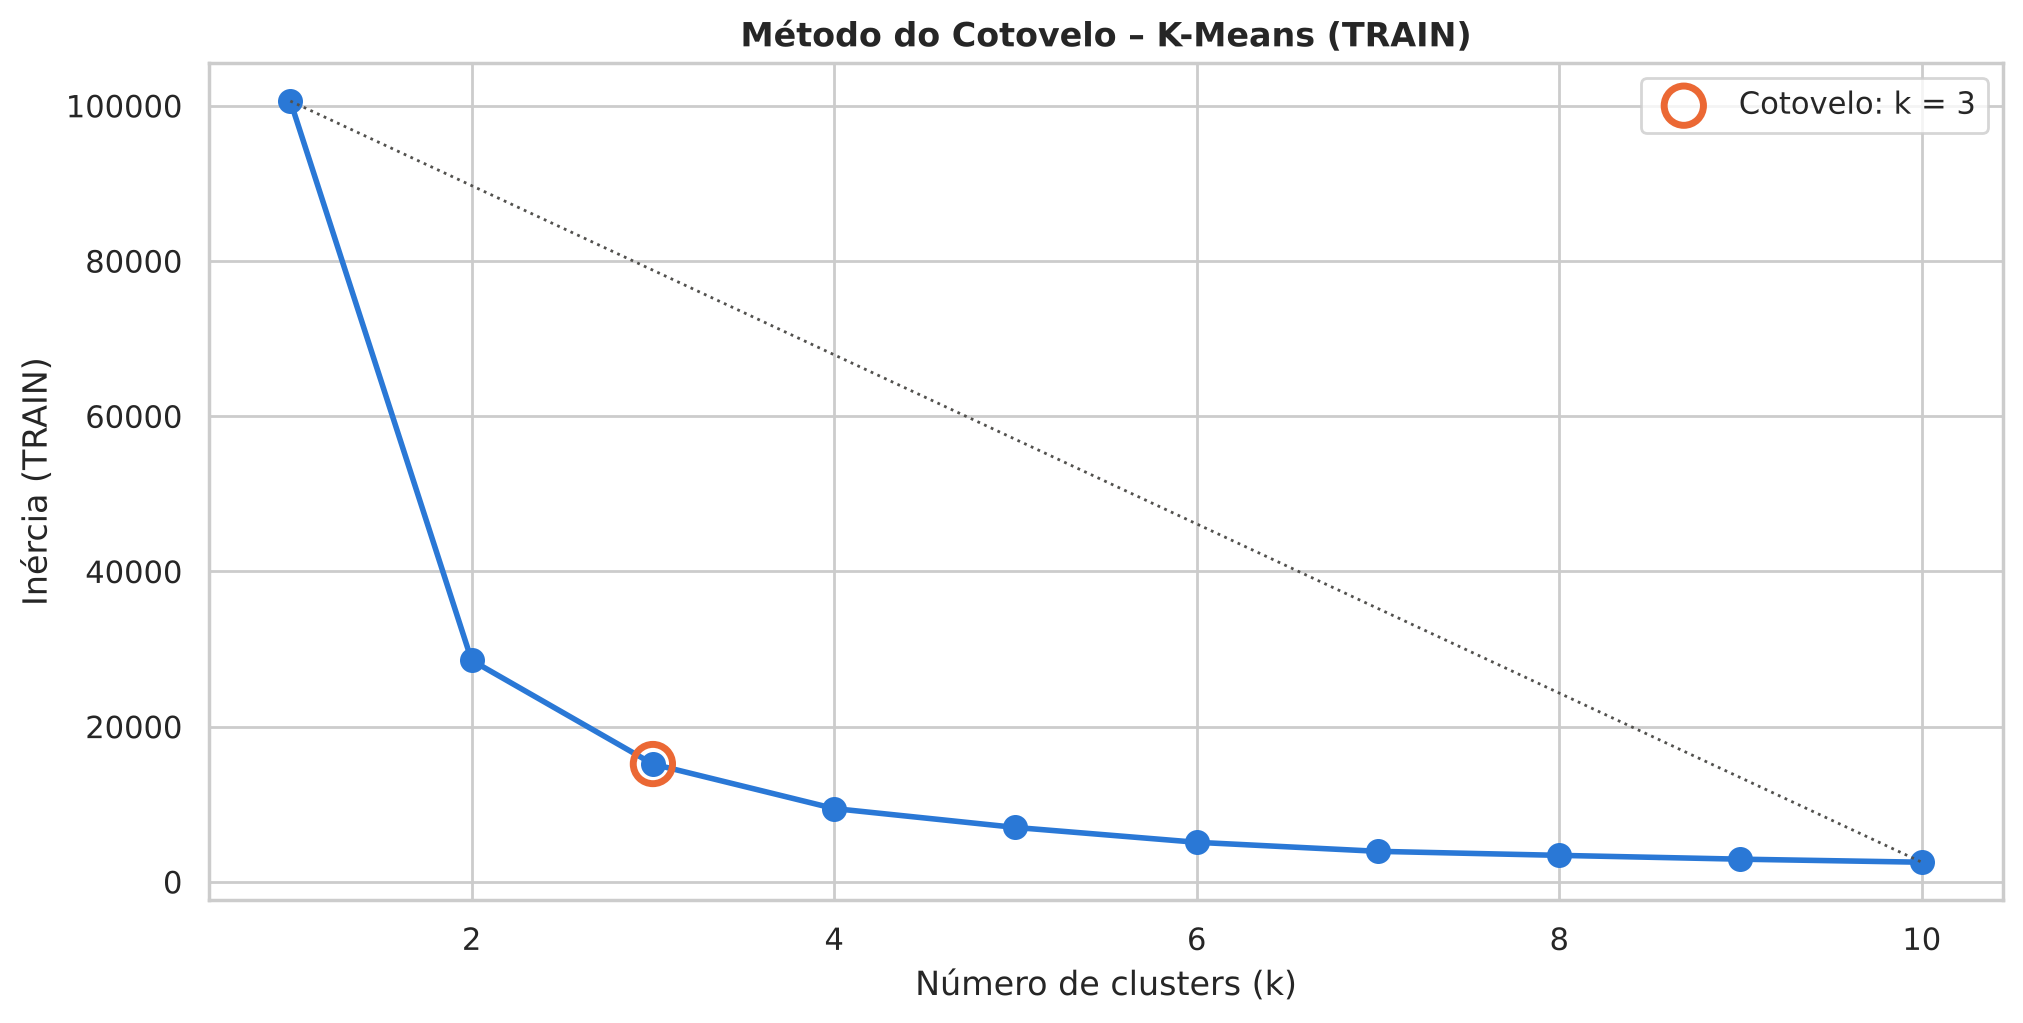

**Cotovelo em k = 3** (maior distância à reta: 0,4588). A redução da inércia ao acrescentar um cluster cai de 71,6% → 46,8% → 37,8% → 25,8% (k = 2 a 5): depois do cotovelo, cada cluster extra traz ganho cada vez menor.

In [ ]:
# =====================================================================
# A2.3 – MÉTODO DO COTOVELO (inércia = soma dos quadrados intra-cluster) –
# TRAIN
# =====================================================================
KS = range(1, 11)
inercia = np.array([
    KMeans(k, n_init=10, random_state=SEED).fit(X_train_clu).inertia_
    for k in KS
])

# Ponto de cotovelo (critério objetivo): maior distância entre a curva
# normalizada
# e a reta que liga o 1º ao último ponto (método "Kneedle").
kn = (np.array(KS) - KS[0]) / (KS[-1] - KS[0])
yn = (inercia - inercia.min()) / (inercia.max() - inercia.min())
dist = np.abs(kn + yn - 1) / np.sqrt(2)
K_COTOVELO = int(np.array(KS)[dist.argmax()])

tab_cot = pd.DataFrame(
    {
        "Inércia": inercia,
        "Redução (%)": np.r_[
            np.nan, -np.diff(inercia) / inercia[:-1] * 100
        ],
        "Distância à reta": dist,
    },
    index=pd.Index(KS, name="k"),
)
display(tab_cot.round(4))

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.plot(list(KS), inercia, "o-", color="#2a78d6", lw=2, ms=8)
ax.plot(
    [KS[0], KS[-1]],
    [inercia[0], inercia[-1]],
    ls=":",
    color="#52514e",
    lw=1,
)
ax.scatter(
    K_COTOVELO,
    inercia[K_COTOVELO - 1],
    s=200,
    facecolors="none",
    edgecolors="#eb6834",
    lw=2.5,
    label=f"Cotovelo: k = {K_COTOVELO}",
    zorder=5,
)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inércia (TRAIN)")
ax.set_title("Método do Cotovelo – K-Means (TRAIN)", fontweight="bold")
ax.legend()
plt.show()
RESULTADOS["A2_cotovelo"] = {"k": K_COTOVELO, "tabela": tab_cot}
display(
    Markdown(
        f"**Cotovelo em k = {K_COTOVELO}** (maior distância à reta:"
        f" {br(dist.max(), 4)}). A redução da inércia ao acrescentar um"
        " cluster cai de "
        + " → ".join(
            f"{br(tab_cot.loc[k, 'Redução (%)'], 1)}%"
            for k in range(2, min(K_COTOVELO + 3, 11))
        )
        + f" (k = 2 a {min(K_COTOVELO + 2, 10)}): depois do cotovelo, cada"
        " cluster extra traz ganho cada vez menor."
    )
)

##Atividade A2.4 (4º Passo): Aplicar o Método da Silhueta

k,2,3,4,5,6,7,8,9,10
Silhueta média,0.6257,0.6057,0.5743,0.5712,0.5655,0.5427,0.5256,0.5133,0.4981


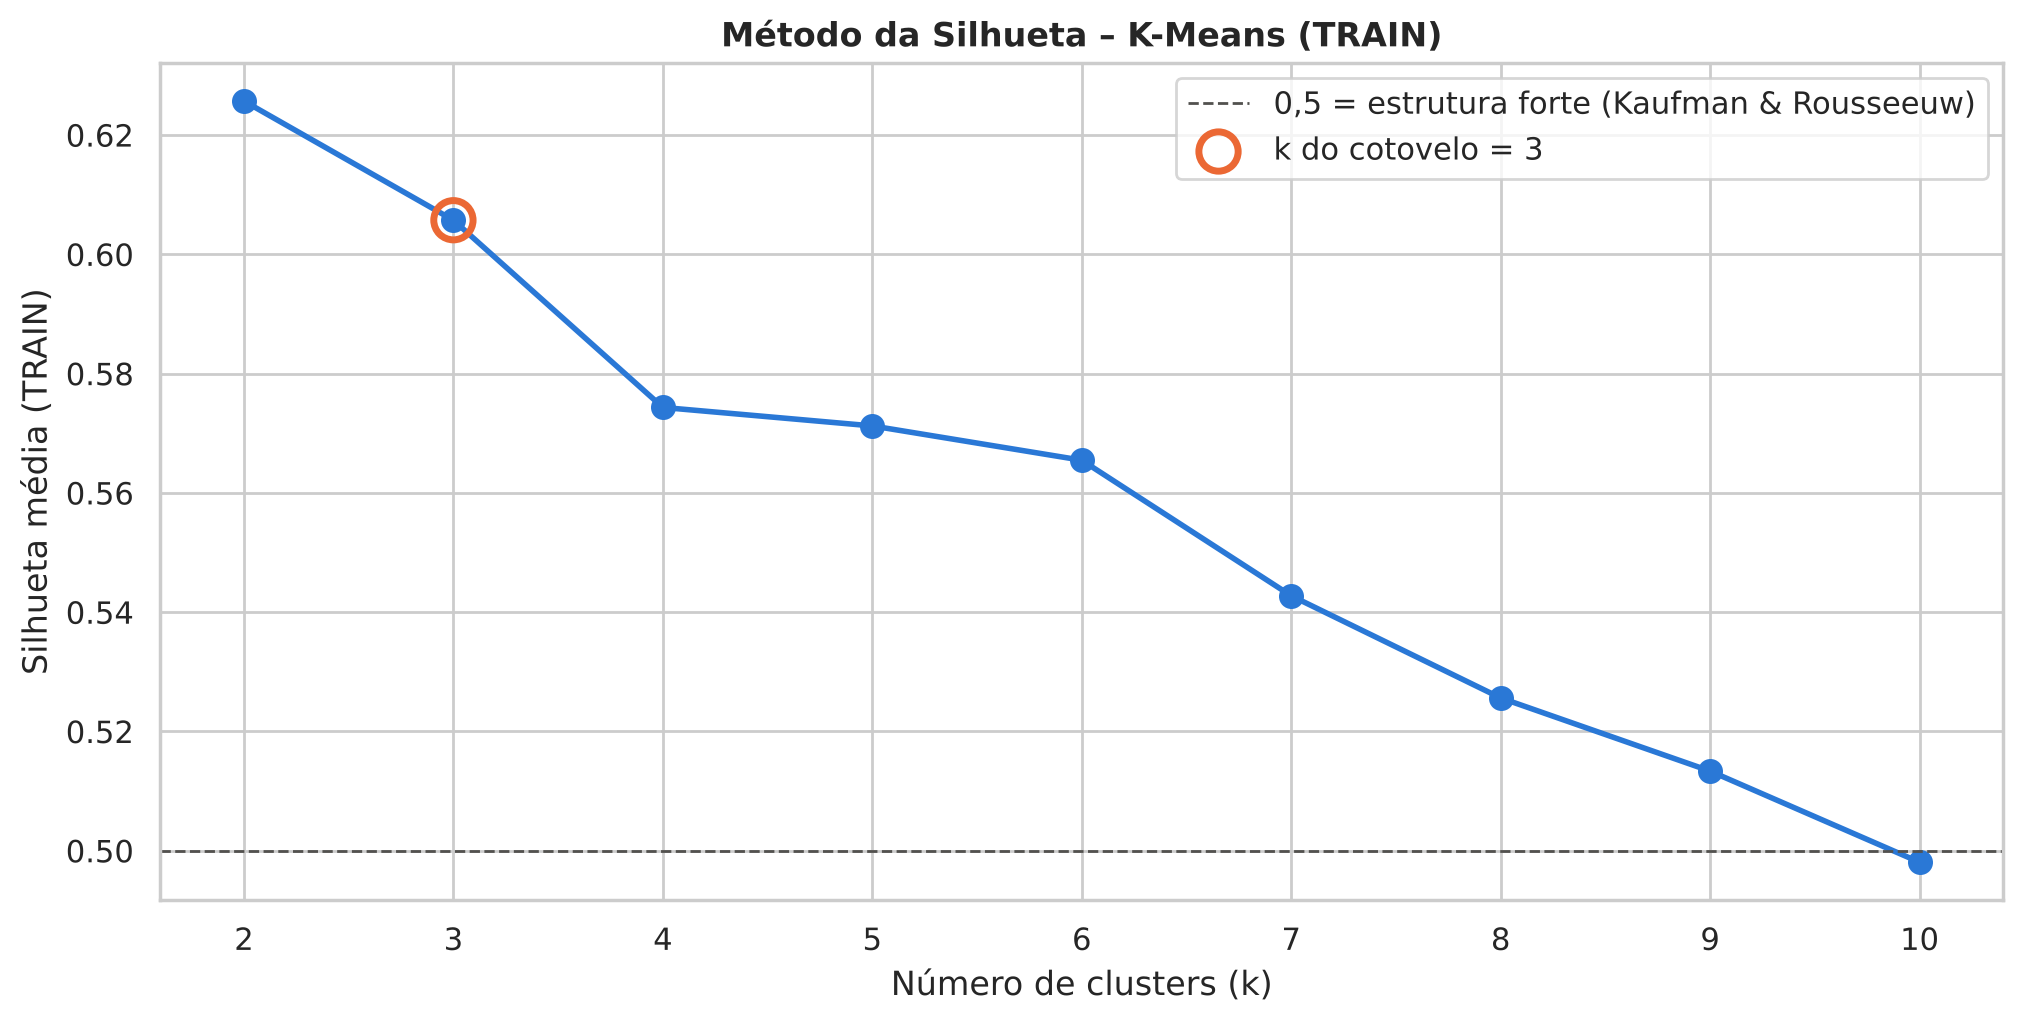

**Silhueta:** o maior valor ocorre em k = 2 (0,6257); em k = 3 (cotovelo) a silhueta é 0,6057. **Decisão: k = 3**. A silhueta de k = 3 está acima de 0,5 (estrutura forte), então, pela regra definida, prevalece o cotovelo. A perda de silhueta em relação a k = 2 é de apenas 0,0200, e k = 3 separa os clientes em faixas de valor mais detalhadas, que podem ser comparadas com os 3 tipos de conta (A2.6).

In [ ]:
# =====================================================================
# A2.4 – MÉTODO DA SILHUETA – TRAIN
# s(i) = (b − a) / max(a, b): próximo de 1 = bem separado; ≈ 0 = grupos
# sobrepostos.
# O cálculo exato exige todas as distâncias par a par (50.300² ≈ 2,5
# bilhões), por isso
# a silhueta é estimada em 10.000 pontos sorteados do TRAIN (SEED fixa).
# =====================================================================
silh = pd.Series(
    {
        k: silhouette_score(
            X_train_clu,
            KMeans(k, n_init=10, random_state=SEED).fit_predict(
                X_train_clu
            ),
            sample_size=10_000,
            random_state=SEED,
        )
        for k in range(2, 11)
    },
    name="Silhueta média",
)
silh.index.name = "k"
checar_finitos(silh, "silhueta")
K_SILHUETA = int(silh.idxmax())
display(silh.to_frame().T.round(4))

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
ax.plot(silh.index, silh.values, "o-", color="#2a78d6", lw=2, ms=8)
ax.axhline(
    0.5,
    color="#52514e",
    ls="--",
    lw=1,
    label="0,5 = estrutura forte (Kaufman & Rousseeuw)",
)
ax.scatter(
    K_COTOVELO,
    silh[K_COTOVELO],
    s=200,
    facecolors="none",
    edgecolors="#eb6834",
    lw=2.5,
    label=f"k do cotovelo = {K_COTOVELO}",
    zorder=5,
)
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Silhueta média (TRAIN)")
ax.set_title("Método da Silhueta – K-Means (TRAIN)", fontweight="bold")
ax.legend()
plt.show()

# Regra de decisão (definida antes de ver o resultado final):
# usa-se o k do COTOVELO se a silhueta dele indicar estrutura forte (>= 0,5);
# caso contrário, usa-se o k de maior silhueta.
K_FINAL = K_COTOVELO if silh[K_COTOVELO] >= 0.5 else K_SILHUETA
RESULTADOS["A2_silhueta"] = {
    "tabela": silh,
    "k_silhueta": K_SILHUETA,
    "k_final": K_FINAL,
}
display(
    Markdown(
        f"**Silhueta:** o maior valor ocorre em k = {K_SILHUETA}"
        f" ({br(silh[K_SILHUETA], 4)}); em k = {K_COTOVELO} (cotovelo) a"
        f" silhueta é {br(silh[K_COTOVELO], 4)}. **Decisão: k ="
        f" {K_FINAL}**. "
        + (
            f"A silhueta de k = {K_COTOVELO} está acima de 0,5 (estrutura"
            " forte), então, pela regra definida, prevalece o cotovelo. A"
            f" perda de silhueta em relação a k = {K_SILHUETA} é de apenas"
            f" {br(silh[K_SILHUETA] - silh[K_COTOVELO], 4)}, e k ="
            f" {K_COTOVELO} separa os clientes em faixas de valor mais"
            " detalhadas, que podem ser comparadas com os"
            f" {len(ORDEM_CONTA)} tipos de conta (A2.6)."
            if K_FINAL == K_COTOVELO and K_FINAL != K_SILHUETA
            else (
                "Cotovelo e silhueta indicam o mesmo k."
                if K_COTOVELO == K_SILHUETA
                else (
                    "A silhueta do cotovelo ficou abaixo de 0,5; prevalece"
                    " o k de maior silhueta."
                )
            )
        )
    )
)

##Atividade A2.5 (5º Passo): Criar o Modelo: **Clusters**

### Perfil dos clusters (TRAIN, valores em R$)

,Centróide RENDA BRUTO (R$),Centróide TOTAL (R$),RENDA BRUTO (R$) – média,RENDA BRUTO (R$) – mediana,TOTAL (R$) – média,TOTAL (R$) – mediana,n TRAIN
Cluster,,,,,,,
1,3268.90,326.09,3283.55,3251.63,356.88,355.56,28226
2,8028.98,796.62,8176.11,7788.32,864.20,849.85,12588
3,19954.88,2113.07,20291.20,20668.85,2300.13,2220.39,9486


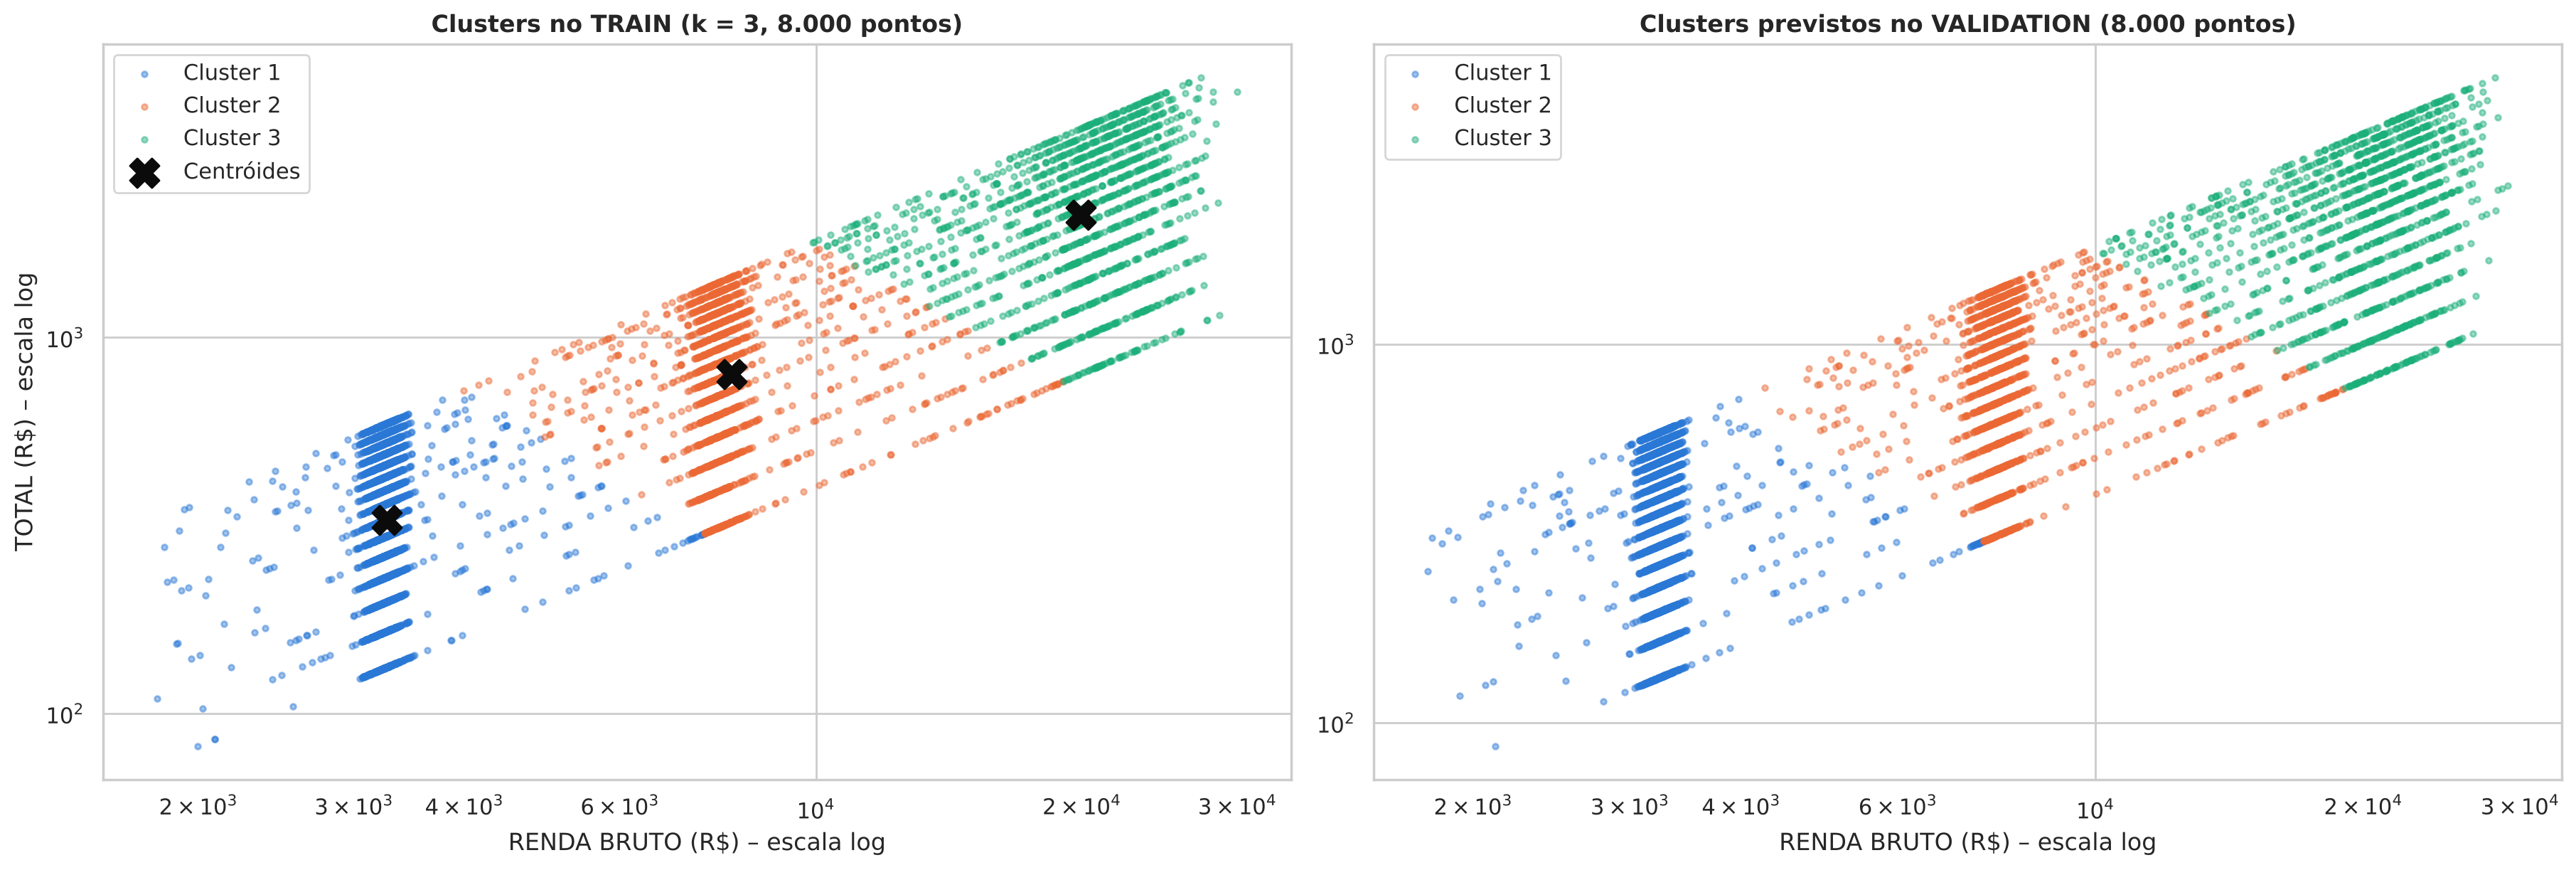

In [ ]:
# NDARRAY - TRANINING: train e validation
# =====================================================================
# A2.5 – CRIAR O MODELO: K-Means com k = K_FINAL (ajustado no TRAIN)
# =====================================================================
MODELO_CLU = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(
    X_train_clu
)

# Rótulos ordenados pela RENDA do centróide (Cluster 1 = menor renda) para
# facilitar a leitura
ordem_c = np.argsort(MODELO_CLU.cluster_centers_[:, 0])
REMAP = {int(c): i + 1 for i, c in enumerate(ordem_c)}


def rotular(X):
    return np.vectorize(REMAP.get)(MODELO_CLU.predict(X))


clu_train = rotular(X_train_clu)
clu_val = rotular(X_val_clu)
CLUSTERS = list(range(1, K_FINAL + 1))
CORES_CLU = dict(
    zip(
        CLUSTERS,
        [
            "#2a78d6",
            "#eb6834",
            "#1baf7a",
            "#eda100",
            "#e87ba4",
            "#008300",
            "#6250d6",
            "#e34948",
        ],
    )
)

# Centróides em R$ (desfazendo a normalização e o log)
centros = pd.DataFrame(
    np.exp(
        scaler_clu.inverse_transform(MODELO_CLU.cluster_centers_[ordem_c])
    ),
    columns=[f"Centróide {v}" for v in VARS_CLU],
    index=pd.Index(CLUSTERS, name="Cluster"),
)
perfil = (
    train.assign(Cluster=clu_train)
    .groupby("Cluster")[VARS_CLU]
    .agg(["mean", "median"])
)
perfil.columns = [
    f"{a} – {'média' if b == 'mean' else 'mediana'}"
    for a, b in perfil.columns
]
perfil = centros.join(perfil)
perfil["n TRAIN"] = (
    pd.Series(clu_train).value_counts().sort_index().to_numpy()
)
checar_finitos(perfil, "perfil dos clusters")
display(Markdown("### Perfil dos clusters (TRAIN, valores em R$)"))
display(perfil.round(2))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), layout="constrained")
i = np.random.default_rng(SEED).choice(len(clu_train), 8000, replace=False)
for c in CLUSTERS:
    m = clu_train[i] == c
    axes[0].scatter(
        train[VARS_CLU[0]].to_numpy()[i][m],
        train[VARS_CLU[1]].to_numpy()[i][m],
        s=8,
        alpha=0.45,
        color=CORES_CLU[c],
        label=f"Cluster {c}",
    )
axes[0].scatter(
    centros.iloc[:, 0],
    centros.iloc[:, 1],
    marker="X",
    s=220,
    color="#0b0b0b",
    label="Centróides",
)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("RENDA BRUTO (R$) – escala log")
axes[0].set_ylabel("TOTAL (R$) – escala log")
axes[0].set_title(
    f"Clusters no TRAIN (k = {K_FINAL}, 8.000 pontos)", fontweight="bold"
)
axes[0].legend()
for c in CLUSTERS:
    m = clu_val[i] == c
    axes[1].scatter(
        validation[VARS_CLU[0]].to_numpy()[i][m],
        validation[VARS_CLU[1]].to_numpy()[i][m],
        s=8,
        alpha=0.45,
        color=CORES_CLU[c],
        label=f"Cluster {c}",
    )
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("RENDA BRUTO (R$) – escala log")
axes[1].set_title(
    "Clusters previstos no VALIDATION (8.000 pontos)", fontweight="bold"
)
axes[1].legend()
plt.show()
RESULTADOS["A2_perfil"] = perfil

In [ ]:
# NDARRAY - TESTE: test
clu_test = rotular(X_test_clu)
print(
    "TEST – clusters previstos:",
    pd.Series(clu_test).value_counts().sort_index().to_dict(),
)

TEST – clusters previstos: {1: 28237, 2: 12580, 3: 9483}


##Atividade A2.6 (6º Passo): Medir a acurácia (score) dos Modelos de Clusterização:

####Atividade A2.6.1: Medir a Proporção dos clusters: Conjunto TRAIN

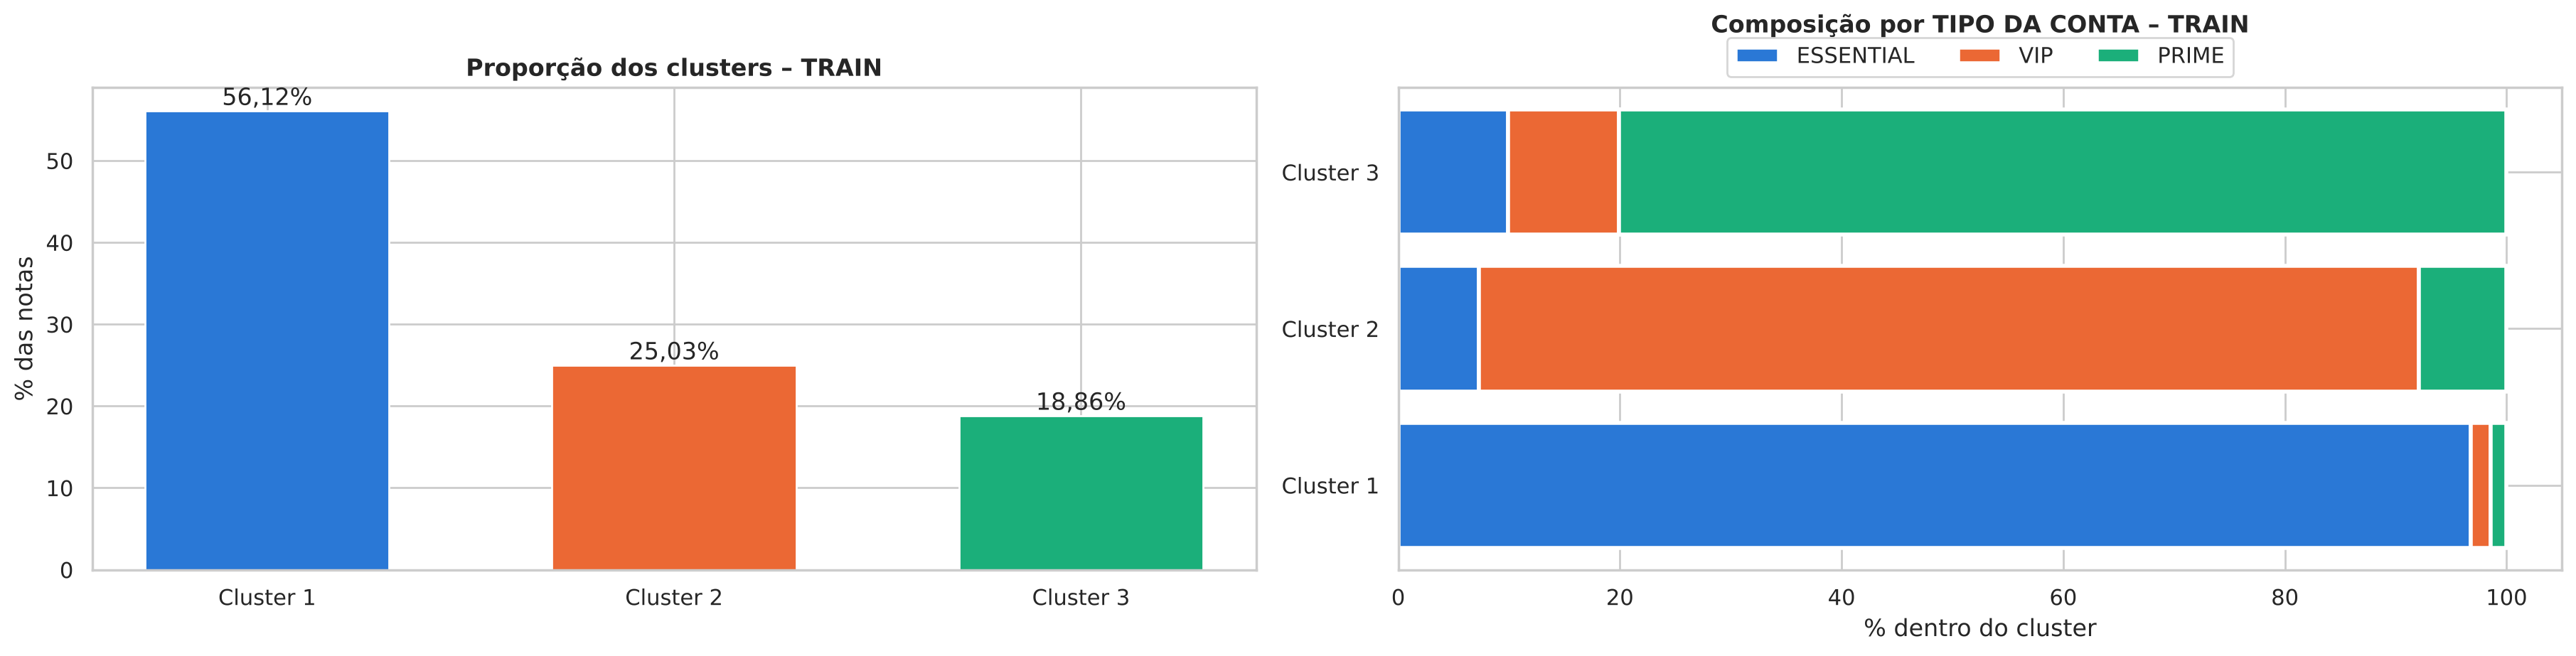

,% das notas,n,Tipo predominante,% do tipo predominante
1,56.12,28226,ESSENTIAL,96.79
2,25.03,12588,VIP,84.77
3,18.86,9486,PRIME,80.05


,Silhueta média,ARI (clusters x TIPO DA CONTA)
TRAIN,0.6057,0.7724


In [ ]:
def proporcao_clusters(rotulos, rot_externo, X, nome):
    """
    Proporção dos clusters, silhueta (10.000 pontos), cruzamento com TIPO DA
    CONTA e ARI.
    """
    prop = (
        pd.Series(rotulos)
        .value_counts(normalize=True)
        .reindex(CLUSTERS)
        .fillna(0)
        * 100
    )
    sil = silhouette_score(
        X, rotulos, sample_size=10_000, random_state=SEED
    )
    ari = adjusted_rand_score(rot_externo, rotulos)
    cruz = (
        pd.crosstab(
            pd.Series(rotulos, name="Cluster"),
            pd.Series(rot_externo, name=ESTRATO),
            normalize="index",
        ).reindex(columns=ORDEM_CONTA)
        * 100
    )
    fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), layout="constrained")
    axes[0].bar(
        [f"Cluster {c}" for c in CLUSTERS],
        prop.values,
        color=[CORES_CLU[c] for c in CLUSTERS],
        width=0.6,
    )
    for j, v in enumerate(prop.values):
        axes[0].text(j, v, f"{br(v, 2)}%", ha="center", va="bottom")
    axes[0].set_ylabel("% das notas")
    axes[0].set_title(f"Proporção dos clusters – {nome}", fontweight="bold")
    base = np.zeros(len(CLUSTERS))
    for t in ORDEM_CONTA:
        axes[1].barh(
            [f"Cluster {c}" for c in CLUSTERS],
            cruz[t].values,
            left=base,
            color=CORES_CONTA[t],
            label=t,
            edgecolor="white",
            linewidth=2,
        )
        base += cruz[t].values
    axes[1].set_xlabel("% dentro do cluster")
    axes[1].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
    axes[1].set_title(
        f"Composição por TIPO DA CONTA – {nome}", fontweight="bold", pad=28
    )
    plt.show()
    resumo = prop.rename("% das notas").to_frame()
    resumo["n"] = (
        pd.Series(rotulos)
        .value_counts()
        .reindex(CLUSTERS)
        .fillna(0)
        .astype(int)
    )
    resumo["Tipo predominante"] = cruz.idxmax(axis=1)
    resumo["% do tipo predominante"] = cruz.max(axis=1)
    display(resumo.round(2))
    display(
        pd.Series(
            {"Silhueta média": sil, "ARI (clusters x TIPO DA CONTA)": ari},
            name=nome,
        )
        .to_frame()
        .T.round(4)
    )
    checar_finitos(resumo, f"proporções {nome}")
    return {
        "prop": prop,
        "silhueta": sil,
        "ari": ari,
        "cruz": cruz,
        "resumo": resumo,
    }


prop_train = proporcao_clusters(clu_train, rot_train, X_train_clu, "TRAIN")

####Atividade A2.6.2: Medir a Proporção dos clusters: Conjunto VALIDATION

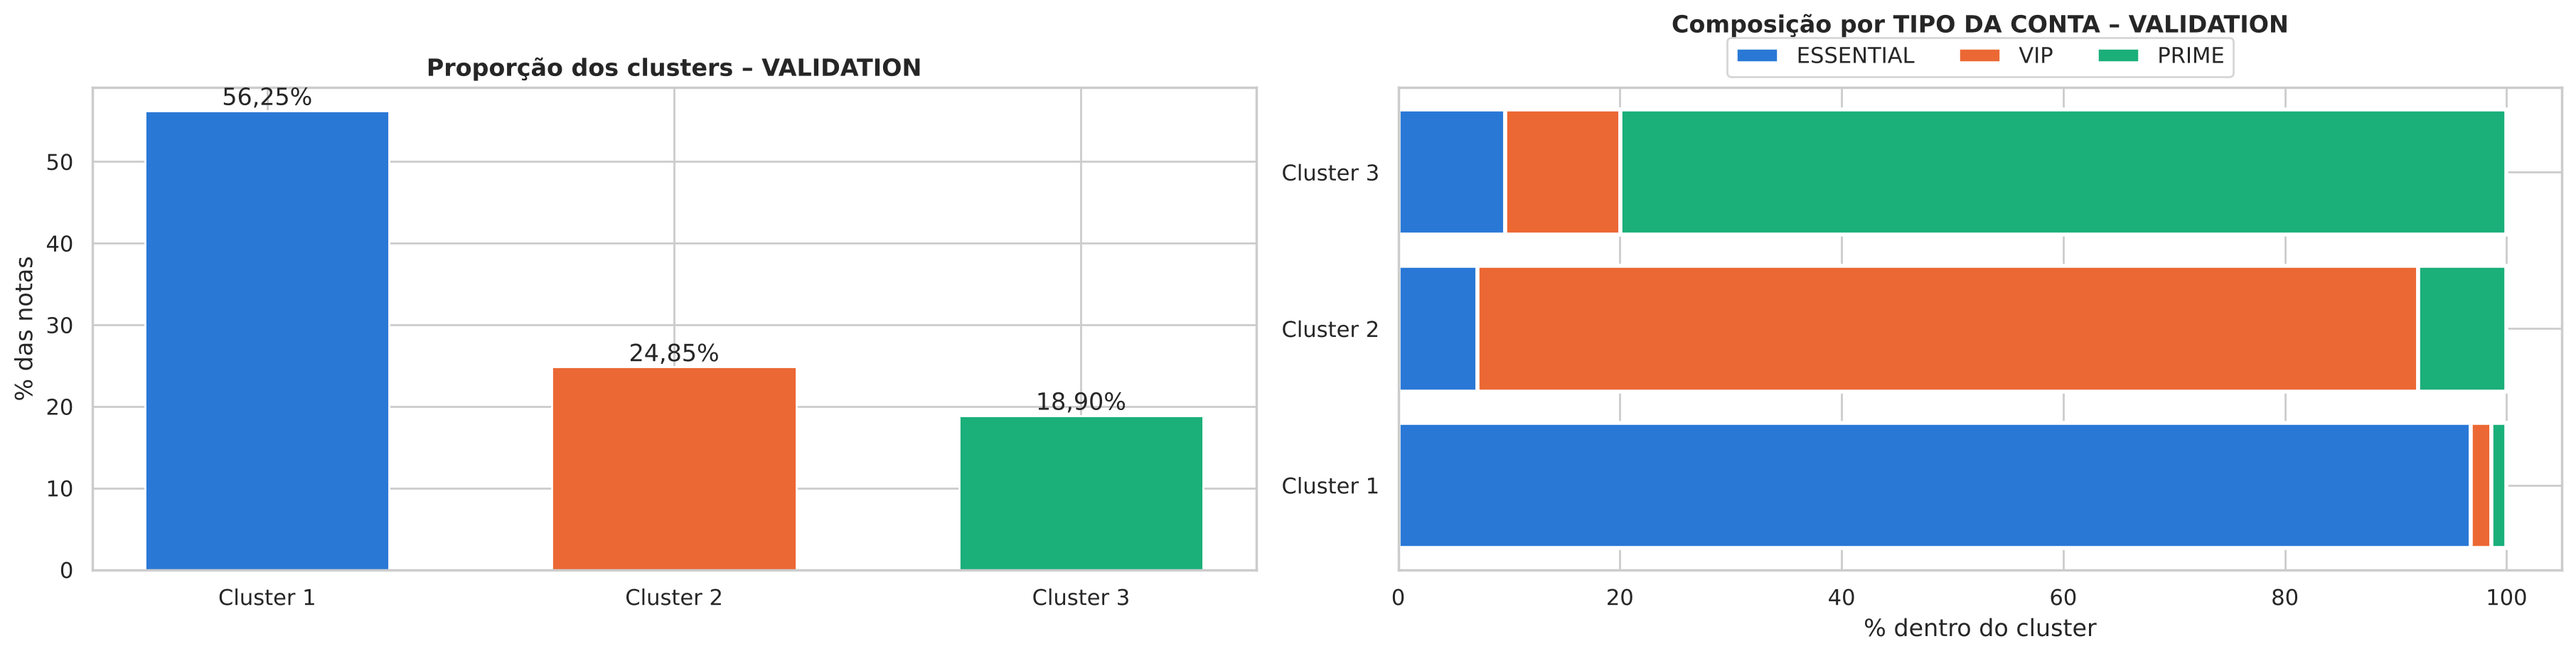

,% das notas,n,Tipo predominante,% do tipo predominante
1,56.25,28292,ESSENTIAL,96.74
2,24.85,12502,VIP,84.87
3,18.90,9506,PRIME,79.97


,Silhueta média,ARI (clusters x TIPO DA CONTA)
VALIDATION,0.5976,0.7733


In [ ]:
prop_val = proporcao_clusters(clu_val, rot_val, X_val_clu, "VALIDATION")

####Atividade A2.6.3: Medir a Proporção dos clusters: Conjunto TEST

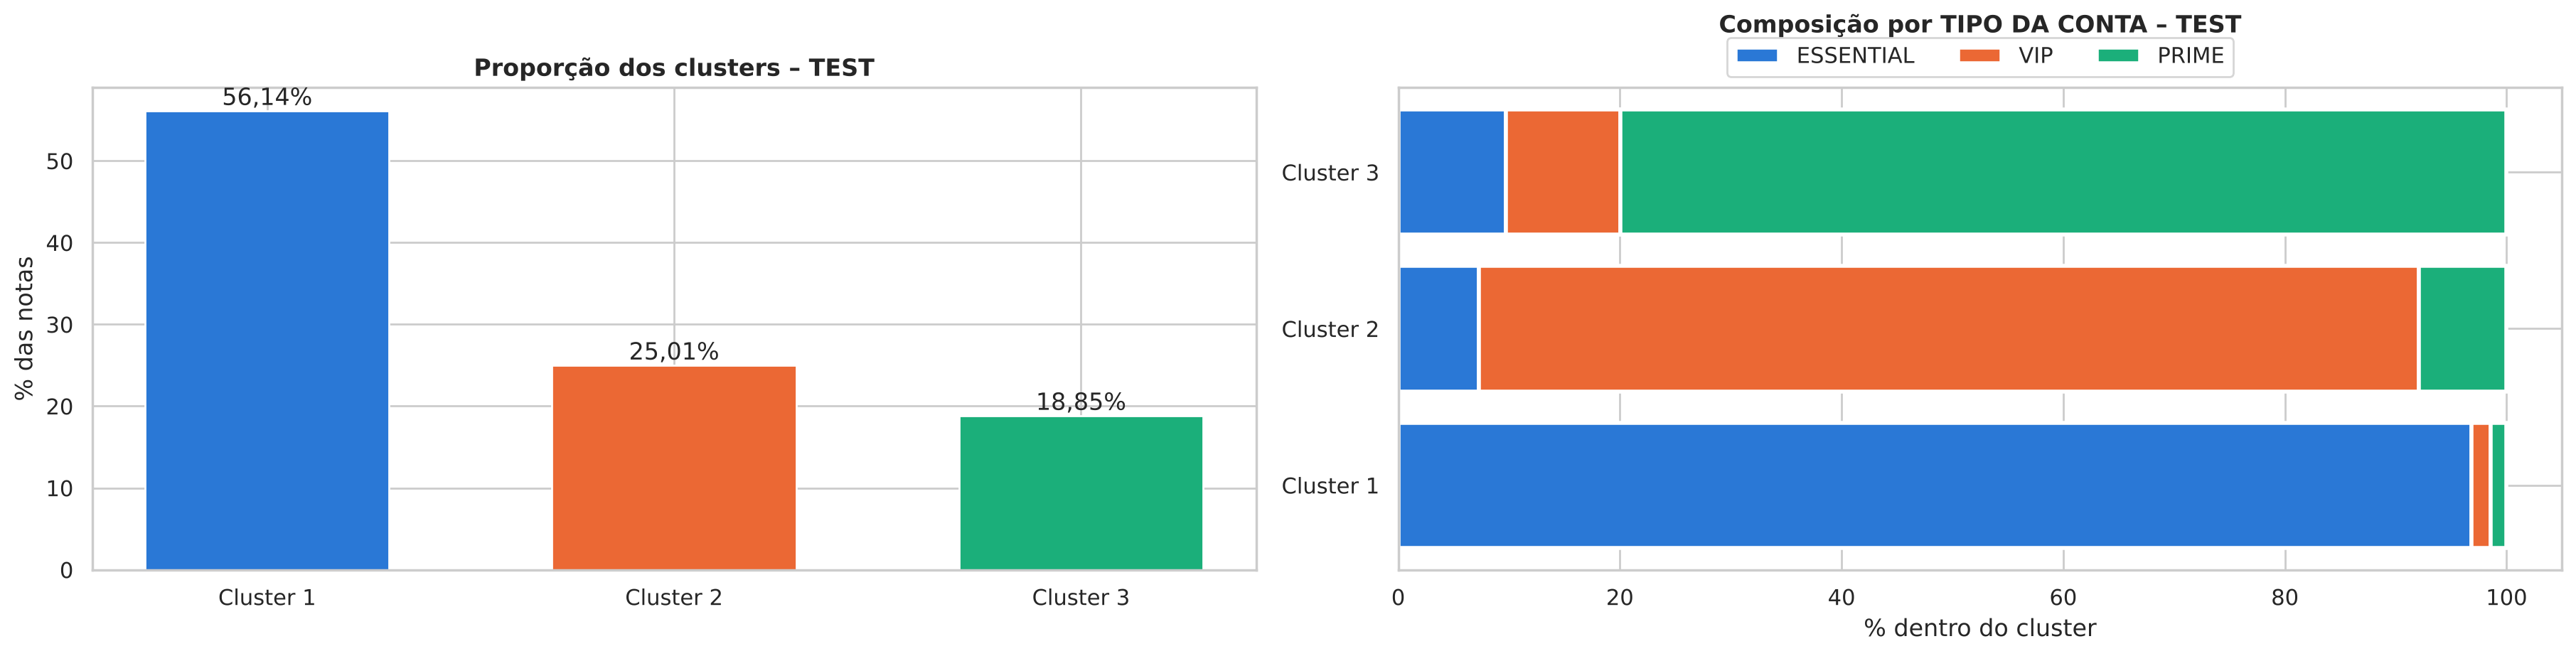

,% das notas,n,Tipo predominante,% do tipo predominante
1,56.14,28237,ESSENTIAL,96.84
2,25.01,12580,VIP,84.82
3,18.85,9483,PRIME,79.95


,Silhueta média,ARI (clusters x TIPO DA CONTA)
TEST,0.6035,0.774


### Proporção (%) dos clusters nos três conjuntos

,TRAIN,VALIDATION,TEST,Amplitude (p.p.)
Cluster,,,,
1,56.115,56.247,56.137,0.131
2,25.026,24.855,25.010,0.171
3,18.859,18.899,18.853,0.046


Qui² de homogeneidade (H0: mesmas proporções nos 3 conjuntos): χ² = 0,481, p = 0,9753 → **Não se rejeitou H0**.

**Leitura:** as proporções variam no máximo 0,171 p.p. entre TRAIN, VALIDATION e TEST; a silhueta fica entre 0,5976 e 0,6057. O modelo é **estável**: produz os mesmos grupos, nas mesmas proporções, em dados que não viu.

In [ ]:
prop_test = proporcao_clusters(clu_test, rot_test, X_test_clu, "TEST")

# Estabilidade: as proporções são as mesmas nos três conjuntos? (Qui² de
# homogeneidade)
cont = pd.DataFrame({
    k: pd.Series(v).value_counts().reindex(CLUSTERS)
    for k, v in [
        ("TRAIN", clu_train),
        ("VALIDATION", clu_val),
        ("TEST", clu_test),
    ]
})
chi = stats.chi2_contingency(cont)
estab = pd.DataFrame(
    {
        k: [p["prop"][c] for c in CLUSTERS]
        for k, p in [
            ("TRAIN", prop_train),
            ("VALIDATION", prop_val),
            ("TEST", prop_test),
        ]
    },
    index=pd.Index(CLUSTERS, name="Cluster"),
)
estab["Amplitude (p.p.)"] = estab.max(axis=1) - estab.min(axis=1)
display(Markdown("### Proporção (%) dos clusters nos três conjuntos"))
display(estab.round(3))
display(
    Markdown(
        "Qui² de homogeneidade (H0: mesmas proporções nos 3 conjuntos): χ²"
        f" = {br(chi.statistic, 3)}, p = {br_p(chi.pvalue)} →"
        f" **{decisao(chi.pvalue)}**."
    )
)
RESULTADOS["A2_proporcoes"] = {
    "estab": estab,
    "chi_p": chi.pvalue,
    "silhueta": {
        k: p["silhueta"]
        for k, p in [
            ("TRAIN", prop_train),
            ("VALIDATION", prop_val),
            ("TEST", prop_test),
        ]
    },
    "ari": {
        k: p["ari"]
        for k, p in [
            ("TRAIN", prop_train),
            ("VALIDATION", prop_val),
            ("TEST", prop_test),
        ]
    },
    "cruz_test": prop_test["cruz"],
}
sils = [p["silhueta"] for p in (prop_train, prop_val, prop_test)]
display(
    Markdown(
        "**Leitura:** as proporções variam no máximo"
        f" {br(estab['Amplitude (p.p.)'].max(), 3)} p.p. entre TRAIN,"
        f" VALIDATION e TEST; a silhueta fica entre {br(min(sils), 4)} e"
        f" {br(max(sils), 4)}. O modelo é **estável**: produz os mesmos"
        " grupos, nas mesmas proporções, em dados que não viu."
    )
)

##Atividade A2.7 (7º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

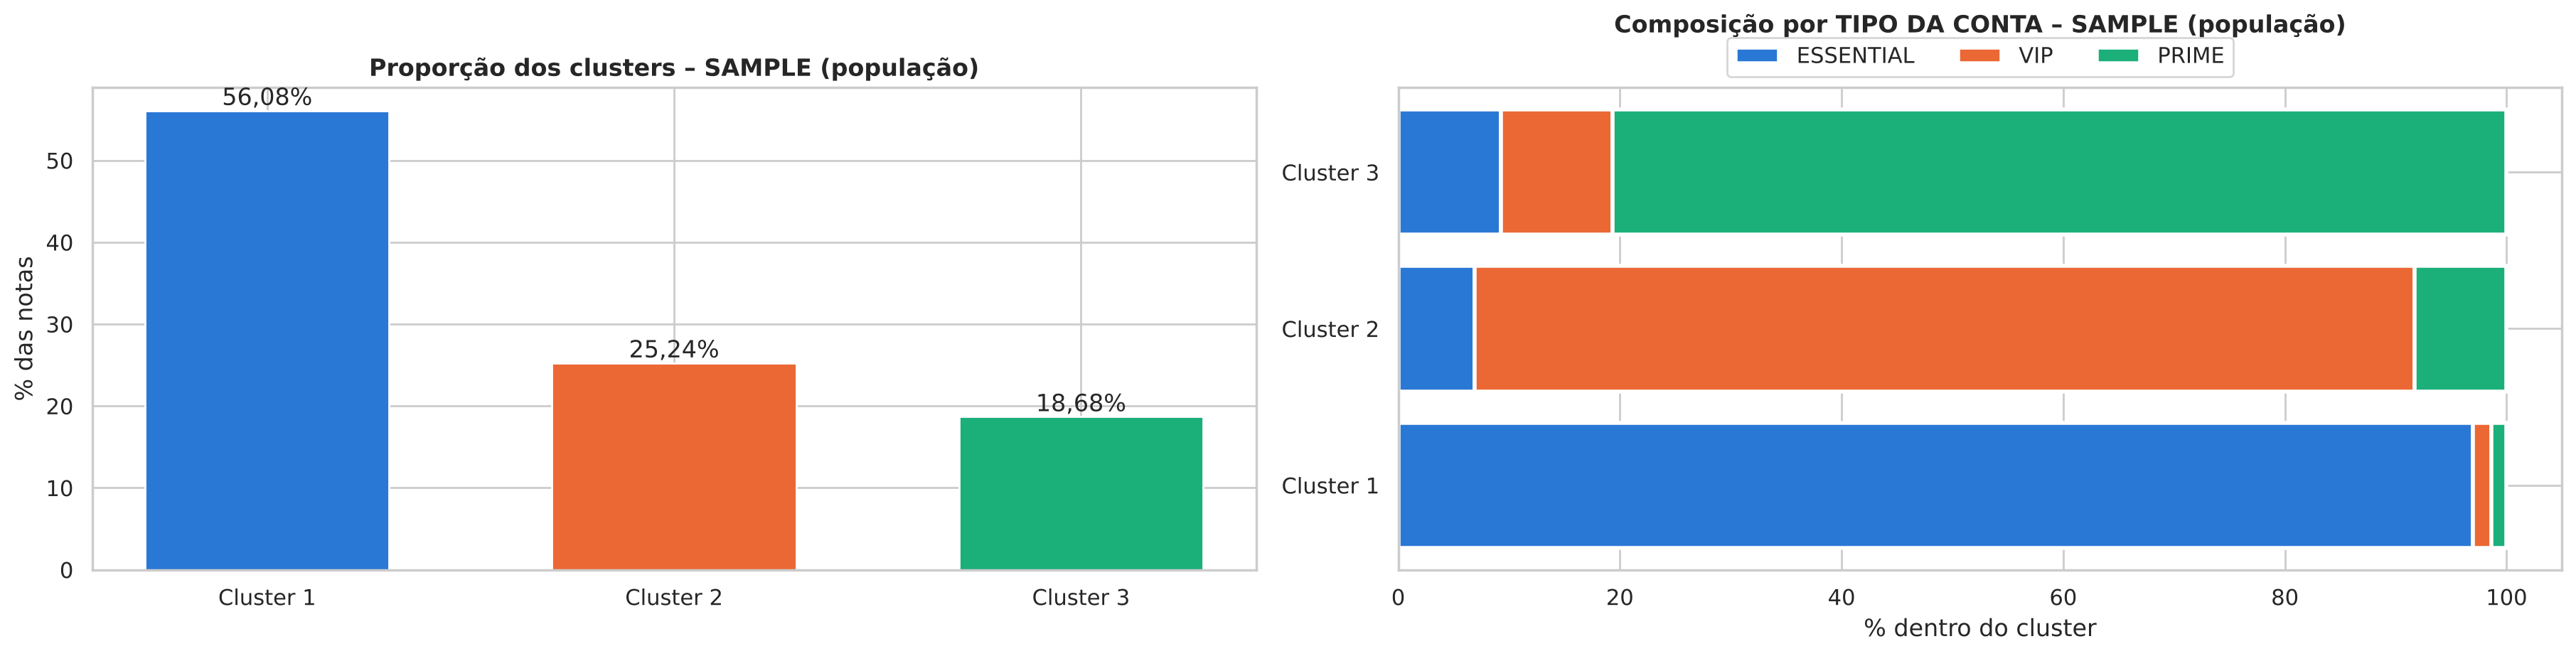

,% das notas,n,Tipo predominante,% do tipo predominante
1,56.08,28208,ESSENTIAL,96.98
2,25.24,12698,VIP,84.77
3,18.68,9394,PRIME,80.66


,Silhueta média,ARI (clusters x TIPO DA CONTA)
SAMPLE (população),0.5977,0.7802


### Perfil e peso no faturamento de cada cluster (SAMPLE)

,n,RENDA média (R$),TOTAL médio (R$),TOTAL somado (R$),% das notas,% do faturamento
Cluster,,,,,,
1,28208,3286.42,359.34,10136393.69,56.08,23.69
2,12698,8214.98,865.13,10985406.78,25.24,25.67
3,9394,20254.71,2306.26,21665033.82,18.68,50.63


Qui² de aderência (H0: proporções da SAMPLE = proporções do TRAIN): p = 0,3936 → **Não se rejeitou H0**.

**Conclusão A2.7:** na amostra da população, os 3 clusters aparecem com 56,08% (Cluster 1), 25,24% (Cluster 2), 18,68% (Cluster 3); silhueta = 0,5977 e ARI com o TIPO DA CONTA = 0,7802. O Cluster 3 reúne 18,68% das notas e 50,63% do faturamento.

In [ ]:
# =====================================================================
# A2.7 – TESTAR O MODELO NA POPULAÇÃO: SAMPLE
# =====================================================================
clu_sample = rotular(X_sample_clu)
prop_sample = proporcao_clusters(
    clu_sample, rot_sample, X_sample_clu, "SAMPLE (população)"
)

obs = pd.Series(clu_sample).value_counts().reindex(CLUSTERS)
esp = prop_train["prop"] / 100 * len(clu_sample)
p_ader = stats.chisquare(obs, esp).pvalue
perfil_sample = (
    sample.assign(Cluster=clu_sample)
    .groupby("Cluster")
    .agg(
        n=(TARGET_REG, "size"),
        renda_media=("RENDA BRUTO (R$)", "mean"),
        total_medio=(TARGET_REG, "mean"),
        total_soma=(TARGET_REG, "sum"),
    )
)
perfil_sample["% das notas"] = (
    perfil_sample["n"] / perfil_sample["n"].sum() * 100
)
perfil_sample["% do faturamento"] = (
    perfil_sample["total_soma"] / perfil_sample["total_soma"].sum() * 100
)
perfil_sample = perfil_sample.rename(
    columns={
        "renda_media": "RENDA média (R$)",
        "total_medio": "TOTAL médio (R$)",
        "total_soma": "TOTAL somado (R$)",
    }
)
checar_finitos(perfil_sample, "perfil sample")
display(
    Markdown("### Perfil e peso no faturamento de cada cluster (SAMPLE)")
)
display(perfil_sample.round(2))
display(
    Markdown(
        "Qui² de aderência (H0: proporções da SAMPLE = proporções do"
        f" TRAIN): p = {br_p(p_ader)} → **{decisao(p_ader)}**."
    )
)

RESULTADOS["A2_sample"] = {
    "prop": prop_sample["prop"],
    "silhueta": prop_sample["silhueta"],
    "ari": prop_sample["ari"],
    "p_ader": p_ader,
    "perfil": perfil_sample,
    "cruz": prop_sample["cruz"],
}
top = perfil_sample["% do faturamento"].idxmax()
display(
    Markdown(
        f"**Conclusão A2.7:** na amostra da população, os {K_FINAL}"
        " clusters aparecem com "
        + ", ".join(
            f"{br(prop_sample['prop'][c], 2)}% (Cluster {c})"
            for c in CLUSTERS
        )
        + f"; silhueta = {br(prop_sample['silhueta'], 4)} e ARI com o TIPO"
        f" DA CONTA = {br(prop_sample['ari'], 4)}. O Cluster {top} reúne"
        f" {br(perfil_sample.loc[top, '% das notas'], 2)}% das notas e"
        f" {br(perfil_sample.loc[top, '% do faturamento'], 2)}% do"
        " faturamento."
    )
)

## RELATÓRIO PARCIAL - MODELO DE CLUSTERIZAÇÃO

*    **Objetivo:** segmentar os clientes por **valor** sem usar o tipo de conta (aprendizado não supervisionado). Foram usados log da RENDA BRUTO e log do TOTAL, padronizados com o TRAIN. As 13 variáveis químicas foram testadas e descartadas, porque não formam grupos (silhueta entre 0,0437 e 0,0506).

*    **Número de clusters: k = 3.** O método do cotovelo indicou k = 3. A silhueta foi máxima em k = 2 (0,6257), mas em k = 3 continua acima de 0,5, o que indica estrutura forte (0,6057). Pela regra definida antes da decisão, prevaleceu o cotovelo.

*    **Perfil dos segmentos (TRAIN):** Cluster 1, de **baixo valor** (renda média R$ 3.283,55; TOTAL médio R$ 356,88); Cluster 2, de **valor médio** (R$ 8.176,11; R$ 864,20); Cluster 3, de **alto valor** (R$ 20.291,20; R$ 2.300,13).

*    **Estabilidade:** as proporções dos clusters são praticamente iguais em TRAIN, VALIDATION e TEST (≈ 56% | 25% | 19%; variação máxima de 0,171 p.p.; qui² de homogeneidade p = 0,9753, sem rejeição de H0). Na SAMPLE da população, as proporções também são compatíveis com as do TRAIN (p = 0,3936) e a silhueta é 0,5977.

*    **Relação com o tipo de conta:** sem conhecer o tipo de conta, o modelo reencontra os três níveis de cliente (ARI = 0,7802 na SAMPLE). O Cluster 1 é 96,98% ESSENTIAL, o Cluster 2 é 84,77% VIP e o Cluster 3 é 80,66% PRIME. Os clientes que caem fora do cluster "esperado" para o seu tipo de conta têm gasto incompatível com a conta que possuem.

*    **Recomendação aos gestores:** o Cluster 3 tem 18,68% das notas e responde por **50,63% do faturamento** na amostra da população, por isso deve ser priorizado em ações de retenção e relacionamento. Os clientes de contas inferiores que caem nos clusters 2 e 3 são candidatos naturais a campanhas de *upgrade* de conta.

#Atividade A3: Modelo de Classificação

##Atividade A3.1 (1º Passo): Normalizar - Mapear - Discretizar

In [ ]:
# =====================================================================
# A3.1 – NORMALIZAR – MAPEAR – DISCRETIZAR (y = TIPO DA CONTA)
# =====================================================================
# Reaproveita a base tratada/mapeada/discretizada da A1.1 (train_p,
# validation_p, test_p, sample_p),
# que já trata os negativos químicos com a mediana do TRAIN.
# (a) Mapear a SAÍDA: TIPO DA CONTA -> código da classe (0 = ESSENTIAL, 1 =
# VIP, 2 = PRIME)
CLASSES = ORDEM_CONTA
COD = {c: i for i, c in enumerate(CLASSES)}

# (b) Normalizar as ENTRADAS candidatas (todas, exceto o próprio TIPO DA
# CONTA): z-score do TRAIN
CANDIDATAS_CLF = [
    c for c in train_p.columns if c != "TIPO DA CONTA (ordinal)"
]
scaler_clf = StandardScaler().fit(train_p[CANDIDATAS_CLF])
Z_CLF = {
    k: pd.DataFrame(
        scaler_clf.transform(d[CANDIDATAS_CLF]),
        columns=CANDIDATAS_CLF,
        index=d.index,
    )
    for k, d in zip(NOMES, (train_p, validation_p, test_p, sample_p))
}

dist_classes = pd.DataFrame({
    k: d[ESTRATO].value_counts(normalize=True).reindex(CLASSES) * 100
    for k, d in NOMES.items()
})
display(
    Markdown(
        "### Distribuição (%) das classes de TIPO DA CONTA em cada conjunto"
    )
)
display(dist_classes.round(3))
display(
    Markdown(
        "As classes são **desbalanceadas** (ESSENTIAL ≈"
        f" {br(dist_classes.loc['ESSENTIAL', 'TRAIN'], 1)}%). Por isso,"
        " além da acurácia (score), também é reportado o F1-macro, que dá"
        " o mesmo peso às três classes. Um classificador que respondesse"
        " sempre ESSENTIAL acertaria"
        f" {br(dist_classes.loc['ESSENTIAL', 'TEST'], 2)}% no TEST: essa é"
        " a linha de base a ser superada."
    )
)

### Distribuição (%) das classes de TIPO DA CONTA em cada conjunto

,TRAIN,VALIDATION,TEST,SAMPLE
TIPO DA CONTA,,,,
ESSENTIAL,58.012,58.012,58.012,57.863
VIP,24.109,24.109,24.109,24.205
PRIME,17.879,17.879,17.879,17.932


As classes são **desbalanceadas** (ESSENTIAL ≈ 58,0%). Por isso, além da acurácia (score), também é reportado o F1-macro, que dá o mesmo peso às três classes. Um classificador que respondesse sempre ESSENTIAL acertaria 58,01% no TEST: essa é a linha de base a ser superada.

##Atividade A3.2 (2º Passo) - ETL: Separar Entrada ($X$) da Saída ($y$)

In [ ]:
# a partir daqui temos apenas: NDARRAY
# NDARRAY: train - validation - test

# (1) Seleção das ENTRADAS (X) no TRAIN (mesmo critério da A1.2; alvo nominal)
candidatas_originais = [
    "RENDA BRUTO (R$)",
    "TOTAL (R$)",
    "DEPENDENTES",
    "NOTA DE SATISFAÇÃO (%)",
    "SATISFAÇÃO (1-5)",
    "SEXO",
    "REGIÃO",
    "ESTADO CIVIL",
] + QUIMICAS
base_sel = train.copy()
base_sel["SATISFAÇÃO (1-5)"] = train_p["SATISFAÇÃO (1-5)"]
base_sel[QUIMICAS] = train_p[QUIMICAS]
sel_clf = selecionar_variaveis(
    base_sel, TARGET_CLF, "nominal", candidatas_originais
)
display(
    Markdown(
        f"### Seleção das variáveis de entrada para y = {TARGET_CLF}"
        " (TRAIN, Bonferroni: α/m ="
        f" {br(ALPHA / len(candidatas_originais), 5)})"
    )
)
display(
    sel_clf.style.format({
        "Efeito": "{:.4f}",
        "p_value": "{:.4g}",
        "Limiar (efeito pequeno)": "{:.2f}",
    })
)

VARS_CLF = sel_clf.index[sel_clf["Selecionada?"]].tolist()
COLS_CLF = [
    c for v in VARS_CLF for c in GRUPOS_VARIAVEIS.get(v, ("", [v]))[1]
]

# (2) Separar ENTRADA (X) da SAÍDA (y) -> NDARRAY
X_train_clf, X_val_clf, X_test_clf, X_sample_clf = (
    Z_CLF[k][COLS_CLF].to_numpy()
    for k in ["TRAIN", "VALIDATION", "TEST", "SAMPLE"]
)
y_train_clf, y_val_clf, y_test_clf, y_sample_clf = (
    d[TARGET_CLF].map(COD).to_numpy()
    for d in (train, validation, test, sample)
)
for nome, X, y in [
    ("train", X_train_clf, y_train_clf),
    ("validation", X_val_clf, y_val_clf),
    ("test", X_test_clf, y_test_clf),
    ("sample", X_sample_clf, y_sample_clf),
]:
    print(
        f"{nome:<11} X: {type(X).__name__} {X.shape} | y:"
        f" {type(y).__name__} {y.shape} classes {np.bincount(y)}"
    )
RESULTADOS["A3_selecao"] = sel_clf
display(
    Markdown(
        f"**Entradas selecionadas (X):** {', '.join(VARS_CLF)}. **Saída"
        f" (y):** {TARGET_CLF} (0 = ESSENTIAL, 1 = VIP, 2 = PRIME). Foram"
        f" descartadas {len(candidatas_originais) - len(VARS_CLF)}"
        " variáveis sem associação relevante com o tipo de conta."
    )
)

### Seleção das variáveis de entrada para y = TIPO DA CONTA (TRAIN, Bonferroni: α/m = 0,00238)

,Medida,Efeito,Limiar (efeito pequeno),p_value,Selecionada?
Variável,,,,,
RENDA BRUTO (R$),ε² Kruskal-Wallis,0.6403,0.01,0,True
TOTAL (R$),ε² Kruskal-Wallis,0.5184,0.01,0,True
NOTA DE SATISFAÇÃO (%),ε² Kruskal-Wallis,0.3414,0.01,0,True
REGIÃO,V de Cramér,0.0089,0.10,0.4291,False
ESTADO CIVIL,V de Cramér,0.0069,0.10,0.3085,False
SEXO,V de Cramér,0.0040,0.10,0.6707,False
MEAN: nonflavanoid_phenols,ε² Kruskal-Wallis,0.0001,0.01,0.05548,False
MEAN: alcalinity_of_ash,ε² Kruskal-Wallis,0.0001,0.01,0.0668,False
MEAN: proline,ε² Kruskal-Wallis,0.0001,0.01,0.07546,False


train       X: ndarray (50300, 3) | y: ndarray (50300,) classes [29180 12127  8993]
validation  X: ndarray (50300, 3) | y: ndarray (50300,) classes [29180 12127  8993]
test        X: ndarray (50300, 3) | y: ndarray (50300,) classes [29180 12127  8993]
sample      X: ndarray (50300, 3) | y: ndarray (50300,) classes [29105 12175  9020]


**Entradas selecionadas (X):** RENDA BRUTO (R$), TOTAL (R$), NOTA DE SATISFAÇÃO (%). **Saída (y):** TIPO DA CONTA (0 = ESSENTIAL, 1 = VIP, 2 = PRIME). Foram descartadas 18 variáveis sem associação relevante com o tipo de conta.

##Atividade A3.3 (3º Passo): Escolher / Criar o Modelo: **Classifiers**

Escolher enter os seguintes - **Classifiers**:

1.   Nearest Neighbors
2.   Linear SVM
2.   RBF SVM
2.   Gaussian Process
2.   Decision Tree
2.   Random Forest
2.   Neural Net
2.   AdaBoost
2.   Naive Bayes
2.   QDA

**Qual obteve o maior SCORE ?**

**Resposta:** o **Random Forest**, com score (acurácia) de **0,9108** no conjunto de validação (IC 95%: 0,9082 a 0,9132). Os 10 classificadores foram comparados em condições iguais (mesma subamostra estratificada de 2.000 notas do TRAIN para treinar e o VALIDATION completo, de 50.300 notas, para medir). Pela sobreposição dos intervalos de confiança, Random Forest, Linear SVM, Neural Net, AdaBoost, RBF SVM e Gaussian Process estão estatisticamente empatados; Naive Bayes (0,7872) e QDA (0,7859) ficaram bem abaixo. A tabela completa está na saída da célula abaixo.

TIPO DA CONTA,ESSENTIAL,VIP,PRIME
Variância da NOTA DE SATISFAÇÃO (%) no TRAIN,0.0,0.0005,8.3628


### Score dos 10 classificadores (treino: subamostra de 2.000 | avaliação: VALIDATION completo)

,Score (acurácia) VALIDATION,IC95% inf,IC95% sup,F1-macro VALIDATION,Tempo (s)
Classifier,,,,,
Random Forest,0.9108,0.9082,0.9132,0.8849,0.5675
Linear SVM,0.9106,0.9082,0.9130,0.8848,1.3041
Neural Net,0.9103,0.9081,0.9128,0.8844,1.2180
AdaBoost,0.9100,0.9076,0.9125,0.8851,0.6955
RBF SVM,0.9099,0.9076,0.9121,0.8846,1.3490
Gaussian Process,0.9096,0.9072,0.9119,0.8849,148.6818
Decision Tree,0.9051,0.9026,0.9078,0.8784,0.6537
Nearest Neighbors,0.8988,0.8959,0.9016,0.8687,0.6684
Naive Bayes,0.7872,0.7835,0.7904,0.7256,0.6080


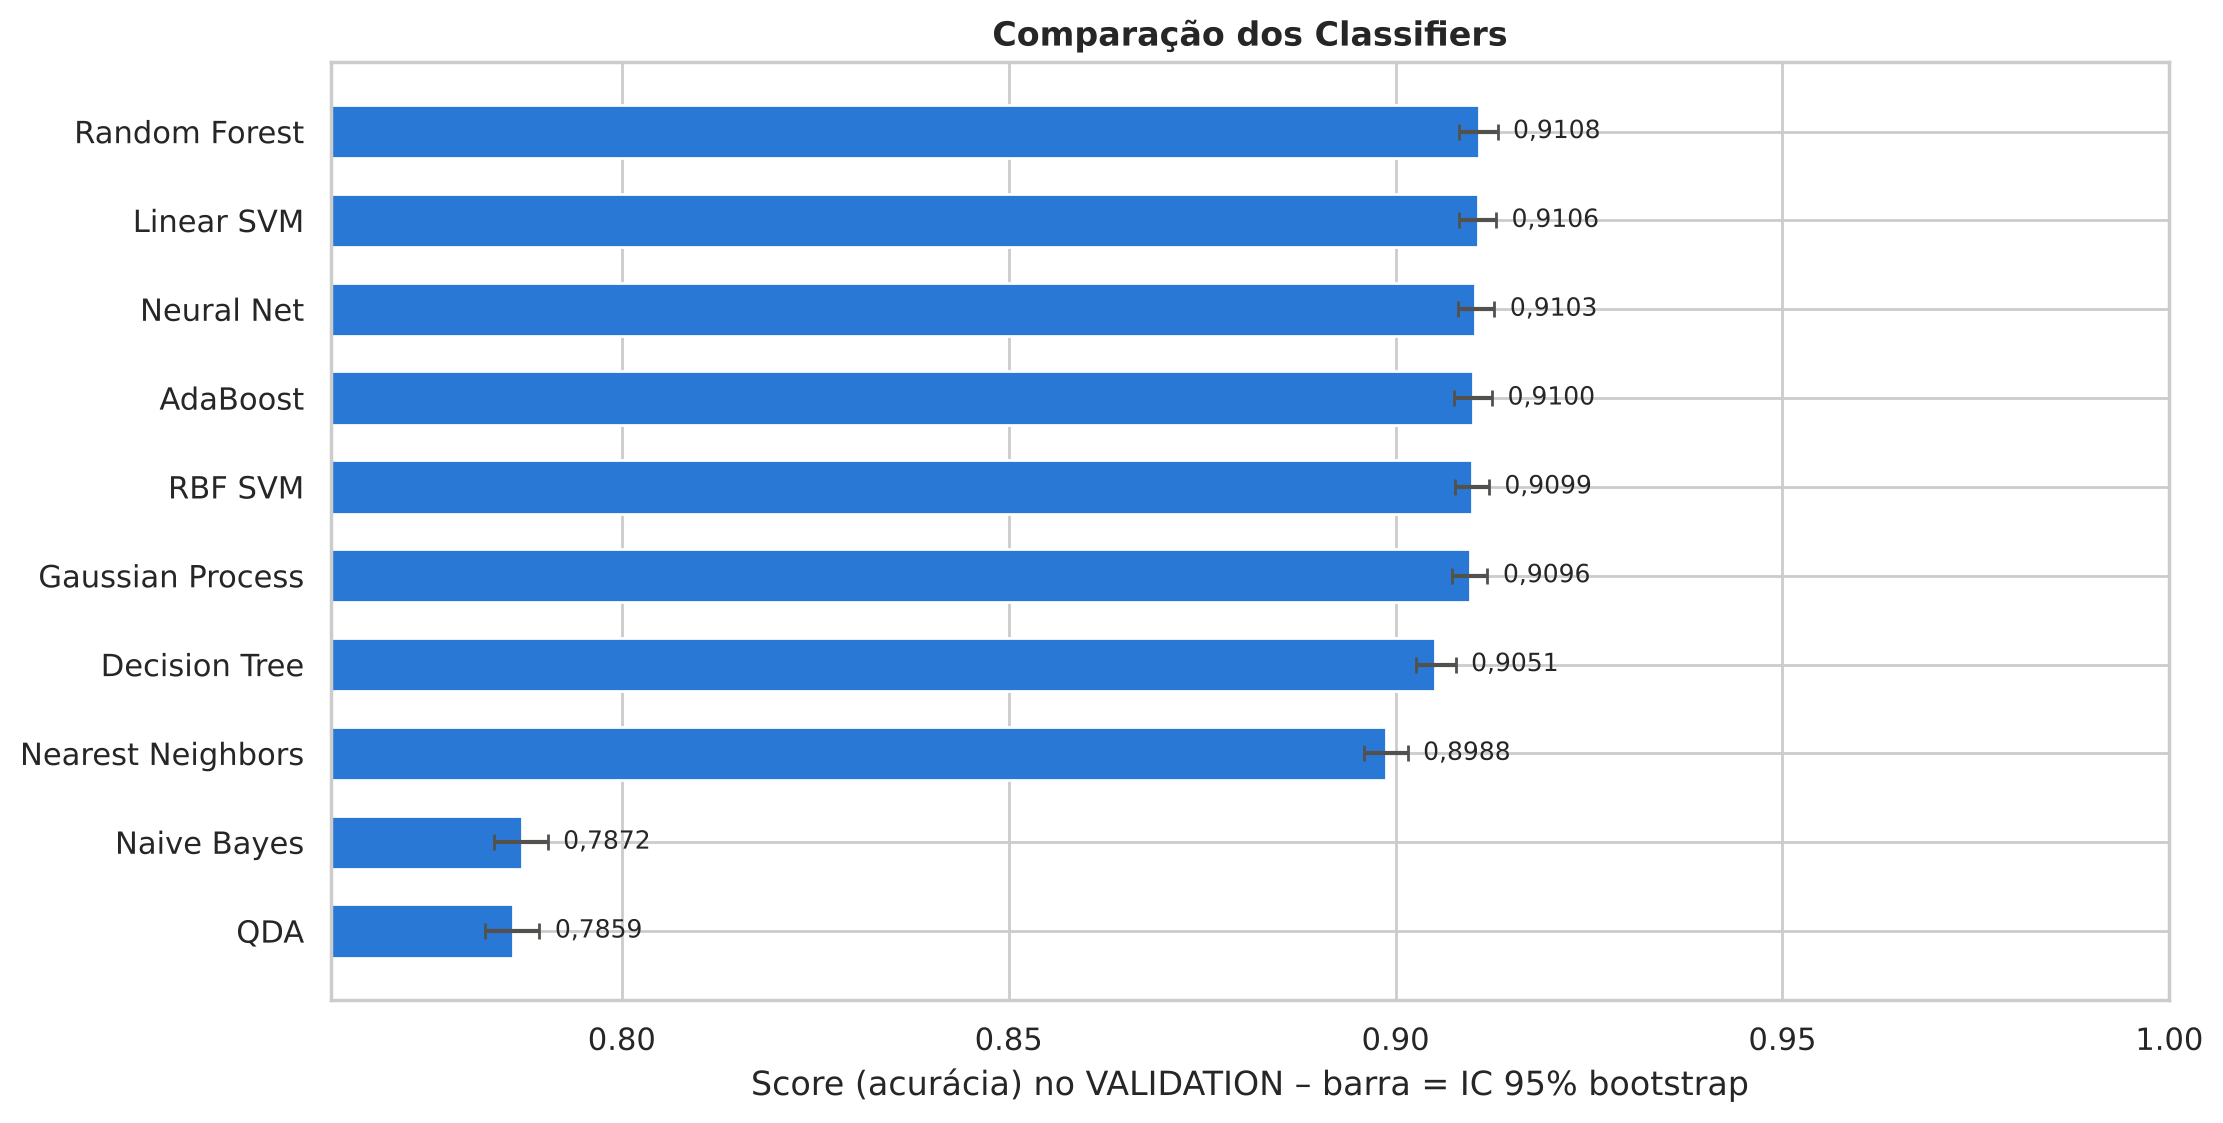

**Maior SCORE: Random Forest**, com acurácia de 0,9108 no VALIDATION (IC 95%: 0,9082 a 0,9132; F1-macro = 0,8849). Pela sobreposição dos IC 95%, 6 modelos estão estatisticamente empatados com ele (Random Forest, Linear SVM, Neural Net, AdaBoost, RBF SVM, Gaussian Process); o pior é o QDA (0,7859). Modelo final: Random Forest re-treinado no TRAIN completo (50.300 notas); acurácia no VALIDATION = 0,9104.

In [ ]:
# =====================================================================
# A3.3 – COMPARAÇÃO DOS 10 CLASSIFIERS DO ENUNCIADO
# Hiperparâmetros: os do exemplo oficial "Classifier comparison" do
# scikit-learn,
# de onde vem a lista do enunciado (mesmos nomes e mesma ordem).
# =====================================================================
# Ajuste do QDA: no TRAIN a NOTA DE SATISFAÇÃO (%) tem variância ZERO na
# classe ESSENTIAL
# (todas as notas = 68,68), o que torna a matriz de covariância singular (o
# QDA padrão
# falha). Usa-se uma regularização mínima (reg_param = 0,01), prevista na
# própria classe.
var_nota = (
    train.groupby(ESTRATO)["NOTA DE SATISFAÇÃO (%)"].var().reindex(CLASSES)
)
display(
    var_nota.rename("Variância da NOTA DE SATISFAÇÃO (%) no TRAIN")
    .to_frame()
    .T.round(4)
)

CLASSIFIERS = {
    "Nearest Neighbors": KNeighborsClassifier(3),
    "Linear SVM": SVC(kernel="linear", C=0.025, random_state=SEED),
    "RBF SVM": SVC(gamma=2, C=1, random_state=SEED),
    "Gaussian Process": GaussianProcessClassifier(
        1.0 * RBF(1.0), random_state=SEED
    ),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        max_depth=5, n_estimators=10, max_features=1, random_state=SEED
    ),
    "Neural Net": MLPClassifier(alpha=1, max_iter=1000, random_state=SEED),
    "AdaBoost": AdaBoostClassifier(random_state=SEED),
    "Naive Bayes": GaussianNB(),
    "QDA": QuadraticDiscriminantAnalysis(reg_param=0.01),
}

# Custo computacional: o Gaussian Process cresce com n³ (50.300³ operações e
# uma matriz
# 50.300 x 50.300 ≈ 20 GB de memória). Para comparar os 10 modelos em
# condições IGUAIS,
# todos são treinados na MESMA subamostra estratificada de 2.000 notas do
# TRAIN e avaliados
# no VALIDATION COMPLETO (50.300 notas). O vencedor é depois re-treinado no
# TRAIN completo.
N_SUB = 2_000
rng = np.random.default_rng(SEED)
n_sub = alocacao_proporcional(
    pd.Series(y_train_clf).value_counts(normalize=True), N_SUB
)
idx_sub = np.concatenate([
    rng.choice(np.where(y_train_clf == c)[0], n_sub[c], replace=False)
    for c in n_sub.index
])

linhas, PREV_VAL = [], {}
for nome, clf in CLASSIFIERS.items():
    t0 = time.time()
    m = clone(clf).fit(X_train_clf[idx_sub], y_train_clf[idx_sub])
    pred = m.predict(X_val_clf)
    PREV_VAL[nome] = pred
    b = bootstrap_metrica(y_val_clf, pred, accuracy_score, n_boot=500)
    linhas.append({
        "Classifier": nome,
        "Score (acurácia) VALIDATION": b["estimativa"],
        "IC95% inf": b["ic_inf"],
        "IC95% sup": b["ic_sup"],
        "F1-macro VALIDATION": f1_score(y_val_clf, pred, average="macro"),
        "Tempo (s)": time.time() - t0,
    })
comp_clf = (
    pd.DataFrame(linhas)
    .set_index("Classifier")
    .sort_values("Score (acurácia) VALIDATION", ascending=False)
)
checar_finitos(comp_clf, "comparação de classificadores")
display(
    Markdown(
        "### Score dos 10 classificadores (treino: subamostra de 2.000 |"
        " avaliação: VALIDATION completo)"
    )
)
display(comp_clf.round(4))

fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
ordem = comp_clf.index[::-1]
v = comp_clf.loc[ordem]
ax.barh(
    ordem,
    v["Score (acurácia) VALIDATION"],
    color="#2a78d6",
    height=0.6,
    xerr=[
        v["Score (acurácia) VALIDATION"] - v["IC95% inf"],
        v["IC95% sup"] - v["Score (acurácia) VALIDATION"],
    ],
    error_kw={"ecolor": "#52514e", "capsize": 3},
)
for j, s in enumerate(v["Score (acurácia) VALIDATION"]):
    ax.text(
        v["IC95% sup"].iloc[j] + 0.002, j, br(s, 4), va="center", fontsize=9
    )
ax.set_xlim(max(0, comp_clf["IC95% inf"].min() - 0.02), 1.0)
ax.set_xlabel("Score (acurácia) no VALIDATION – barra = IC 95% bootstrap")
ax.set_title("Comparação dos Classifiers", fontweight="bold")
plt.show()

NOME_CLF = comp_clf.index[0]
melhor = comp_clf.iloc[0]
empatados = comp_clf.index[
    comp_clf["IC95% sup"] >= melhor["IC95% inf"]
].tolist()
# Modelo final: o vencedor re-treinado no TRAIN completo (exceto o Gaussian
# Process, inviável em 50.300 linhas)
if NOME_CLF == "Gaussian Process":
    MODELO_CLF = clone(CLASSIFIERS[NOME_CLF]).fit(
        X_train_clf[idx_sub], y_train_clf[idx_sub]
    )
    base_treino = (
        "subamostra de 2.000 notas (GP inviável no TRAIN completo)"
    )
else:
    MODELO_CLF = clone(CLASSIFIERS[NOME_CLF]).fit(X_train_clf, y_train_clf)
    base_treino = f"TRAIN completo ({br(len(y_train_clf), 0)} notas)"
acc_val_final = accuracy_score(y_val_clf, MODELO_CLF.predict(X_val_clf))
RESULTADOS["A3_comparacao"] = comp_clf
RESULTADOS["A3_modelo"] = {
    "nome": NOME_CLF,
    "empatados": empatados,
    "base": base_treino,
    "acc_val_final": acc_val_final,
}
display(
    Markdown(
        f"**Maior SCORE: {NOME_CLF}**, com acurácia de"
        f" {br(melhor['Score (acurácia) VALIDATION'], 4)} no VALIDATION (IC"
        f" 95%: {br(melhor['IC95% inf'], 4)} a"
        f" {br(melhor['IC95% sup'], 4)}; F1-macro ="
        f" {br(melhor['F1-macro VALIDATION'], 4)}). Pela sobreposição dos"
        f" IC 95%, {len(empatados)} modelos estão estatisticamente"
        f" empatados com ele ({', '.join(empatados)}); o pior é o"
        f" {comp_clf.index[-1]}"
        f" ({br(comp_clf.iloc[-1]['Score (acurácia) VALIDATION'], 4)})."
        f" Modelo final: {NOME_CLF} re-treinado no {base_treino}; acurácia"
        f" no VALIDATION = {br(acc_val_final, 4)}."
    )
)

### A3.3.1: Intervalo de confiança: Train

Fold,1,2,3,4,5,6,7,8,9,10
Acurácia,0.907,0.9034,0.9052,0.9074,0.9103,0.902,0.9022,0.9123,0.9191,0.9177


,Acurácia,IC95% inf,IC95% sup,EP
Procedimento,,,,
Validação cruzada estratificada (10 folds) – média bootstrap,0.9086,0.9052,0.9121,0.0018
Bootstrap das linhas do TRAIN,0.9096,0.9071,0.9122,0.0013


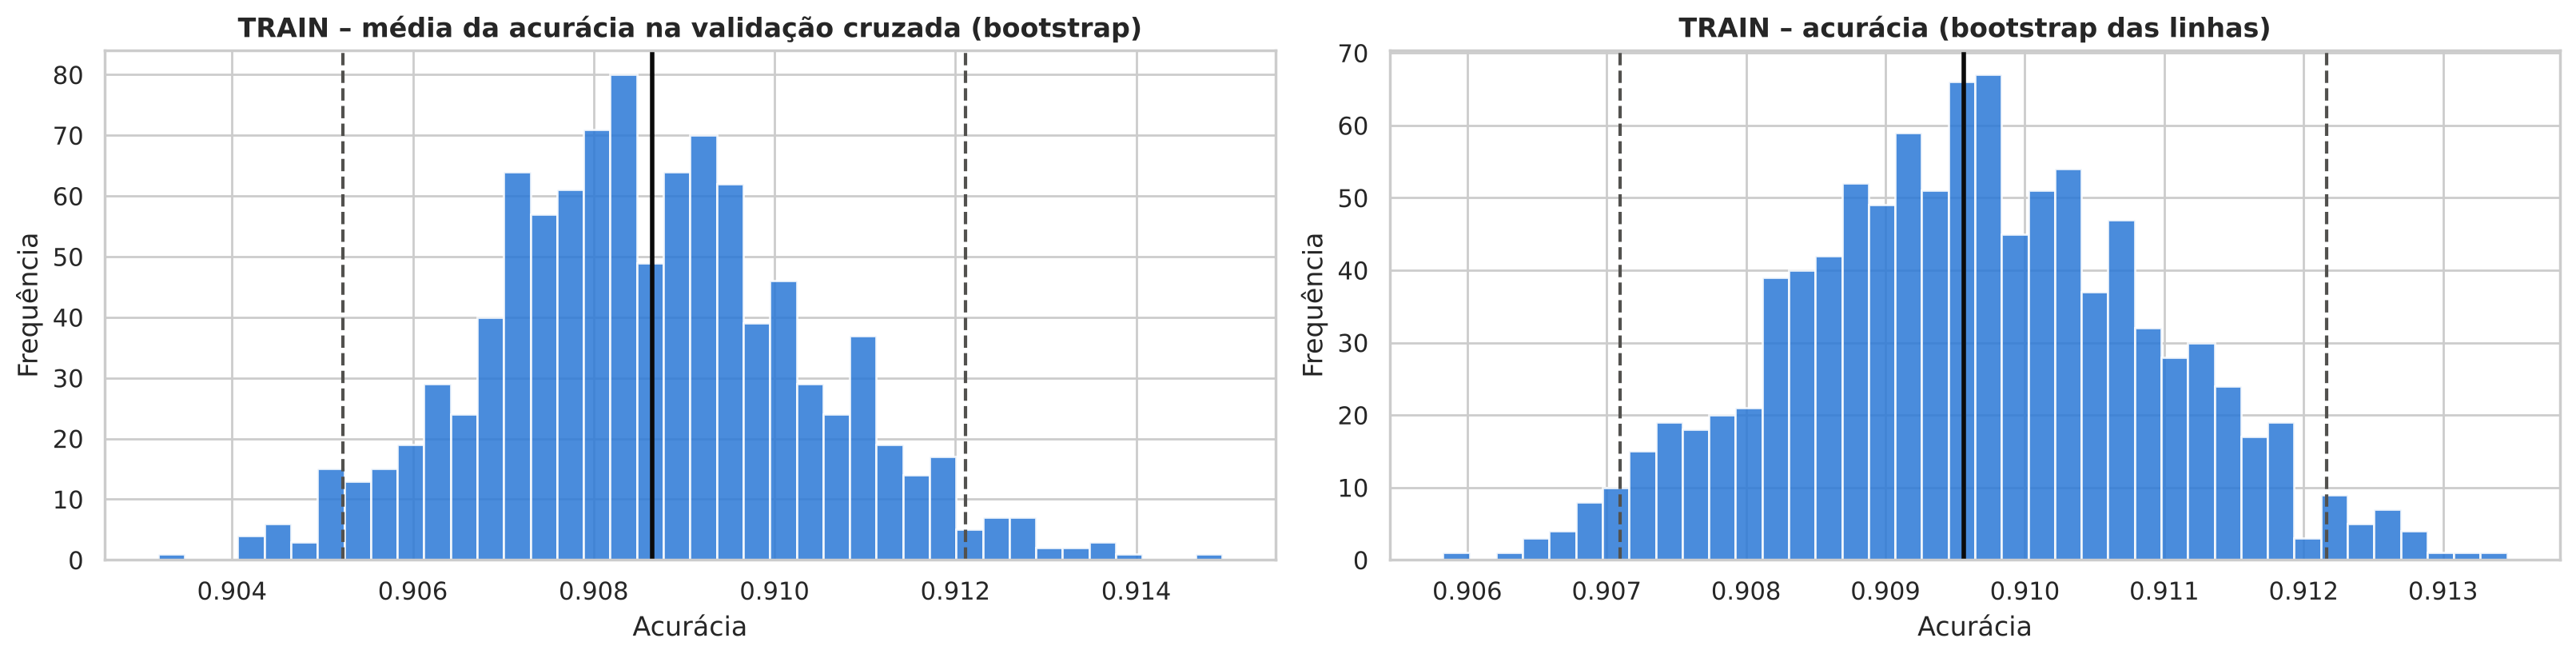

**IC 95% da acurácia no TRAIN (Random Forest):** validação cruzada 0,9086 [0,9052; 0,9121]; bootstrap 0,9096 [0,9071; 0,9122]. Os folds variam de 0,9020 a 0,9191.

In [ ]:
# Validação Cruzada e Análise Bootstrapping – TRAIN
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
if NOME_CLF == "Gaussian Process":
    Xcv, ycv = X_train_clf[idx_sub], y_train_clf[idx_sub]
else:
    Xcv, ycv = X_train_clf, y_train_clf
cv_train_clf = cross_val_score(
    clone(CLASSIFIERS[NOME_CLF]),
    Xcv,
    ycv,
    cv=skf,
    scoring="accuracy",
    n_jobs=-1,
)
boot_cv_train_clf = bootstrap_media(cv_train_clf)
boot_acc_train = bootstrap_metrica(
    y_train_clf, MODELO_CLF.predict(X_train_clf), accuracy_score
)

display(
    pd.DataFrame({"Fold": range(1, K_FOLDS + 1), "Acurácia": cv_train_clf})
    .set_index("Fold")
    .T.round(4)
)
ic_train_clf = pd.DataFrame([
    {
        "Procedimento": (
            "Validação cruzada estratificada (10 folds) – média bootstrap"
        ),
        "Acurácia": boot_cv_train_clf["estimativa"],
        "IC95% inf": boot_cv_train_clf["ic_inf"],
        "IC95% sup": boot_cv_train_clf["ic_sup"],
        "EP": boot_cv_train_clf["ep"],
    },
    {
        "Procedimento": "Bootstrap das linhas do TRAIN",
        "Acurácia": boot_acc_train["estimativa"],
        "IC95% inf": boot_acc_train["ic_inf"],
        "IC95% sup": boot_acc_train["ic_sup"],
        "EP": boot_acc_train["ep"],
    },
]).set_index("Procedimento")
checar_finitos(ic_train_clf, "IC train clf")
display(ic_train_clf.round(4))
fig, axes = plt.subplots(1, 2, figsize=(16, 4), layout="constrained")
plot_bootstrap(
    boot_cv_train_clf,
    "TRAIN – média da acurácia na validação cruzada (bootstrap)",
    "Acurácia",
    ax=axes[0],
)
plot_bootstrap(
    boot_acc_train,
    "TRAIN – acurácia (bootstrap das linhas)",
    "Acurácia",
    ax=axes[1],
)
plt.show()
RESULTADOS["A3_ic_train"] = ic_train_clf
display(
    Markdown(
        f"**IC 95% da acurácia no TRAIN ({NOME_CLF}):** validação cruzada"
        f" {br(boot_cv_train_clf['estimativa'], 4)}"
        f" [{br(boot_cv_train_clf['ic_inf'], 4)};"
        f" {br(boot_cv_train_clf['ic_sup'], 4)}]; bootstrap"
        f" {br(boot_acc_train['estimativa'], 4)}"
        f" [{br(boot_acc_train['ic_inf'], 4)};"
        f" {br(boot_acc_train['ic_sup'], 4)}]. Os folds variam de"
        f" {br(cv_train_clf.min(), 4)} a {br(cv_train_clf.max(), 4)}."
    )
)

### A3.3.2: Intervalo de confiança: Validation

Partição,1,2,3,4,5,6,7,8,9,10
Acurácia,0.9089,0.9083,0.906,0.9139,0.9087,0.9107,0.9109,0.9107,0.9125,0.9129


,Acurácia,IC95% inf,IC95% sup,EP
Procedimento,,,,
10 partições estratificadas do VALIDATION – média bootstrap,0.9104,0.9089,0.9118,0.0007
Bootstrap das linhas do VALIDATION,0.9104,0.9077,0.9128,0.0012


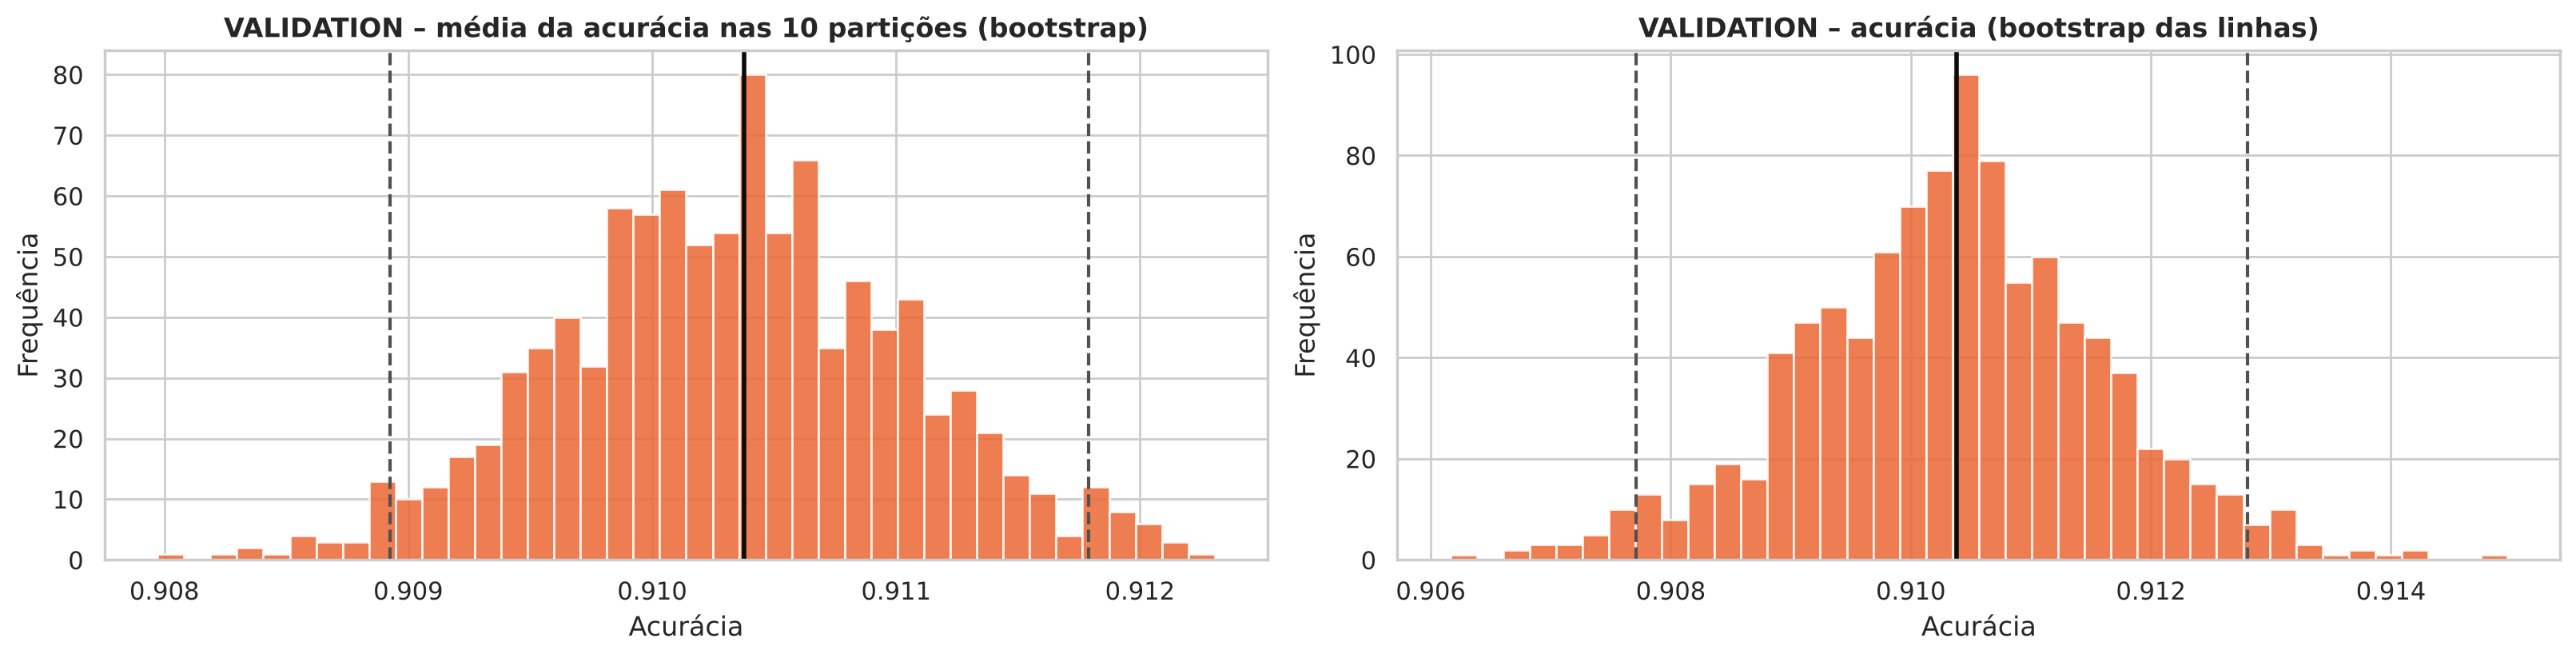

**IC 95% da acurácia no VALIDATION:** 0,9104 [0,9077; 0,9128]. Os intervalos do TRAIN e do VALIDATION **se sobrepõem**: não há sinal de sobreajuste.

In [ ]:
# Validação Cruzada e Análise Bootstrapping – VALIDATION (modelo fixo,
# ajustado no TRAIN)
pred_val_clf = MODELO_CLF.predict(X_val_clf)
cv_val_clf = np.array([
    accuracy_score(y_val_clf[i], pred_val_clf[i])
    for _, i in skf.split(X_val_clf, y_val_clf)
])
boot_cv_val_clf = bootstrap_media(cv_val_clf)
boot_acc_val = bootstrap_metrica(y_val_clf, pred_val_clf, accuracy_score)

display(
    pd.DataFrame(
        {"Partição": range(1, K_FOLDS + 1), "Acurácia": cv_val_clf}
    )
    .set_index("Partição")
    .T.round(4)
)
ic_val_clf = pd.DataFrame([
    {
        "Procedimento": (
            "10 partições estratificadas do VALIDATION – média bootstrap"
        ),
        "Acurácia": boot_cv_val_clf["estimativa"],
        "IC95% inf": boot_cv_val_clf["ic_inf"],
        "IC95% sup": boot_cv_val_clf["ic_sup"],
        "EP": boot_cv_val_clf["ep"],
    },
    {
        "Procedimento": "Bootstrap das linhas do VALIDATION",
        "Acurácia": boot_acc_val["estimativa"],
        "IC95% inf": boot_acc_val["ic_inf"],
        "IC95% sup": boot_acc_val["ic_sup"],
        "EP": boot_acc_val["ep"],
    },
]).set_index("Procedimento")
checar_finitos(ic_val_clf, "IC val clf")
display(ic_val_clf.round(4))
fig, axes = plt.subplots(1, 2, figsize=(16, 4), layout="constrained")
plot_bootstrap(
    boot_cv_val_clf,
    "VALIDATION – média da acurácia nas 10 partições (bootstrap)",
    "Acurácia",
    cor="#eb6834",
    ax=axes[0],
)
plot_bootstrap(
    boot_acc_val,
    "VALIDATION – acurácia (bootstrap das linhas)",
    "Acurácia",
    cor="#eb6834",
    ax=axes[1],
)
plt.show()
delta_pp = (boot_acc_val["estimativa"] - boot_acc_train["estimativa"]) * 100
sobrepoe = (boot_acc_val["ic_inf"] <= boot_acc_train["ic_sup"]) and (
    boot_acc_train["ic_inf"] <= boot_acc_val["ic_sup"]
)
RESULTADOS["A3_ic_val"] = ic_val_clf
display(
    Markdown(
        "**IC 95% da acurácia no VALIDATION:**"
        f" {br(boot_acc_val['estimativa'], 4)}"
        f" [{br(boot_acc_val['ic_inf'], 4)};"
        f" {br(boot_acc_val['ic_sup'], 4)}]. "
        + (
            "Os intervalos do TRAIN e do VALIDATION **se sobrepõem**: não"
            " há sinal de sobreajuste."
            if sobrepoe
            else (
                "Os intervalos não se sobrepõem: a acurácia muda"
                f" {br(delta_pp, 2)} p.p. do TRAIN para o VALIDATION."
            )
        )
    )
)

##Atividade A3.4 (4º Passo): Medir a acurácia (score) dos Modelos de Classificação:

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TRAIN

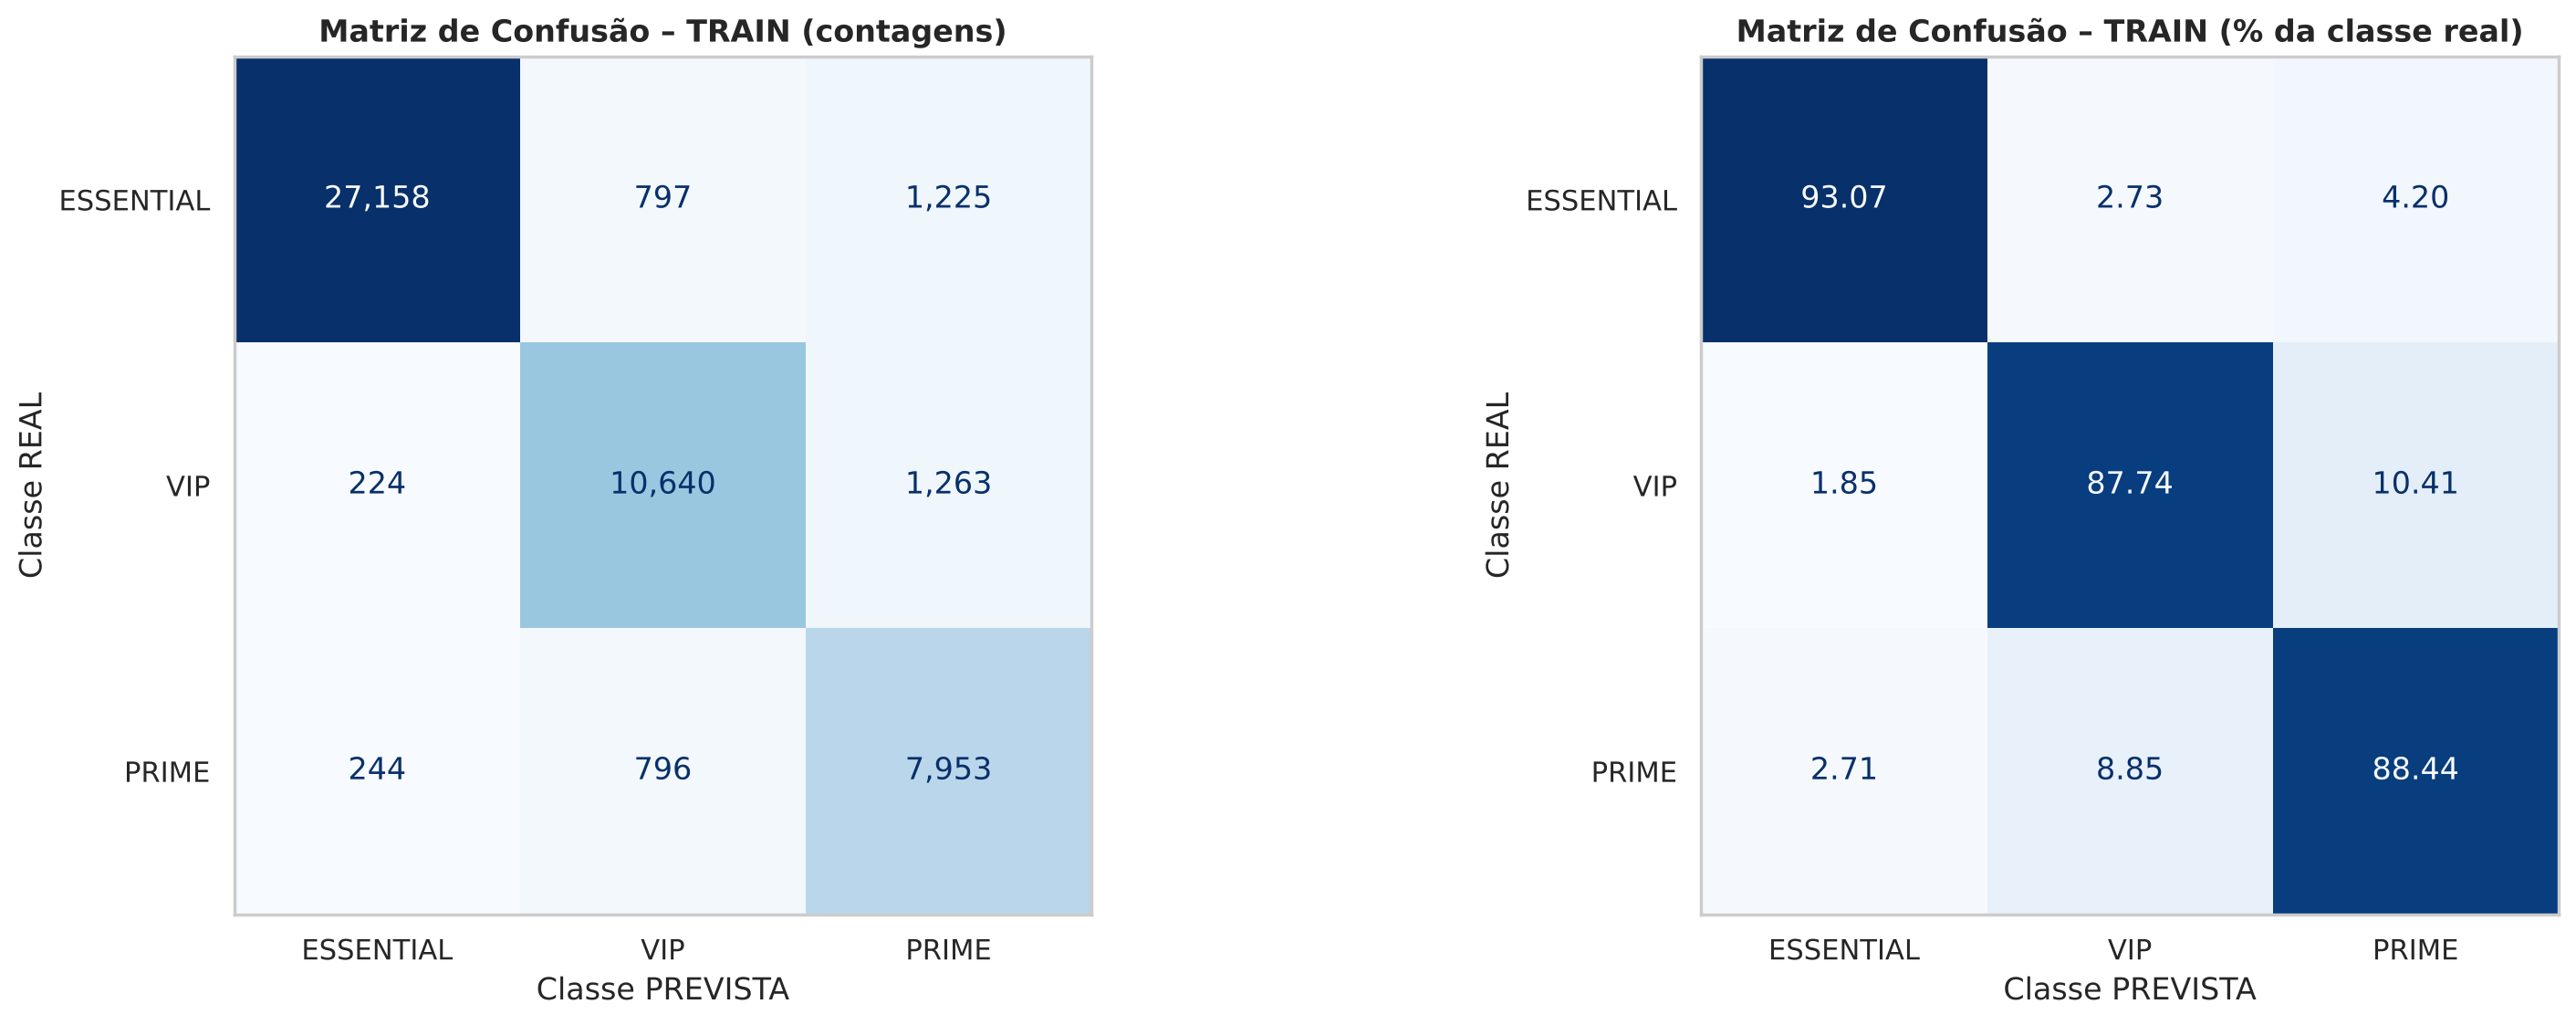

,Precisão,Recall (sensibilidade),F1,n
ESSENTIAL,0.9831,0.9307,0.9562,29180.0000
VIP,0.8698,0.8774,0.8736,12127.0000
PRIME,0.7617,0.8844,0.8185,8993.0000
accuracy,0.9096,0.9096,0.9096,0.9096
macro avg,0.8715,0.8975,0.8827,50300.0000
weighted avg,0.9162,0.9096,0.9116,50300.0000


**TRAIN:** acurácia = 0,9096 | F1-macro = 0,8827. Recall por classe: ESSENTIAL 93,07% | VIP 87,74% | PRIME 88,44%. Classe com mais erros: **VIP**.

In [ ]:
def avaliar_classificacao(y, pred, nome):
    """Matriz de confusão (contagens e % por linha) + métricas por classe."""
    cm = confusion_matrix(y, pred, labels=range(len(CLASSES)))
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), layout="constrained")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=axes[0], cmap="Blues", values_format=",d", colorbar=False
    )
    axes[0].set_title(
        f"Matriz de Confusão – {nome} (contagens)", fontweight="bold"
    )
    cmn = cm / cm.sum(axis=1, keepdims=True) * 100
    ConfusionMatrixDisplay(cmn, display_labels=CLASSES).plot(
        ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False
    )
    axes[1].set_title(
        f"Matriz de Confusão – {nome} (% da classe real)", fontweight="bold"
    )
    for ax in axes:
        ax.set_xlabel("Classe PREVISTA")
        ax.set_ylabel("Classe REAL")
        ax.grid(False)
    plt.show()
    rel = pd.DataFrame(
        classification_report(
            y, pred, target_names=CLASSES, output_dict=True
        )
    ).T
    rel = rel.rename(
        columns={
            "precision": "Precisão",
            "recall": "Recall (sensibilidade)",
            "f1-score": "F1",
            "support": "n",
        }
    )
    display(rel.round(4))
    acc = accuracy_score(y, pred)
    checar_finitos(rel, f"relatório {nome}")
    pior = rel.loc[CLASSES, "Recall (sensibilidade)"].idxmin()
    display(
        Markdown(
            f"**{nome}:** acurácia = {br(acc, 4)} | F1-macro ="
            f" {br(rel.loc['macro avg', 'F1'], 4)}. Recall por classe: "
            + " | ".join(
                f"{c} {br(rel.loc[c, 'Recall (sensibilidade)'] * 100, 2)}%"
                for c in CLASSES
            )
            + f". Classe com mais erros: **{pior}**."
        )
    )
    return {"acc": acc, "cm": cm, "rel": rel}


aval_train = avaliar_classificacao(
    y_train_clf, MODELO_CLF.predict(X_train_clf), "TRAIN"
)

####Atividade A3.4.2: Medir a acurácia (score) - Matriz de Confusão: Conjunto VALIDATION

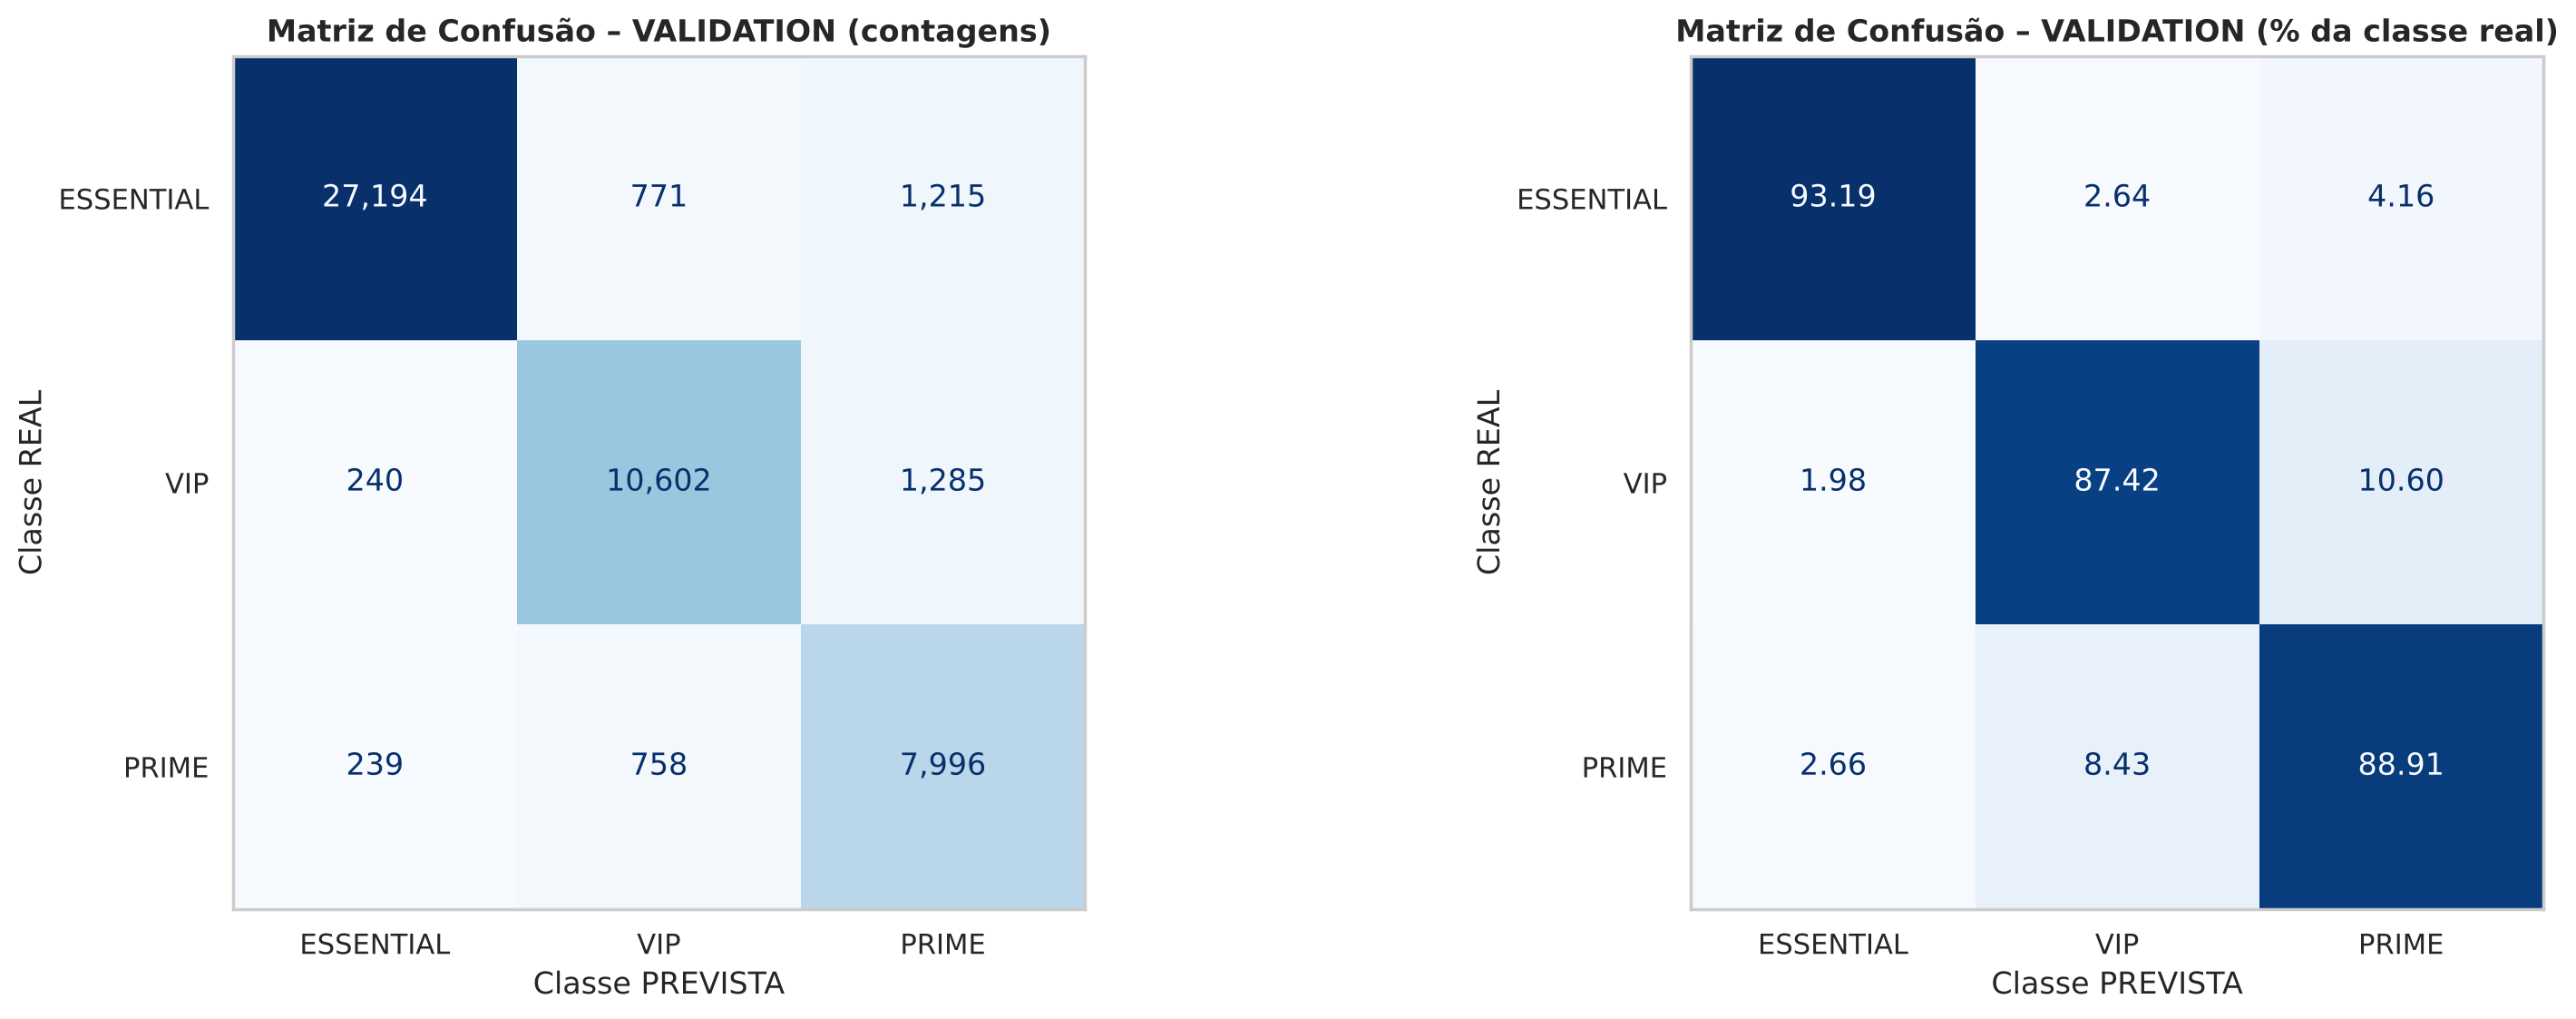

,Precisão,Recall (sensibilidade),F1,n
ESSENTIAL,0.9827,0.9319,0.9566,29180.0000
VIP,0.8740,0.8742,0.8741,12127.0000
PRIME,0.7618,0.8891,0.8206,8993.0000
accuracy,0.9104,0.9104,0.9104,0.9104
macro avg,0.8728,0.8984,0.8838,50300.0000
weighted avg,0.9170,0.9104,0.9124,50300.0000


**VALIDATION:** acurácia = 0,9104 | F1-macro = 0,8838. Recall por classe: ESSENTIAL 93,19% | VIP 87,42% | PRIME 88,91%. Classe com mais erros: **VIP**.

In [ ]:
aval_val = avaliar_classificacao(y_val_clf, pred_val_clf, "VALIDATION")

####Atividade A3.4.1: Medir a acurácia (score) - Matriz de Confusão: Conjunto TEST

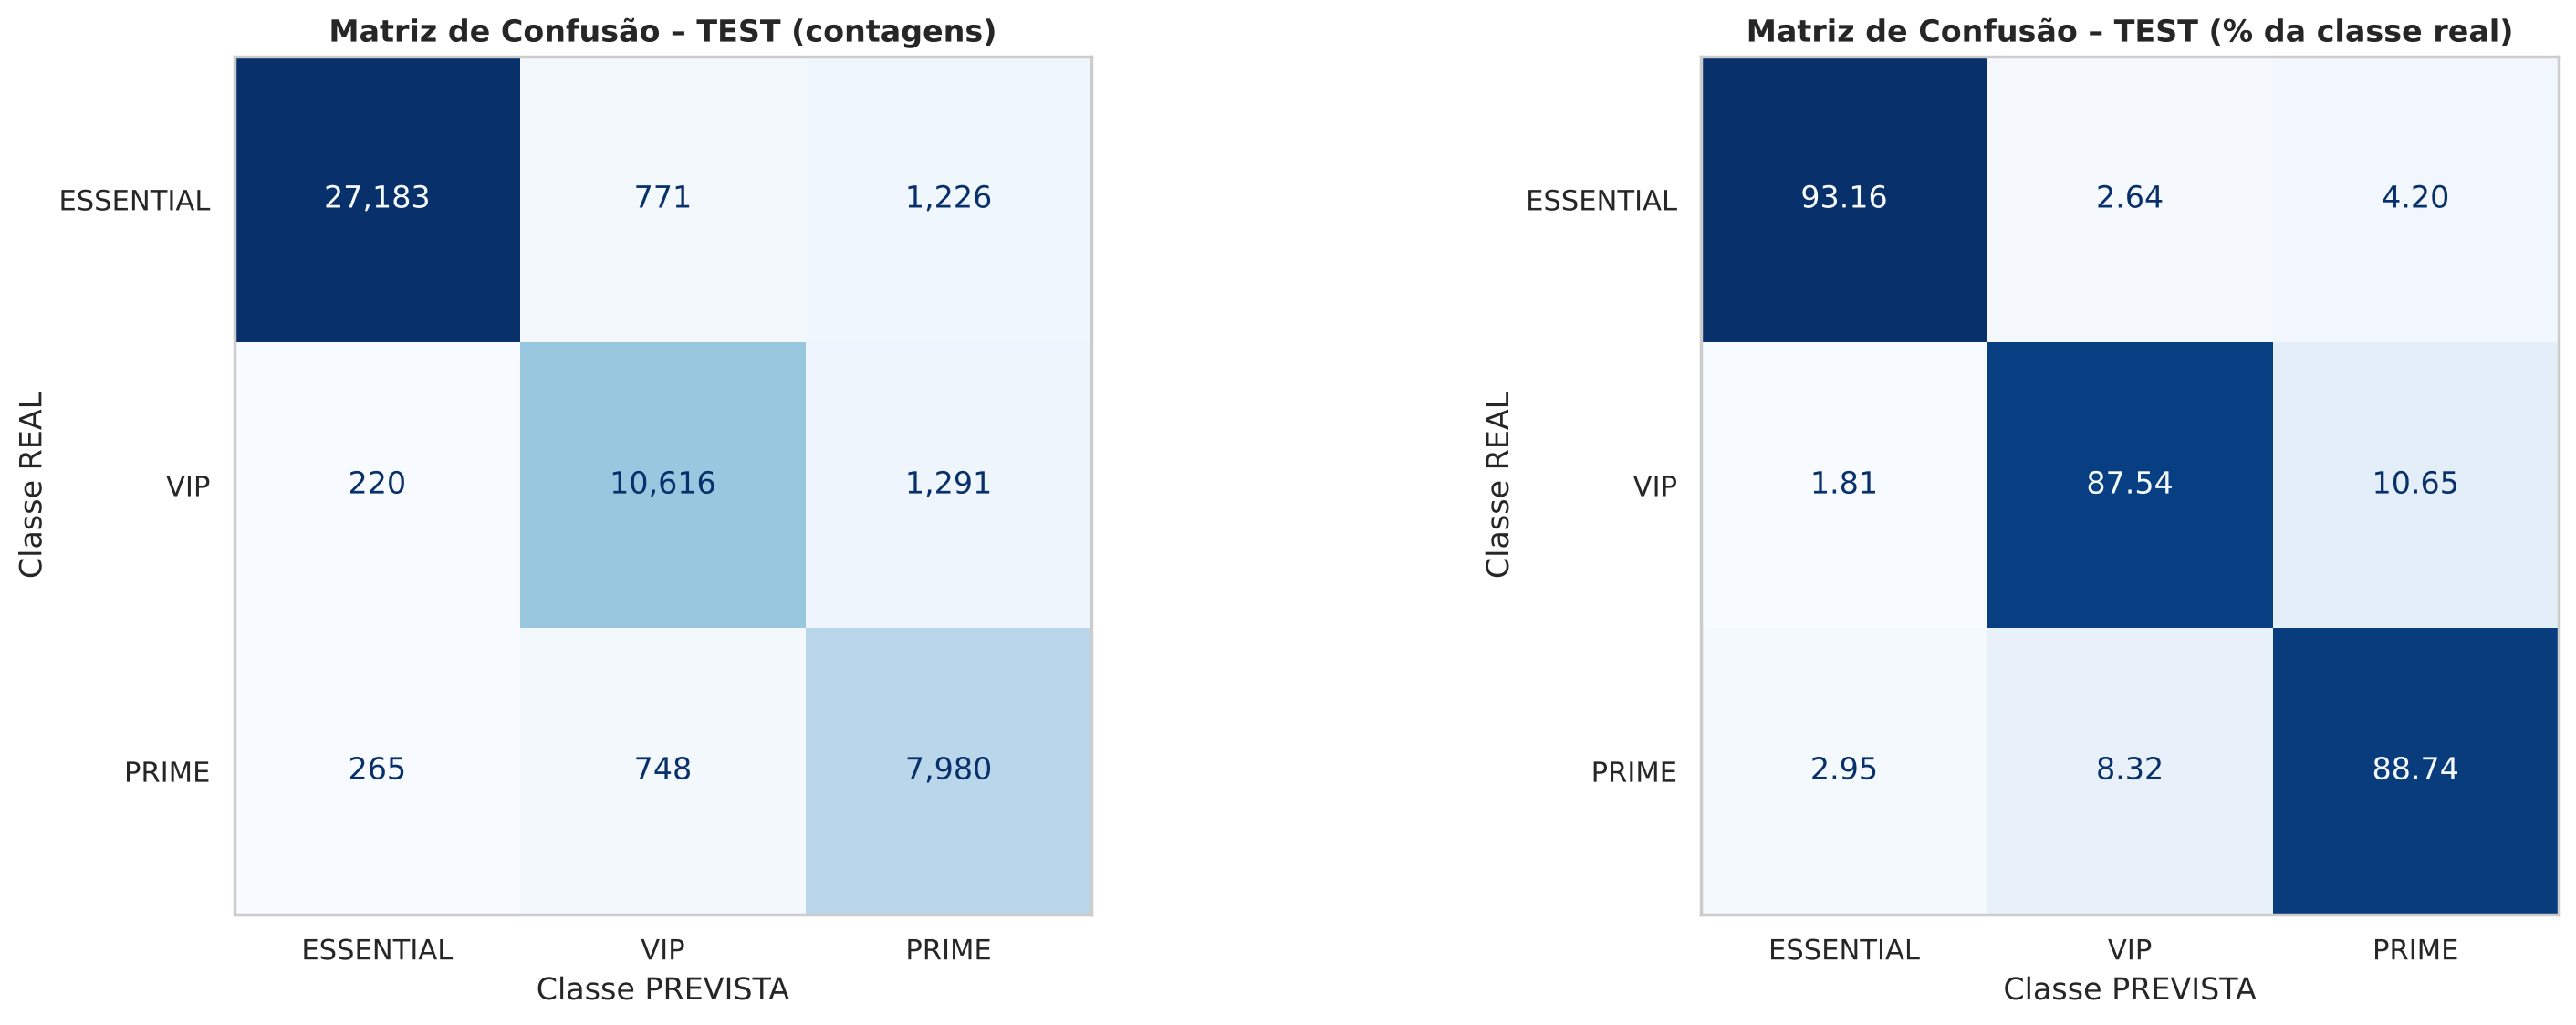

,Precisão,Recall (sensibilidade),F1,n
ESSENTIAL,0.9825,0.9316,0.9563,29180.0000
VIP,0.8748,0.8754,0.8751,12127.0000
PRIME,0.7602,0.8874,0.8189,8993.0000
accuracy,0.9101,0.9101,0.9101,0.9101
macro avg,0.8725,0.8981,0.8834,50300.0000
weighted avg,0.9168,0.9101,0.9122,50300.0000


**TEST:** acurácia = 0,9101 | F1-macro = 0,8834. Recall por classe: ESSENTIAL 93,16% | VIP 87,54% | PRIME 88,74%. Classe com mais erros: **VIP**.

### Resumo – TRAIN x VALIDATION x TEST

,Acurácia,F1-macro,Recall ESSENTIAL,Recall VIP,Recall PRIME
TRAIN,0.9096,0.8827,0.9307,0.8774,0.8844
VALIDATION,0.9104,0.8838,0.9319,0.8742,0.8891
TEST,0.9101,0.8834,0.9316,0.8754,0.8874


### Mediana da RENDA BRUTO (R$) dos acertos e dos erros por classe real (TEST)

Acertou?,Acertou,Errou
Classe real,,
ESSENTIAL,3250.21,12478.69
VIP,7748.22,14680.20
PRIME,21200.34,6055.67


**De onde vêm os erros:** os clientes ESSENTIAL classificados errado têm renda mediana de R$ 12.478,69 (contra R$ 3.250,21 dos acertos), e os PRIME classificados errado têm renda mediana de R$ 6.055,67 (contra R$ 21.200,35). Ou seja, os erros vêm de clientes cuja renda **não corresponde** ao tipo de conta que possuem. O modelo aprendeu a regra "renda alta → conta superior"; esses casos de exceção não são previsíveis com os dados disponíveis e, para o negócio, indicam clientes ESSENTIAL com perfil de VIP/PRIME (oportunidade de *upgrade*).

In [ ]:
pred_test_clf = MODELO_CLF.predict(X_test_clf)
aval_test = avaliar_classificacao(y_test_clf, pred_test_clf, "TEST")
resumo_clf = pd.DataFrame({
    k: {
        "Acurácia": a["acc"],
        "F1-macro": a["rel"].loc["macro avg", "F1"],
        **{
            f"Recall {c}": a["rel"].loc[c, "Recall (sensibilidade)"]
            for c in CLASSES
        },
    }
    for k, a in [
        ("TRAIN", aval_train),
        ("VALIDATION", aval_val),
        ("TEST", aval_test),
    ]
}).T
checar_finitos(resumo_clf, "resumo classificação")
RESULTADOS["A3_metricas"] = resumo_clf
display(Markdown("### Resumo – TRAIN x VALIDATION x TEST"))
display(resumo_clf.round(4))

# De onde vêm os erros? RENDA dos clientes classificados certo x errado (TEST)
errado = pred_test_clf != y_test_clf
erros = pd.DataFrame({
    "Classe real": test[ESTRATO].to_numpy(),
    "Acertou?": np.where(errado, "Errou", "Acertou"),
    "RENDA BRUTO (R$)": test["RENDA BRUTO (R$)"].to_numpy(),
})
tab_erros = (
    erros.groupby(["Classe real", "Acertou?"])["RENDA BRUTO (R$)"]
    .median()
    .unstack()
    .reindex(CLASSES)
)
display(
    Markdown(
        "### Mediana da RENDA BRUTO (R$) dos acertos e dos erros por classe"
        " real (TEST)"
    )
)
display(tab_erros.round(2))
RESULTADOS["A3_erros"] = tab_erros
display(
    Markdown(
        "**De onde vêm os erros:** os clientes ESSENTIAL classificados"
        " errado têm renda mediana de R$"
        f" {br(tab_erros.loc['ESSENTIAL', 'Errou'], 2)} (contra R$"
        f" {br(tab_erros.loc['ESSENTIAL', 'Acertou'], 2)} dos acertos), e"
        " os PRIME classificados errado têm renda mediana de R$"
        f" {br(tab_erros.loc['PRIME', 'Errou'], 2)} (contra R$"
        f" {br(tab_erros.loc['PRIME', 'Acertou'], 2)}). Ou seja, os erros"
        " vêm de clientes cuja renda **não corresponde** ao tipo de conta"
        ' que possuem. O modelo aprendeu a regra "renda alta → conta'
        ' superior"; esses casos de exceção não são previsíveis com os'
        " dados disponíveis e, para o negócio, indicam clientes ESSENTIAL"
        " com perfil de VIP/PRIME (oportunidade de *upgrade*)."
    )
)

##Atividade A3.5 (5º Passo): Testar o Modelo: Dados da População: amostra aleatória (Sample).

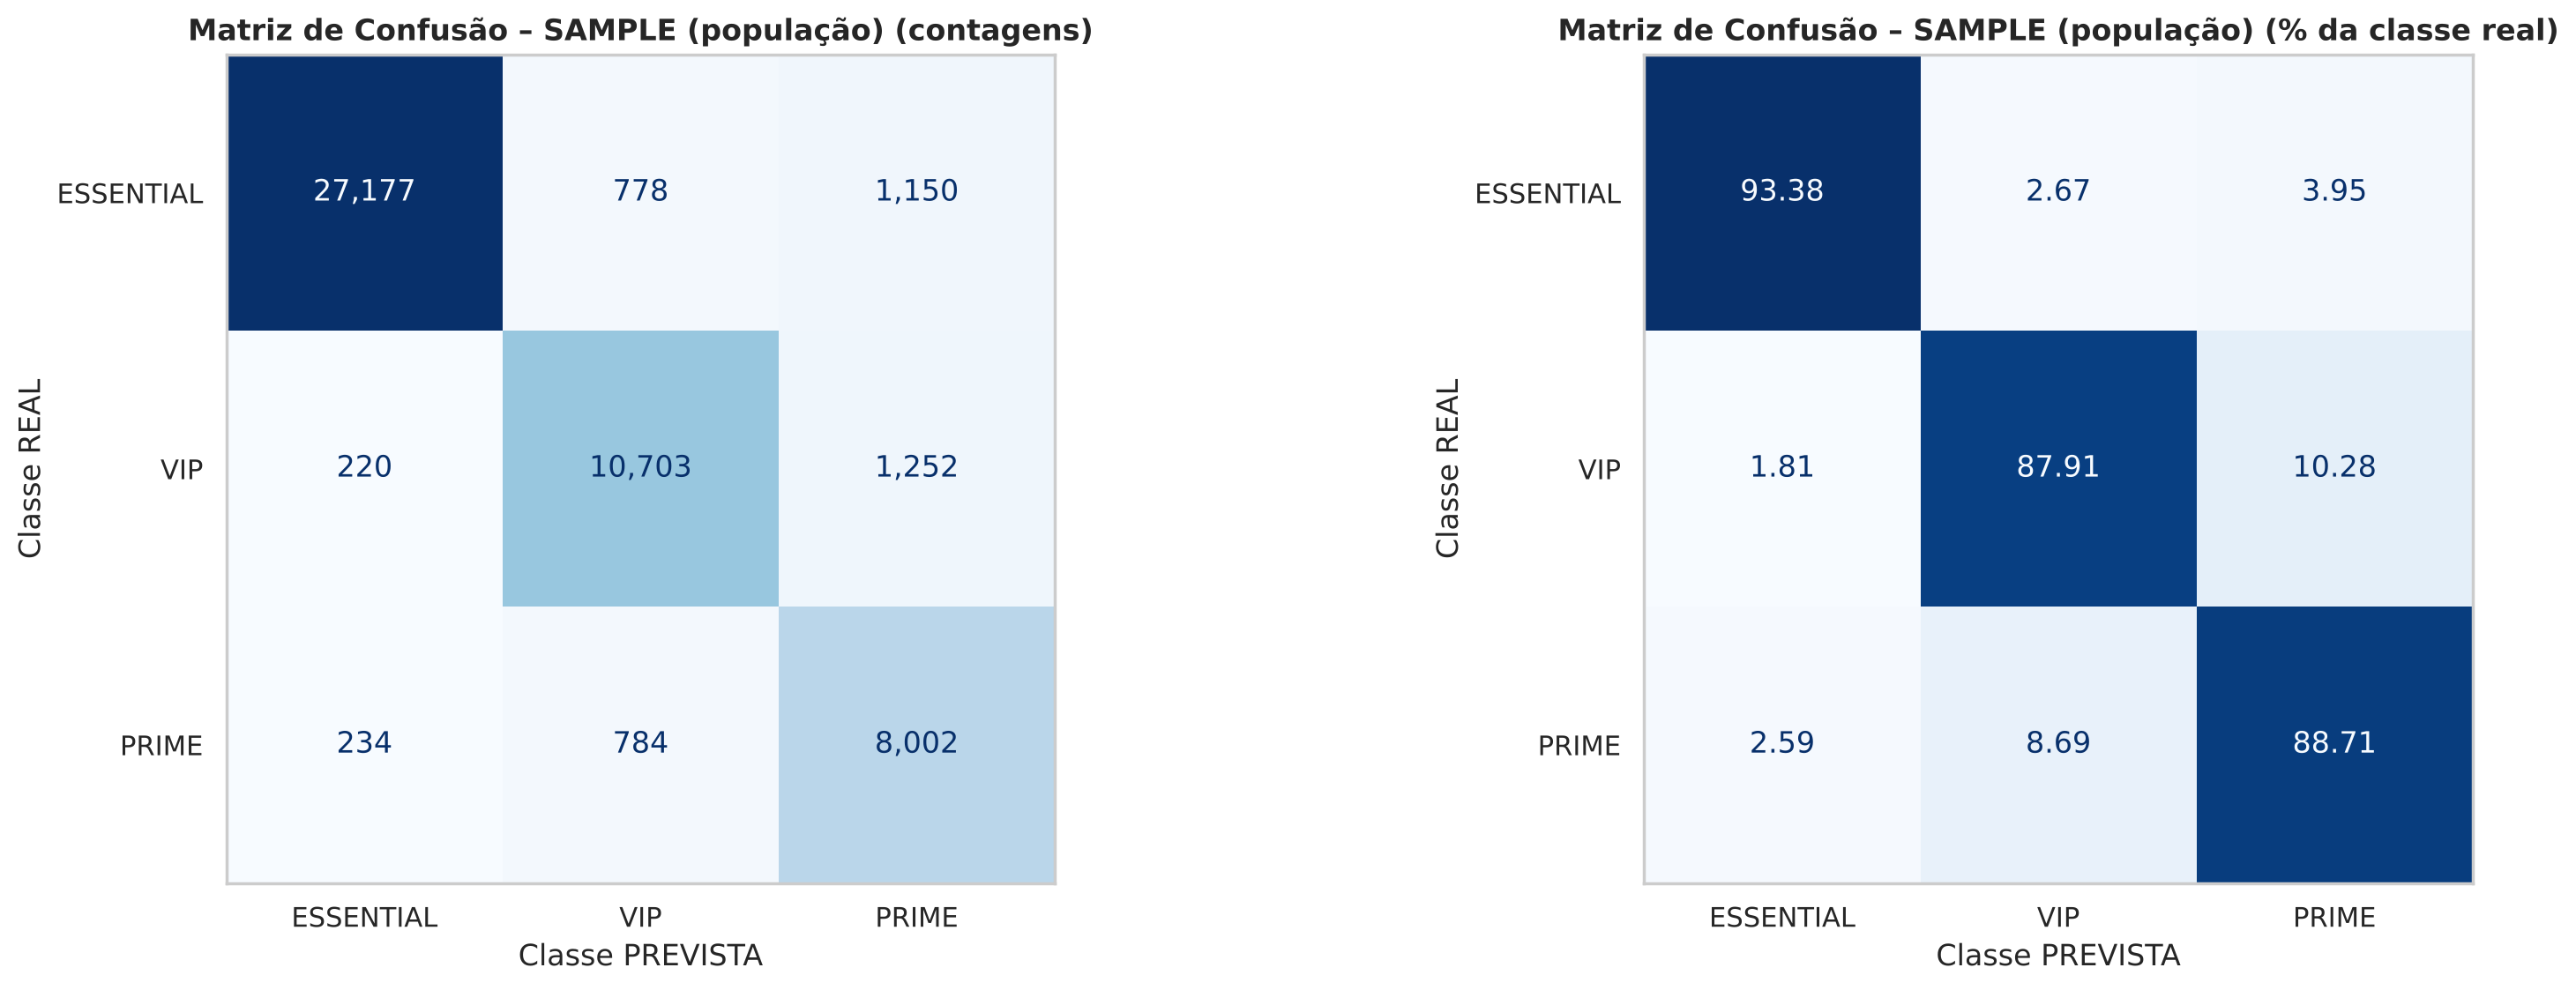

,Precisão,Recall (sensibilidade),F1,n
ESSENTIAL,0.9836,0.9338,0.9580,29105.0000
VIP,0.8726,0.8791,0.8759,12175.0000
PRIME,0.7691,0.8871,0.8239,9020.0000
accuracy,0.9122,0.9122,0.9122,0.9122
macro avg,0.8751,0.9000,0.8859,50300.0000
weighted avg,0.9183,0.9122,0.9141,50300.0000


**SAMPLE (população):** acurácia = 0,9122 | F1-macro = 0,8859. Recall por classe: ESSENTIAL 93,38% | VIP 87,91% | PRIME 88,71%. Classe com mais erros: **VIP**.

### Desempenho do CLASSIFICADOR na amostra da população

,Acurácia,IC95% inf,IC95% sup,F1-macro
TEST,0.9101,0.9077,0.9124,0.8834
SAMPLE (população),0.9122,0.9097,0.9146,0.8859


### Clientes por TIPO DA CONTA – real x previsto (SAMPLE)

,Real,Previsto,Diferença (%)
ESSENTIAL,29105,27631,-5.06
VIP,12175,12265,0.74
PRIME,9020,10404,15.34


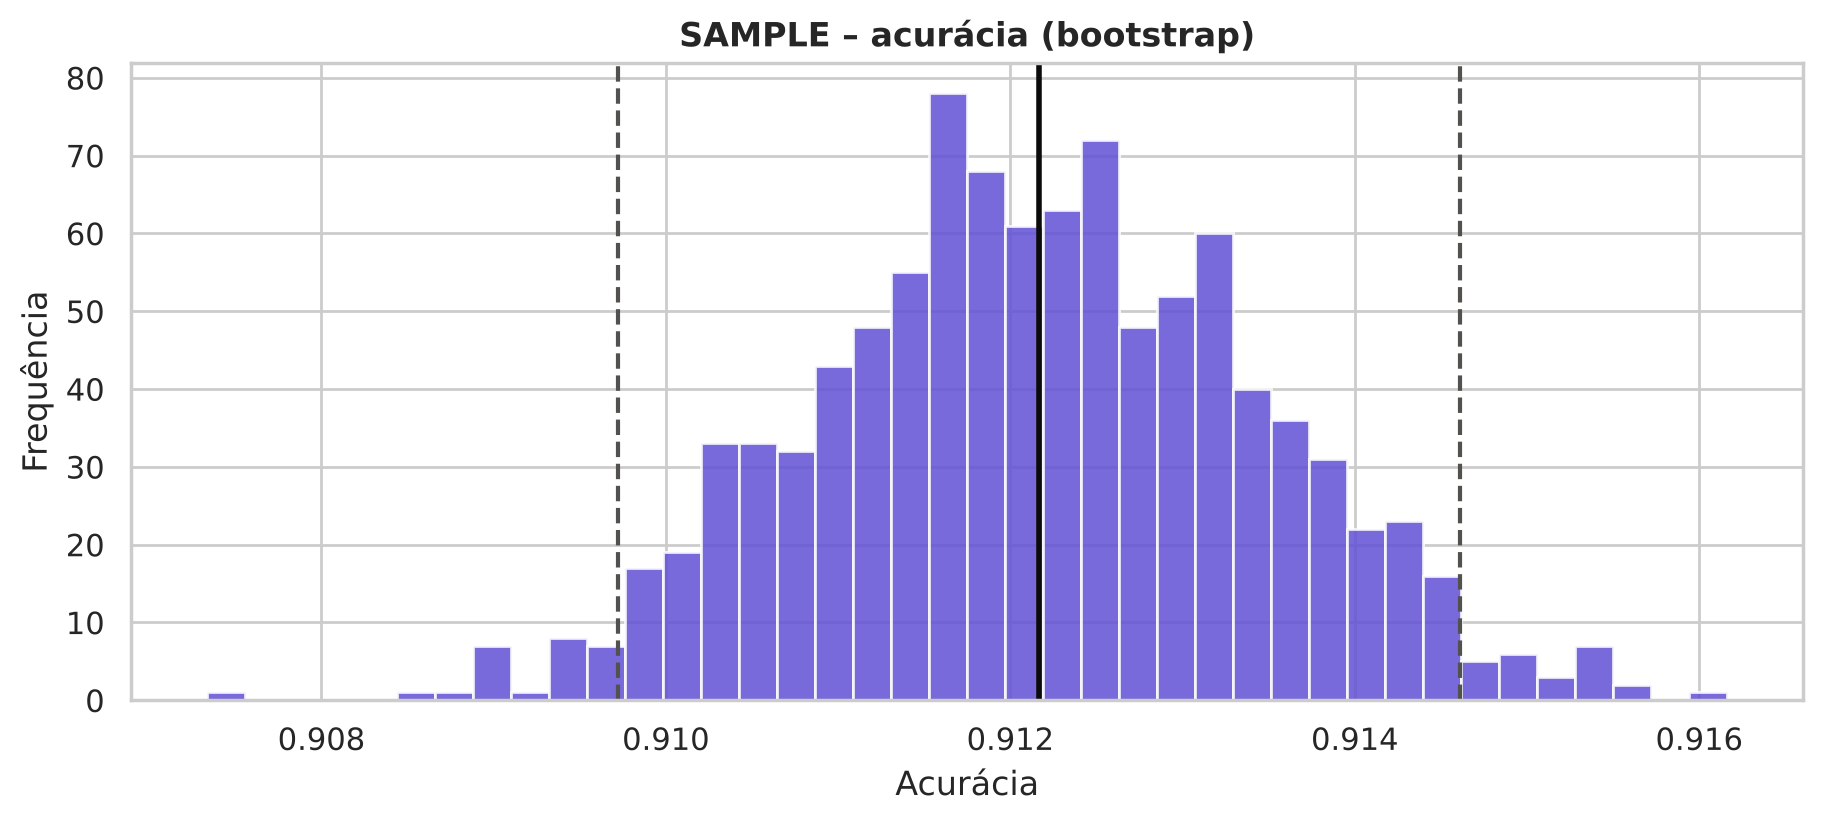

**Conclusão A3.5:** em 50.300 notas novas da população, o Random Forest acertou o tipo de conta em 91,22% dos casos (IC 95%: 90,97% a 91,46%), contra 57,86% de quem chutasse sempre ESSENTIAL. A acurácia do TEST está dentro desse intervalo: o desempenho se mantém na população.

In [ ]:
# =====================================================================
# A3.5 – TESTAR O MODELO NA POPULAÇÃO: SAMPLE
# =====================================================================
pred_sample_clf = MODELO_CLF.predict(X_sample_clf)
aval_sample = avaliar_classificacao(
    y_sample_clf, pred_sample_clf, "SAMPLE (população)"
)
boot_acc_sample = bootstrap_metrica(
    y_sample_clf, pred_sample_clf, accuracy_score
)
boot_acc_test = bootstrap_metrica(y_test_clf, pred_test_clf, accuracy_score)
base_line = (y_sample_clf == COD["ESSENTIAL"]).mean()

comp_s = pd.DataFrame(
    {
        "Acurácia": [
            boot_acc_test["estimativa"],
            boot_acc_sample["estimativa"],
        ],
        "IC95% inf": [boot_acc_test["ic_inf"], boot_acc_sample["ic_inf"]],
        "IC95% sup": [boot_acc_test["ic_sup"], boot_acc_sample["ic_sup"]],
        "F1-macro": [
            aval_test["rel"].loc["macro avg", "F1"],
            aval_sample["rel"].loc["macro avg", "F1"],
        ],
    },
    index=["TEST", "SAMPLE (população)"],
)
# Quantidade prevista x real de clientes por tipo (visão gerencial)
qtd = pd.DataFrame({
    "Real": (
        pd.Series(y_sample_clf).map(dict(enumerate(CLASSES))).value_counts()
    ),
    "Previsto": (
        pd.Series(pred_sample_clf)
        .map(dict(enumerate(CLASSES)))
        .value_counts()
    ),
}).reindex(CLASSES)
qtd["Diferença (%)"] = (qtd["Previsto"] / qtd["Real"] - 1) * 100
checar_finitos(comp_s, "teste população clf")
checar_finitos(qtd, "quantidades")
display(Markdown("### Desempenho do CLASSIFICADOR na amostra da população"))
display(comp_s.round(4))
display(
    Markdown("### Clientes por TIPO DA CONTA – real x previsto (SAMPLE)")
)
display(qtd.round(2))
plot_bootstrap(
    boot_acc_sample,
    "SAMPLE – acurácia (bootstrap)",
    "Acurácia",
    cor=CORES_CONJ["SAMPLE"],
)
plt.show()

RESULTADOS["A3_sample"] = {
    "comp": comp_s,
    "qtd": qtd,
    "baseline": base_line,
    "rel": aval_sample["rel"],
}
ic_cobre = (
    boot_acc_sample["ic_inf"]
    <= boot_acc_test["estimativa"]
    <= boot_acc_sample["ic_sup"]
)
display(
    Markdown(
        f"**Conclusão A3.5:** em {br(len(y_sample_clf), 0)} notas novas da"
        f" população, o {NOME_CLF} acertou o tipo de conta em"
        f" {br(boot_acc_sample['estimativa'] * 100, 2)}% dos casos (IC 95%:"
        f" {br(boot_acc_sample['ic_inf'] * 100, 2)}% a"
        f" {br(boot_acc_sample['ic_sup'] * 100, 2)}%), contra"
        f" {br(base_line * 100, 2)}% de quem chutasse sempre ESSENTIAL. "
        + (
            "A acurácia do TEST está dentro desse intervalo: o desempenho"
            " se mantém na população."
            if ic_cobre
            else (
                "A acurácia do TEST fica fora desse intervalo; ver a"
                " tabela."
            )
        )
    )
)

## RELATÓRIO PARCIAL - MODELO DE CLASSIFICAÇÃO

*    **Objetivo:** prever o TIPO DA CONTA (ESSENTIAL, VIP ou PRIME) de um cliente. Entradas selecionadas no TRAIN: RENDA BRUTO (ε² = 0,6403), TOTAL (ε² = 0,5184) e NOTA DE SATISFAÇÃO (ε² = 0,3414). As demais 18 variáveis não têm associação relevante com o tipo de conta.

*    **Escolha do modelo:** os 10 classificadores do enunciado foram comparados em condições iguais. O **Random Forest** obteve o maior score na validação (0,9108). Ele está estatisticamente empatado com Linear SVM, Neural Net, AdaBoost, RBF SVM e Gaussian Process, e bem acima de Naive Bayes e QDA (≈ 0,79). O QDA precisou de regularização, porque a NOTA DE SATISFAÇÃO é constante na classe ESSENTIAL.

*    **Desempenho:** acurácia de 0,9096 (TRAIN), 0,9104 (VALIDATION) e 0,9101 (TEST), com F1-macro ≈ 0,88 e sem sinal de sobreajuste (IC 95% sobrepostos). Na SAMPLE da população, 91,22% de acerto (IC 95%: 90,97% a 91,46%), bem acima dos 57,86% de quem chutasse sempre ESSENTIAL.

*    **Por classe (TEST):** recall de 93,16% no ESSENTIAL, 87,54% no VIP e 88,74% no PRIME. O PRIME tem a menor precisão (0,7602), por isso o modelo superestima a quantidade de clientes PRIME (+15,34% na SAMPLE) e subestima a de ESSENTIAL (−5,06%).

*    **De onde vêm os erros:** os erros vêm de clientes cuja renda não corresponde ao tipo de conta. Os ESSENTIAL classificados errado têm renda mediana de R$ 12.478,69, contra R$ 3.250,21 dos acertos (TEST). Esses casos não são previsíveis com os dados atuais.

*    **Recomendação aos gestores:** usar o classificador para **sugerir o tipo de conta** de novos clientes e para encontrar os clientes ESSENTIAL que o modelo classifica como VIP/PRIME, que são o público prioritário para ofertas de *upgrade*.

# RELATÓRIO FINAL - VISÃO HOLÍSTICA SOBRE O PROJETO

 **RELATÓRIO FINAL** com todas as conclusões e resultados que serão apresentados aos gestores da **EMPRESA:**.

*    **Da Parte 1 para a Parte 2:** a base foi carregada **completa** (1.120.000 notas, conferência automática no código), o tamanho ideal foi recalculado e confirmado em **n = 50.300**, e o desenho amostral foi documentado: tamanho por Neyman e alocação proporcional por TIPO DA CONTA, com soma exata (29.180 + 12.127 + 8.993 = 50.300). TRAIN, VALIDATION e TEST são disjuntos e representativos: nos 7 testes, não se rejeitou H0. Todos os números deste relatório saem da mesma execução do notebook, e nenhuma saída contém NaN.

*    **O que determina o valor do cliente é a renda.** Nos três modelos, apenas RENDA BRUTO, TOTAL, NOTA DE SATISFAÇÃO e TIPO DA CONTA se mostraram relevantes. Sexo, região, estado civil, dependentes, opinião e as 13 variáveis químicas dos vinhos não têm relação relevante com o gasto nem com o tipo de conta.

*    **Regressão (quanto o cliente gasta):** a Regressão Linear explica cerca de 73% da variação do TOTAL (R² = 0,7338 na amostra da população) e acerta o gasto médio por tipo de conta com erro inferior a 0,3%. Serve para **projetar faturamento**, mas não para prever uma compra isolada (MAE ≈ R$ 289, erro maior nos clientes de gasto alto).

*    **Clusterização (quem são os clientes):** o K-Means (k = 3) encontrou três segmentos estáveis de valor: baixo (≈ 56% das notas), médio (≈ 25%) e alto (≈ 19%). Esses segmentos reproduzem os tipos de conta (ARI = 0,7802) sem conhecê-los. O segmento de alto valor gera **50,63% do faturamento** com 18,68% das notas.

*    **Classificação (qual conta o cliente deveria ter):** o Random Forest acerta o tipo de conta em 91,22% dos casos na amostra da população. Os erros vêm de clientes cuja renda não corresponde à conta que possuem.

*    **Recomendações aos gestores da UVVine:** (1) usar o regressor para projetar o faturamento diário (≈ 5.000 notas por dia); (2) priorizar retenção e relacionamento no segmento de alto valor; (3) usar o classificador e os clusters para identificar clientes ESSENTIAL com perfil VIP/PRIME e oferecer *upgrade*; (4) coletar variáveis de comportamento de compra (frequência, histórico, produto) para reduzir o erro individual da previsão de gasto; (5) re-treinar os modelos periodicamente com novas amostras de 50.300 notas, verificando a estabilidade com os mesmos testes deste trabalho.